<a href="https://colab.research.google.com/github/Mo3az1x/SmartCap-driver-monitoring/blob/team3-ai-vision/smartcap1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kaggle

In [2]:
import os

# Download the original MRL Eye Dataset
!wget -c "https://mrl.cs.vsb.cz/data/eyedataset/mrlEyes_2018_01.zip" \
    -O /content/mrlEyes_2018_01.zip

# Extract dataset
!unzip -q /content/mrlEyes_2018_01.zip -d /content/MRL_Eye_Dataset

# Check extracted files
print("Extraction completed!")

for root, dirs, files in os.walk("/content/MRL_Eye_Dataset"):
    print("Folder:", root)
    print("Number of files:", len(files))
    if files:
        print("Sample:", files[:5])
    if root.count(os.sep) > 5:
        dirs[:] = []

--2026-11-11 12:22:36--  https://mrl.cs.vsb.cz/data/eyedataset/mrlEyes_2018_01.zip
Resolving mrl.cs.vsb.cz (mrl.cs.vsb.cz)... 158.196.145.190
Connecting to mrl.cs.vsb.cz (mrl.cs.vsb.cz)|158.196.145.190|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 341866898 (326M) [application/zip]
Saving to: ‘/content/mrlEyes_2018_01.zip’

/content/mrlEyes_20 100%[===================>] 326.03M  11.1MB/s    in 20s     

2026-11-11 12:22:59 (15.9 MB/s) - ‘/content/mrlEyes_2018_01.zip’ saved [341866898/341866898]

Extraction completed!
Folder: /content/MRL_Eye_Dataset
Number of files: 0
Folder: /content/MRL_Eye_Dataset/mrlEyes_2018_01
Number of files: 2
Sample: ['stats_2018_01.ods', 'annotation.txt']
Folder: /content/MRL_Eye_Dataset/mrlEyes_2018_01/s0037
Number of files: 10257
Sample: ['s0037_06186_1_0_1_0_1_01.png', 's0037_10217_1_1_1_0_0_01.png', 's0037_03728_1_1_0_0_0_01.png', 's0037_02355_1_0_0_0_1_01.png', 's0037_01954_1_0_0_0_0_01.png']
Folder: /content/MRL_Eye_Dataset/m

In [3]:
import os
from pathlib import Path
from collections import Counter

# Dataset extraction path
DATASET_PATH = Path("/content/MRL_Eye_Dataset")

# Find all image files
image_extensions = {".png", ".jpg", ".jpeg"}
image_files = [
    p for p in DATASET_PATH.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Total images found:", len(image_files))

# MRL filename format:
# subject_image_gender_glasses_eye_state_reflections_lighting_sensor
# eye_state: 0 = closed, 1 = open

class_counts = Counter()
invalid_files = []
subject_counts = Counter()

for img_path in image_files:
    parts = img_path.stem.split("_")

    if len(parts) < 8 or parts[4] not in ("0", "1"):
        invalid_files.append(img_path.name)
        continue

    subject_id = parts[0]
    eye_state = parts[4]

    label = "closed" if eye_state == "0" else "open"

    class_counts[label] += 1
    subject_counts[subject_id] += 1

print("\nClass distribution:")
print("Closed:", class_counts["closed"])
print("Open:", class_counts["open"])

print("\nNumber of subjects:", len(subject_counts))
print("Invalid filenames:", len(invalid_files))

print("\nSample filenames:")
for p in image_files[:10]:
    print(p.name)

print("\nSample invalid filenames:")
print(invalid_files[:10])

Total images found: 84898

Class distribution:
Closed: 41946
Open: 42952

Number of subjects: 37
Invalid filenames: 0

Sample filenames:
s0037_06186_1_0_1_0_1_01.png
s0037_10217_1_1_1_0_0_01.png
s0037_03728_1_1_0_0_0_01.png
s0037_02355_1_0_0_0_1_01.png
s0037_01954_1_0_0_0_0_01.png
s0037_03629_1_1_0_0_0_01.png
s0037_06575_1_0_1_0_0_01.png
s0037_07508_1_0_1_0_0_01.png
s0037_10213_1_1_1_0_0_01.png
s0037_09234_1_1_1_0_0_01.png

Sample invalid filenames:
[]


In [4]:
!apt-get update -qq
!apt-get install -y -qq unrar

!mkdir -p /content/SmartCap_New_Data

!unrar x -o+ /content/data_raw.rar /content/SmartCap_New_Data/

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
W: Failed to fetch https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu/dists/noble/InRelease  Could not wait for server fd - select (11: Resource temporarily unavailable) [IP: 185.125.189.187 443]
W: Some index files failed to download. They have been ignored, or old ones used instead.

UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal

Cannot open /content/data_raw.rar
No such file or directory
No files to extract


In [11]:
from pathlib import Path

BASE_PATH = Path("/content/SmartCap_New_Data")

for folder in BASE_PATH.rglob("*"):
    if folder.is_dir() and folder.name in ["open", "closed"]:
        images = [
            p for p in folder.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]
        print(f"{folder}: {len(images)} images")

In [12]:
import random
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

BASE = Path("/content/SmartCap_New_Data/data_raw/P01/test01")

for label in ["open", "closed"]:

    folder = BASE / label

    images = list(folder.glob("*.jpg")) + list(folder.glob("*.png"))

    selected = random.sample(images, min(8, len(images)))

    plt.figure(figsize=(16, 4))

    for i, img_path in enumerate(selected):
        img = Image.open(img_path)

        plt.subplot(2, 4, i + 1)
        plt.imshow(img, cmap="gray")
        plt.title(label)
        plt.axis("off")

    plt.suptitle(f"SmartCap - {label.upper()}")
    plt.show()

<Figure size 1600x400 with 0 Axes>

<Figure size 1600x400 with 0 Axes>

In [13]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

BASE = Path("/content/SmartCap_New_Data/data_raw/P01/test01")

for label in ["open", "closed"]:

    images = sorted(
        list((BASE / label).glob("*.jpg")) +
        list((BASE / label).glob("*.png"))
    )

    print(f"\nCurrent folder: {label} | Images: {len(images)}")

    for start in range(0, len(images), 12):

        batch = images[start:start + 12]

        plt.figure(figsize=(16, 7))

        for i, path in enumerate(batch):
            img = Image.open(path)

            plt.subplot(3, 4, i + 1)
            plt.imshow(img, cmap="gray")
            plt.title(path.name, fontsize=7)
            plt.axis("off")

        plt.tight_layout()
        plt.show()


Current folder: open | Images: 0

Current folder: closed | Images: 0


In [ ]:

from pathlib import Path
from PIL import Image
from IPython.display import display, clear_output
import ipywidgets as widgets
import shutil
import csv

# Original images
BASE = Path("/content/SmartCap_New_Data/data_raw/P01/test01")

# New folder for corrected images
OUTPUT = Path("/content/SmartCap_Review_v1")
for label in ["open", "closed", "skip"]:
    (OUTPUT / label).mkdir(parents=True, exist_ok=True)

# Collect all images, regardless of their current folder
images = []
for folder in ["open", "closed"]:
    images.extend((BASE / folder).glob("*.jpg"))
    images.extend((BASE / folder).glob("*.jpeg"))
    images.extend((BASE / folder).glob("*.png"))

images = sorted(images)

# Review state
index = 0
records = []

# Widgets
image_output = widgets.Output()
info = widgets.HTML()

open_btn = widgets.Button(
    description="OPEN",
    button_style="success",
    layout=widgets.Layout(width="120px")
)

closed_btn = widgets.Button(
    description="CLOSED",
    button_style="danger",
    layout=widgets.Layout(width="120px")
)

skip_btn = widgets.Button(
    description="SKIP",
    button_style="warning",
    layout=widgets.Layout(width="120px")
)

def save_csv():
    csv_path = OUTPUT / "review_log.csv"

    with open(csv_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["filename", "original_folder", "correct_label"]
        )
        writer.writeheader()
        writer.writerows(records)

def show_image():
    with image_output:
        clear_output(wait=True)

        if index >= len(images):
            print("Review completed!")
            print("Total reviewed:", len(records))
            print("Results saved in:", OUTPUT)
            return

        path = images[index]

        print("Current image:", path.name)
        print("Original folder:", path.parent.name)

        img = Image.open(path).convert("RGB")
        img.thumbnail((650, 450))
        display(img)

    info.value = (
        f"<h3>Image {index + 1} / {len(images)}</h3>"
        f"<p>Choose the actual eye state.</p>"
    )

def classify(label):
    global index

    if index >= len(images):
        return

    path = images[index]

    # Prefix folder name to avoid filename collisions
    filename = f"{path.parent.name}_{path.name}"
    destination = OUTPUT / label / filename

    shutil.copy2(path, destination)

    records.append({
        "filename": path.name,
        "original_folder": path.parent.name,
        "correct_label": label
    })

    save_csv()

    index += 1
    show_image()

open_btn.on_click(lambda b: classify("open"))
closed_btn.on_click(lambda b: classify("closed"))
skip_btn.on_click(lambda b: classify("skip"))

print("Total images to review:", len(images))

display(info)
display(image_output)
display(widgets.HBox([open_btn, closed_btn, skip_btn]))

show_image()


Total images to review: 94


HTML(value='')

Output()

In [ ]:
from pathlib import Path

OUTPUT = Path("/content/SmartCap_Review_v1")

for label in ["open", "closed", "skip"]:
    folder = OUTPUT / label
    count = len(list(folder.iterdir()))
    print(f"{label}: {count} images")

open: 0 images
closed: 0 images
skip: 0 images


In [ ]:
from pathlib import Path

BASE = Path("/content/SmartCap_New_Data/data_raw/P01/test01")
OUTPUT = Path("/content/SmartCap_Review_v1")

print("Original folders:")
for label in ["open", "closed"]:
    folder = BASE / label
    files = list(folder.glob("*")) if folder.exists() else []
    print(label, "=", len(files))

print("\nReview folders:")
for label in ["open", "closed", "skip"]:
    folder = OUTPUT / label
    files = list(folder.glob("*")) if folder.exists() else []
    print(label, "=", len(files))

print("\nCSV exists:", (OUTPUT / "review_log.csv").exists())

Original folders:
open = 38
closed = 56

Review folders:
open = 0
closed = 0
skip = 0

CSV exists: False


In [ ]:

from pathlib import Path
from PIL import Image
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import shutil
import csv

BASE = Path("/content/SmartCap_New_Data/data_raw/P01/test01")
OUT = Path("/content/SmartCap_Review_v2")

for label in ["open", "closed", "skip"]:
    (OUT / label).mkdir(parents=True, exist_ok=True)

# Collect images
images = []
for folder in ["open", "closed"]:
    images += list((BASE / folder).glob("*.jpg"))
    images += list((BASE / folder).glob("*.jpeg"))
    images += list((BASE / folder).glob("*.png"))

images = sorted(images)

# Avoid duplicate processing if rerunning this cell
reviewed = set()

csv_path = OUT / "review_log.csv"

def review_batch(start=0, batch_size=12):

    batch = images[start:start + batch_size]

    if not batch:
        print("No more images.")
        return

    fig, axes = plt.subplots(3, 4, figsize=(16, 10))
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        ax.axis("off")

        if i >= len(batch):
            continue

        path = batch[i]
        img = Image.open(path).convert("RGB")
        ax.imshow(img)
        ax.set_title(
            f"Number: {start+i}\n{path.name}\nOld: {path.parent.name}",
            fontsize=8
        )

    plt.tight_layout()
    plt.show()

    print(f"Review images {start} to {start+len(batch)-1}")

def save_label(image_number, label):

    if label not in ["open", "closed", "skip"]:
        print("Invalid label")
        return

    if image_number < 0 or image_number >= len(images):
        print("Invalid image number")
        return

    if image_number in reviewed:
        print("This image was already reviewed.")
        return

    path = images[image_number]

    # Unique destination name
    filename = f"{image_number:03d}_{path.name}"
    destination = OUT / label / filename

    shutil.copy2(path, destination)

    record = {
        "image_number": image_number,
        "filename": path.name,
        "original_folder": path.parent.name,
        "correct_label": label
    }

    file_exists = csv_path.exists()

    with open(csv_path, "a", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=record.keys())
        if not file_exists:
            writer.writeheader()
        writer.writerow(record)

    reviewed.add(image_number)

    print(f"Saved image {image_number} as {label}")

print("Total images:", len(images))
print("Use review_batch(start=0) to display the first 12 images.")


Total images: 94
Use review_batch(start=0) to display the first 12 images.


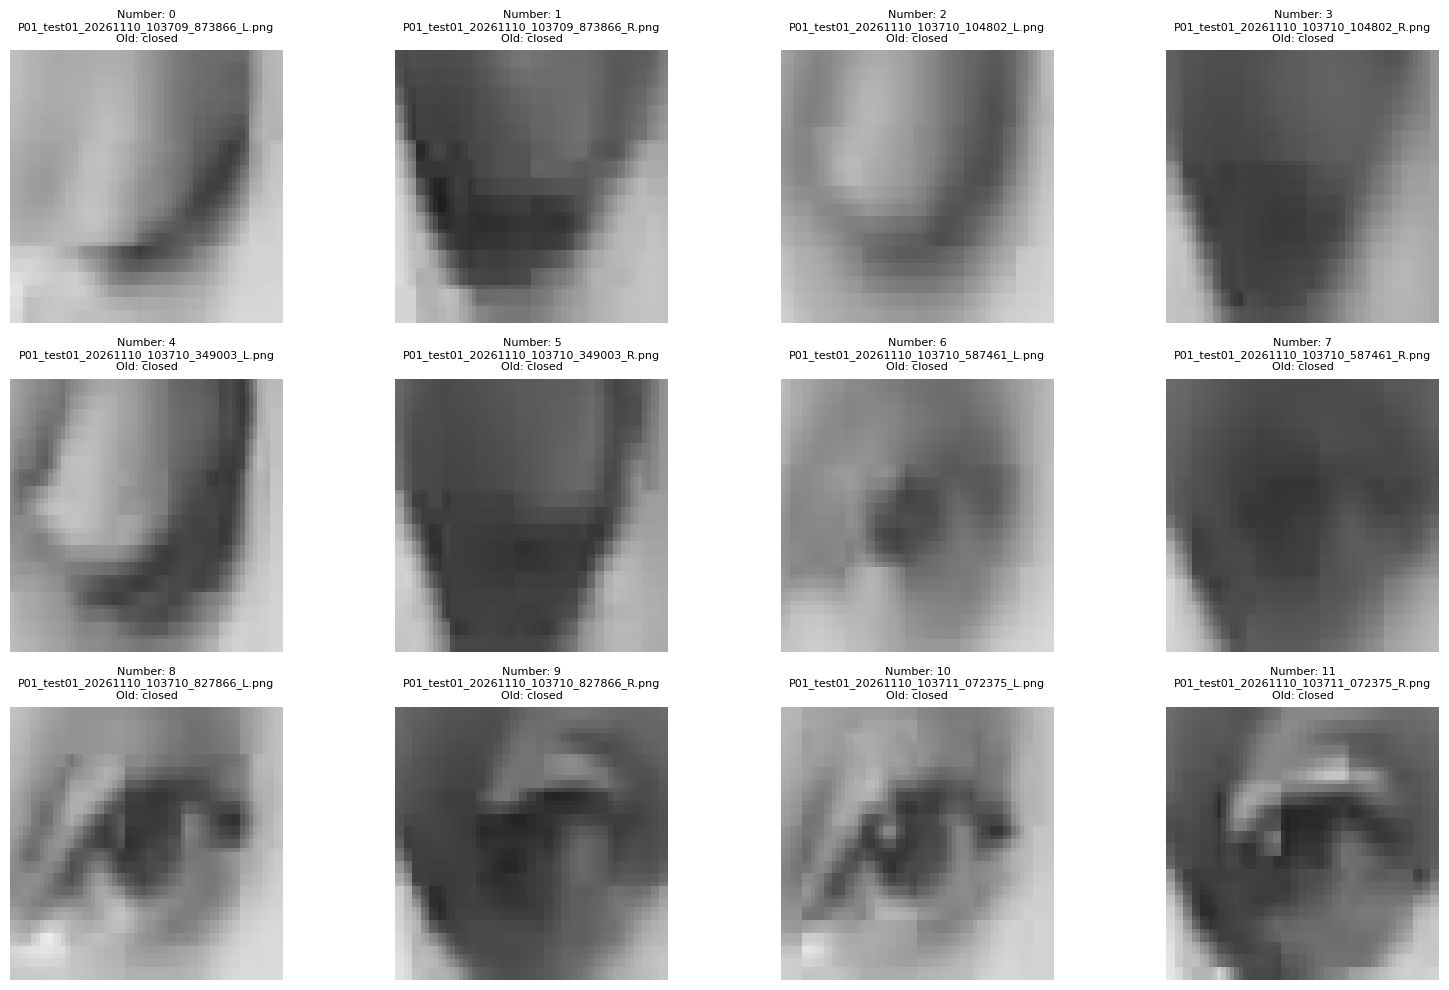

Review images 0 to 11


In [ ]:
review_batch(start=0)

In [ ]:
for label in ["open", "closed", "skip"]:
    folder = OUT / label
    print(label, ":", len(list(folder.iterdir())))


open : 0
closed : 0
skip : 0


In [ ]:
from pathlib import Path
import shutil

BASE = Path("/content/SmartCap_New_Data/data_raw/P01/test01")
OUT = Path("/content/SmartCap_Review_v2")

source = next((BASE / "open").glob("*.png"))

destination = OUT / "open" / source.name

destination.parent.mkdir(parents=True, exist_ok=True)

shutil.copy2(source, destination)

print("Source:", source)
print("Destination:", destination)
print("Saved successfully:", destination.exists())

Source: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_104505_680575_L.png
Destination: /content/SmartCap_Review_v2/open/P01_test01_20261110_104505_680575_L.png
Saved successfully: True


In [ ]:
for label in ["open", "closed", "skip"]:
    folder = OUT / label
    print(label, ":", len(list(folder.iterdir())))

open : 1
closed : 0
skip : 0


In [ ]:
import shutil
from pathlib import Path

OUT = Path("/content/SmartCap_Review_v2")

if OUT.exists():
    shutil.rmtree(OUT)

for label in ["open", "closed", "skip"]:
    (OUT / label).mkdir(parents=True)

print("Review folders ready!")

Review folders ready!


In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import shutil
import csv

BASE = Path("/content/SmartCap_New_Data/data_raw/P01/test01")

images = []
for folder in ["open", "closed"]:
    for ext in ["*.jpg", "*.jpeg", "*.png"]:
        images.extend((BASE / folder).glob(ext))

images = sorted(images)

OUT = Path("/content/SmartCap_Review_v2")
CSV_FILE = OUT / "review_log.csv"

def show_batch(start, size=12):
    batch = images[start:start+size]

    fig, axes = plt.subplots(3, 4, figsize=(16, 10))
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < len(batch):
            img = Image.open(batch[i]).convert("RGB")
            ax.imshow(img)
            ax.set_title(
                f"IMAGE {start+i}\n{batch[i].name}",
                fontsize=8
            )

    plt.tight_layout()
    plt.show()

def save_batch(start, labels):
    labels = labels.upper().replace(" ", "").replace(",", "")

    batch = images[start:start+len(labels)]

    if len(labels) != len(batch):
        print("Number of labels must match number of images.")
        return

    if any(x not in "OCS" for x in labels):
        print("Use only O, C, S.")
        return

    records = []

    for i, (path, code) in enumerate(zip(batch, labels)):
        label = {"O": "open", "C": "closed", "S": "skip"}[code]

        destination = OUT / label / f"{start+i:03d}_{path.name}"
        shutil.copy2(path, destination)

        records.append({
            "image_number": start+i,
            "filename": path.name,
            "original_folder": path.parent.name,
            "correct_label": label
        })

    write_header = not CSV_FILE.exists()

    with open(CSV_FILE, "a", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=records[0].keys())
        if write_header:
            writer.writeheader()
        writer.writerows(records)

    print(f"Saved images {start} to {start+len(batch)-1}")

print("Total images:", len(images))

Total images: 94


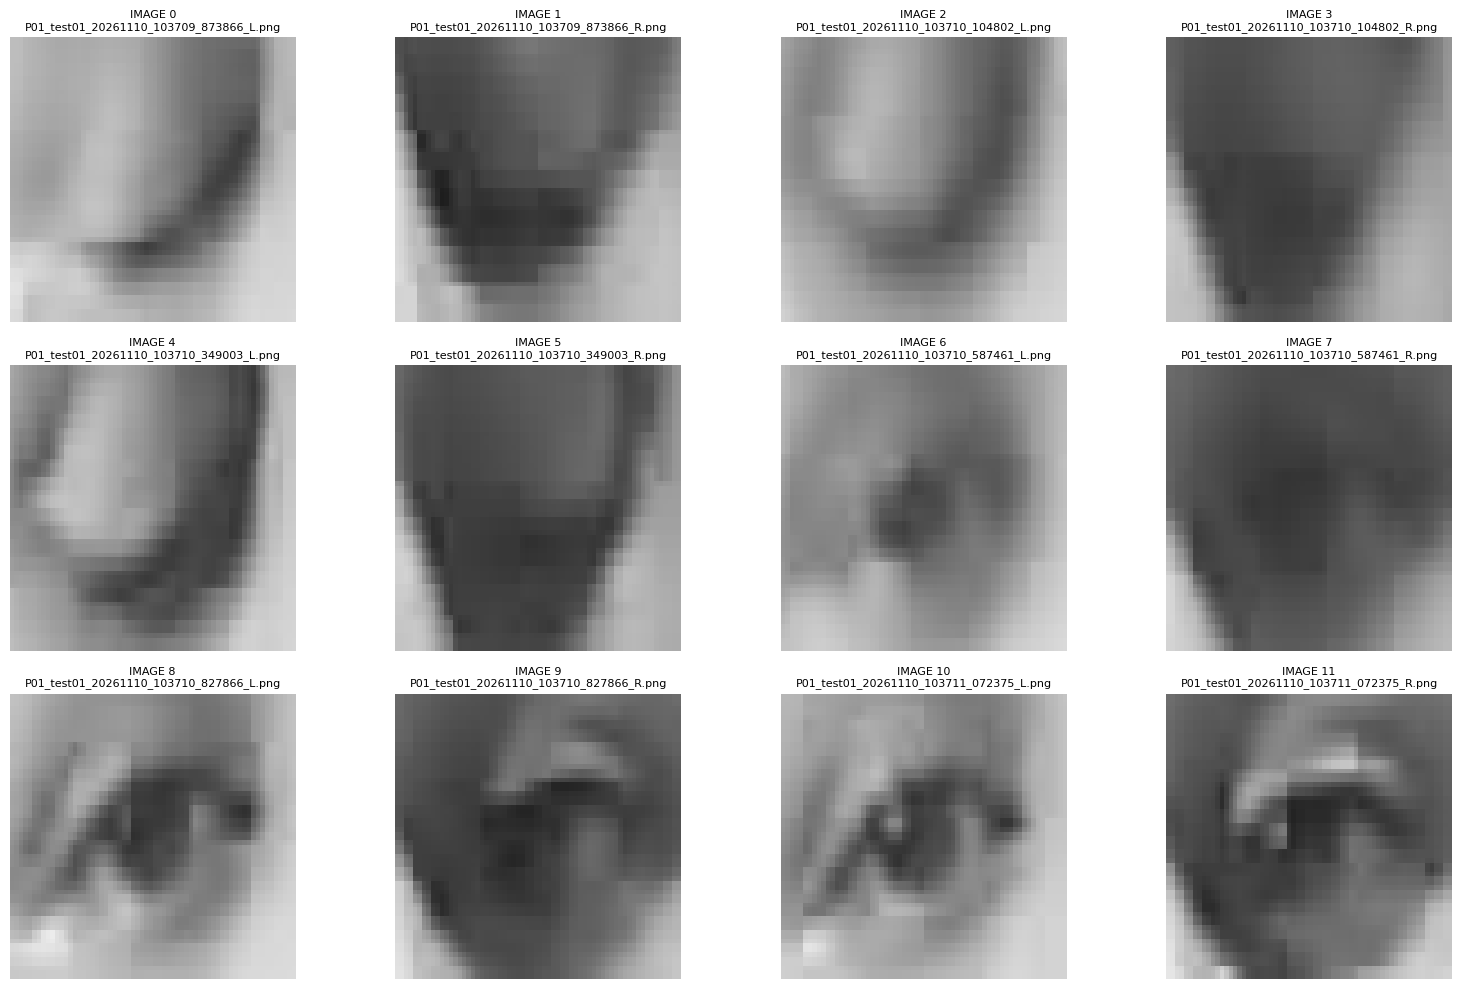

In [ ]:
show_batch(0)

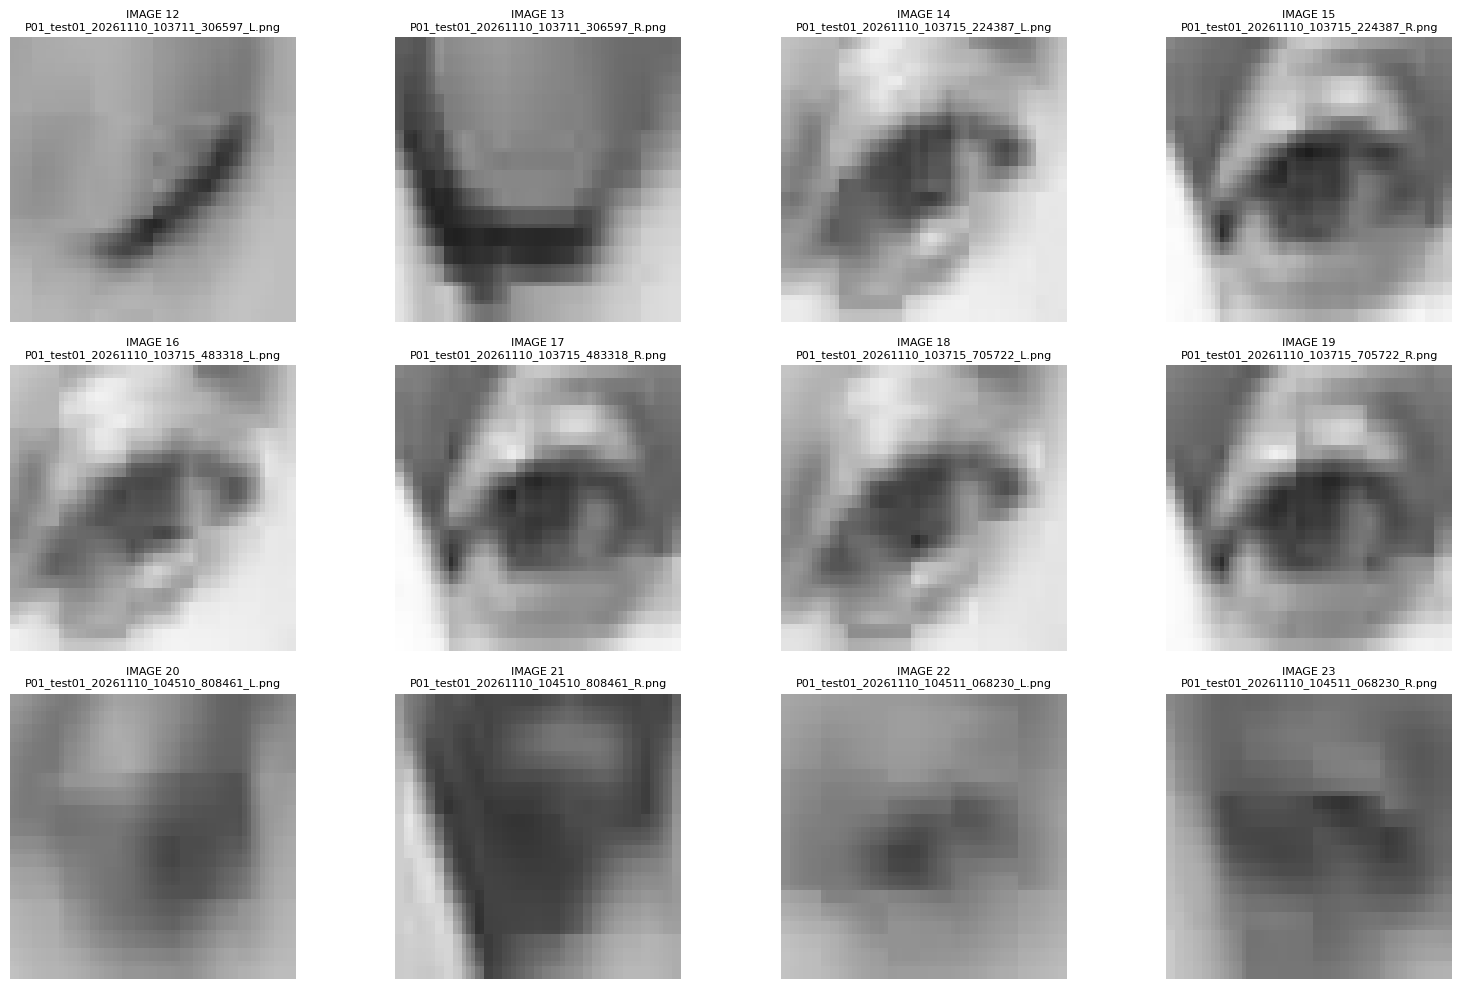

In [ ]:
show_batch(12)

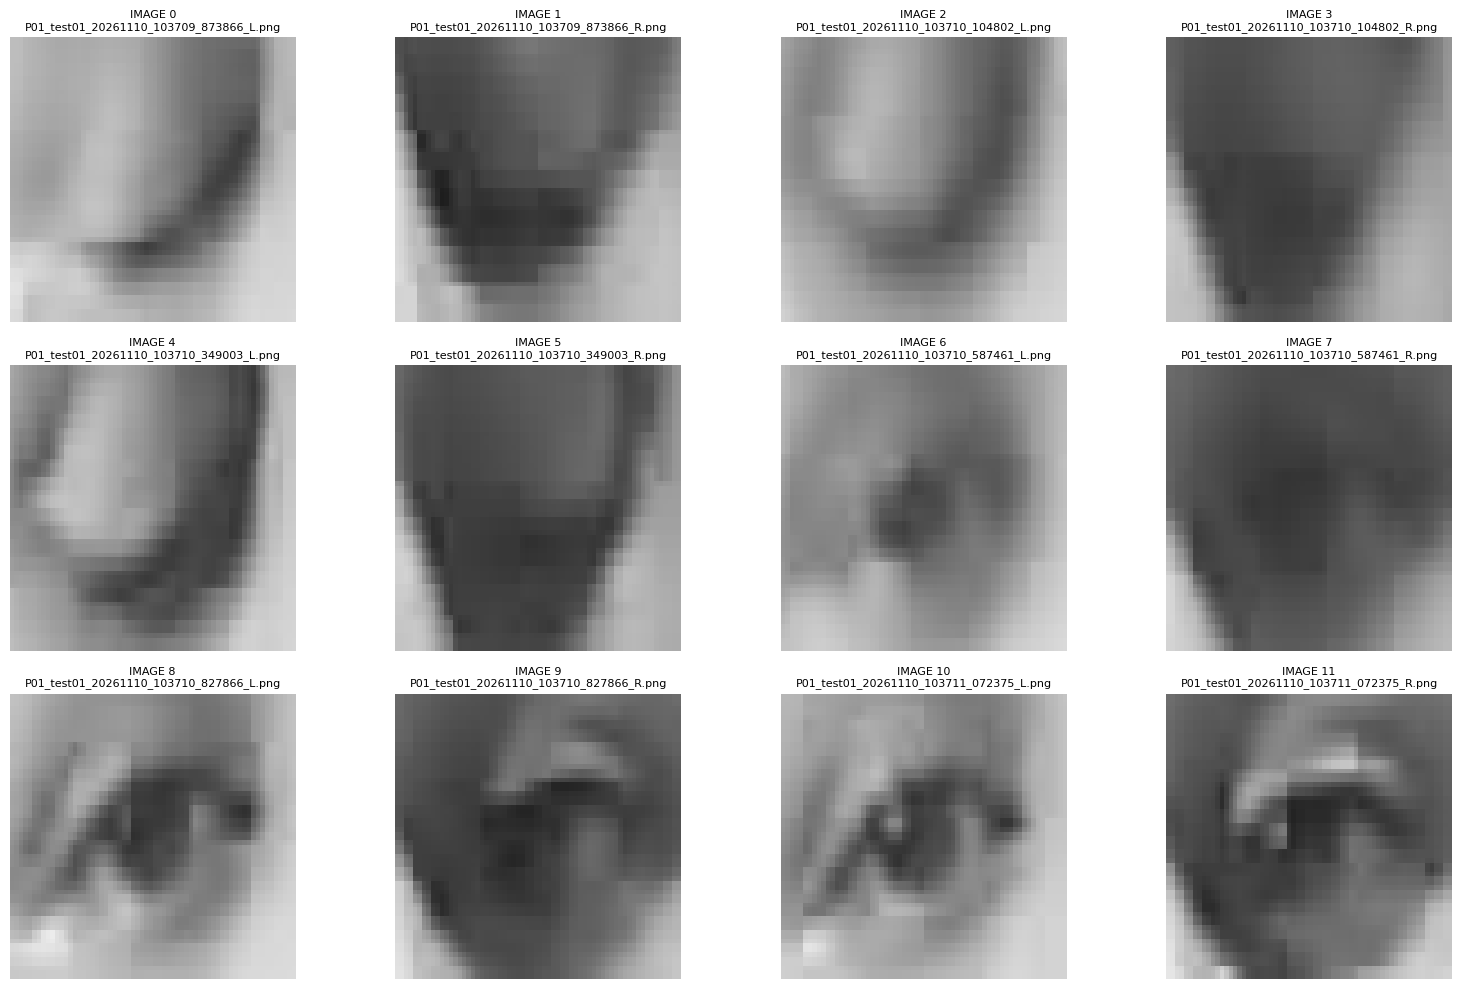

In [ ]:
show_batch(0)

In [ ]:
save_batch(0, "OOCO")

Saved images 0 to 3


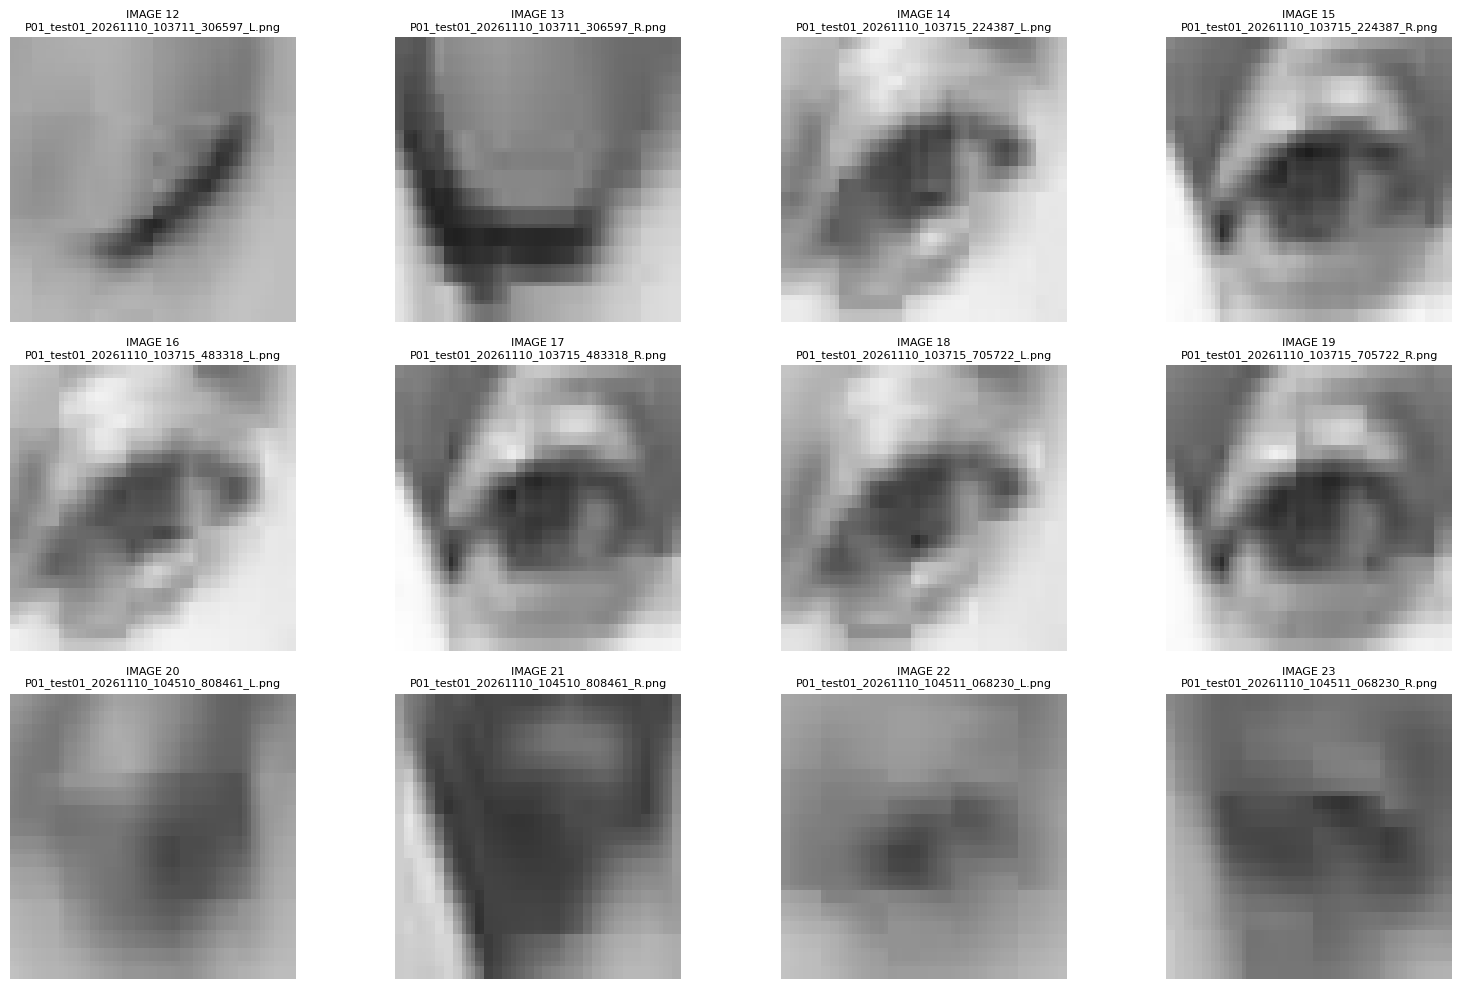

In [ ]:
show_batch(12)

In [ ]:
save_batch(12, "اكتب التصنيفات هنا")

Use only O, C, S.


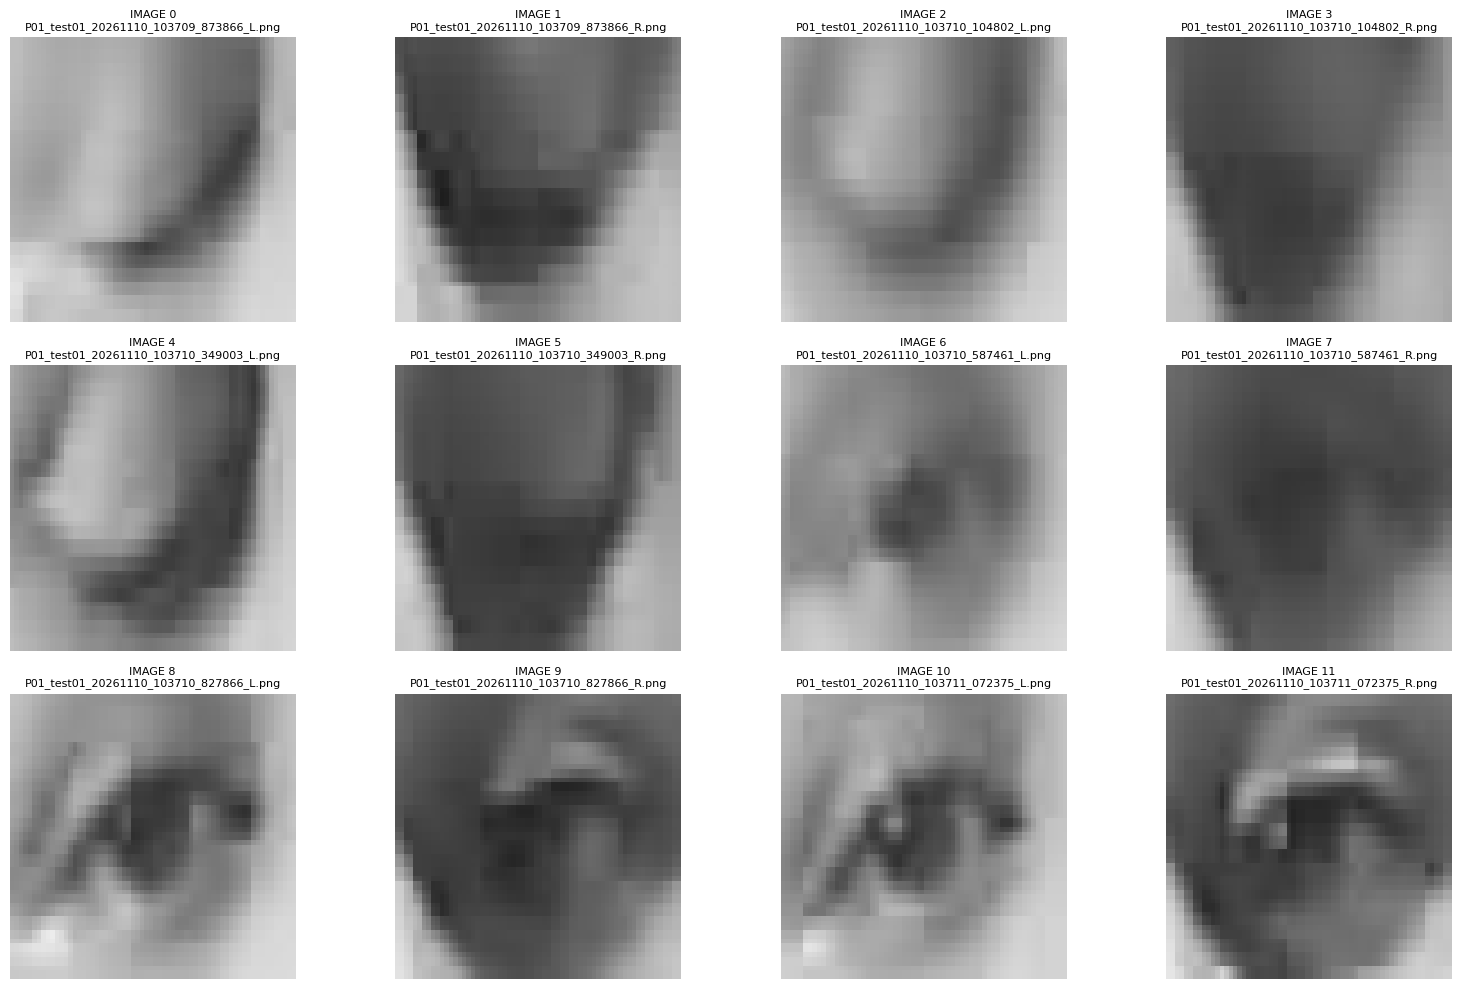

In [ ]:
show_batch(0)

In [ ]:
save_batch(0, "ccccccoooooo")

Saved images 0 to 11


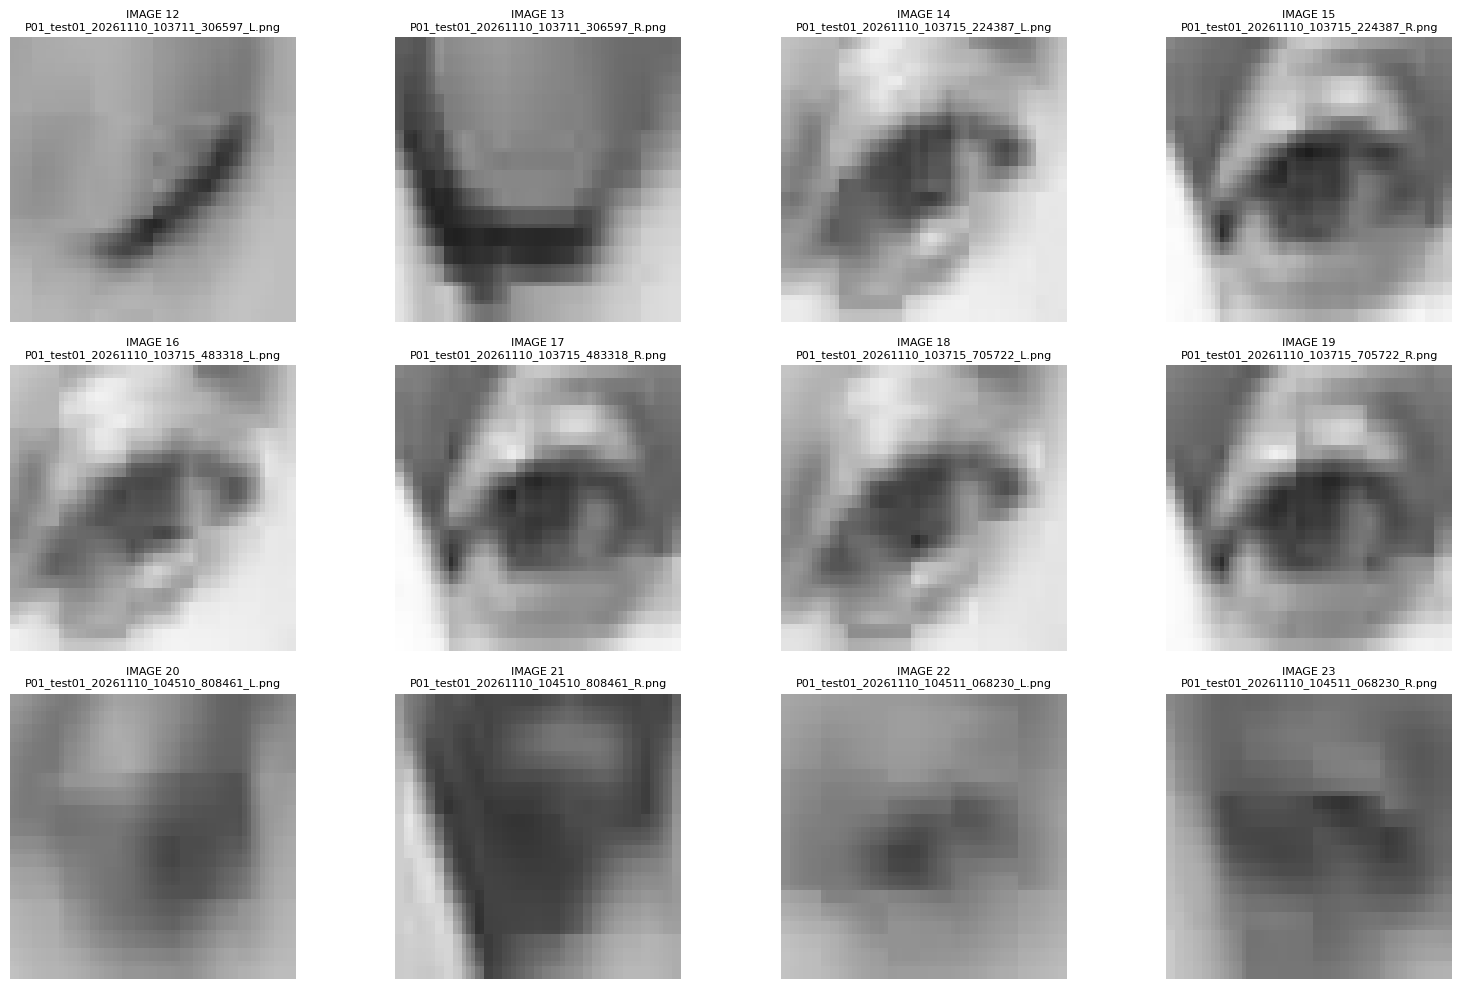

In [ ]:
show_batch(12)

In [ ]:
save_batch(12, "ccoooooocccc")

Saved images 12 to 23


In [ ]:
for label in ["open", "closed", "skip"]:
    folder = OUT / label
    print(label, ":", len(list(folder.iterdir())))


open : 15
closed : 12
skip : 0


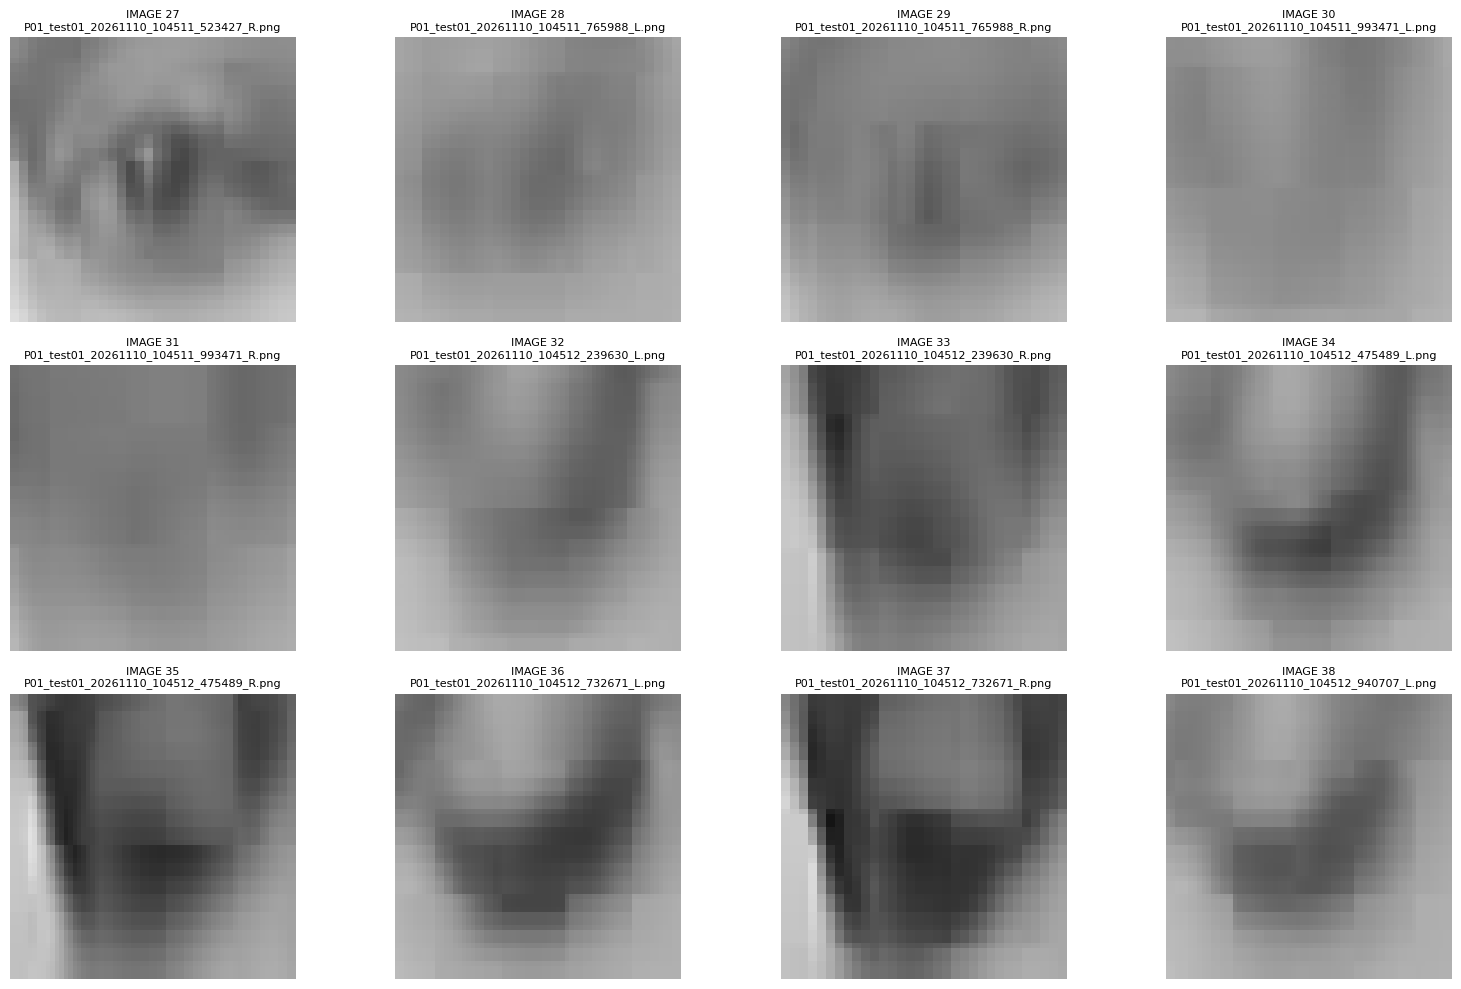

In [ ]:
show_batch(27)

In [ ]:
save_batch(27, " osssssssssss")

Saved images 27 to 38


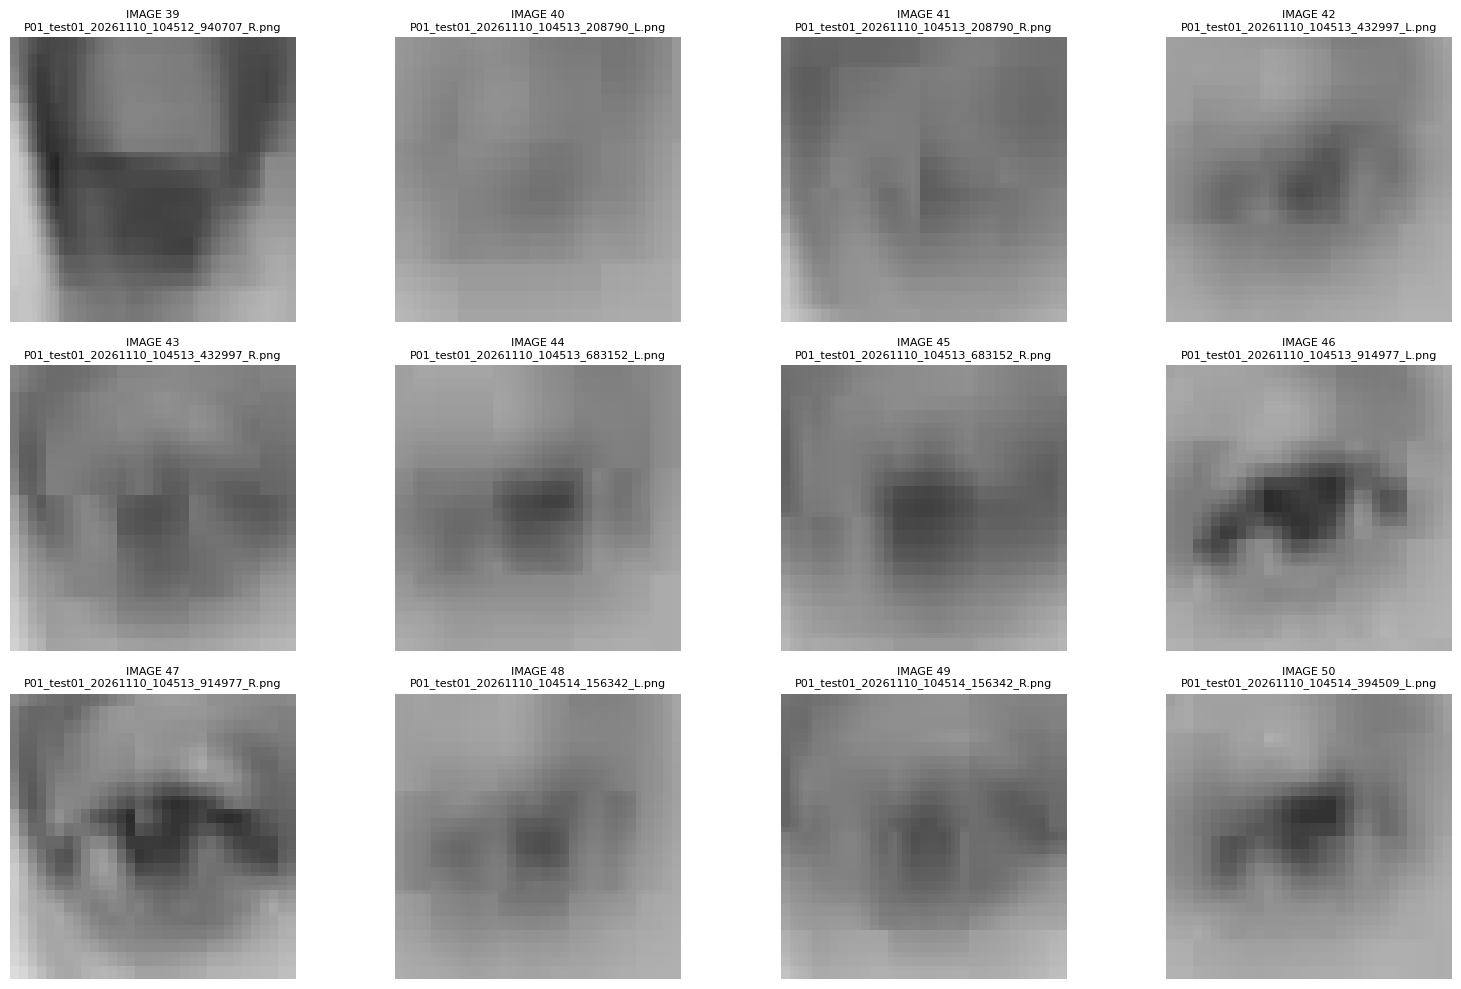

In [ ]:
show_batch(39)

In [ ]:
save_batch(39, "sssoooooosso")

Saved images 39 to 50


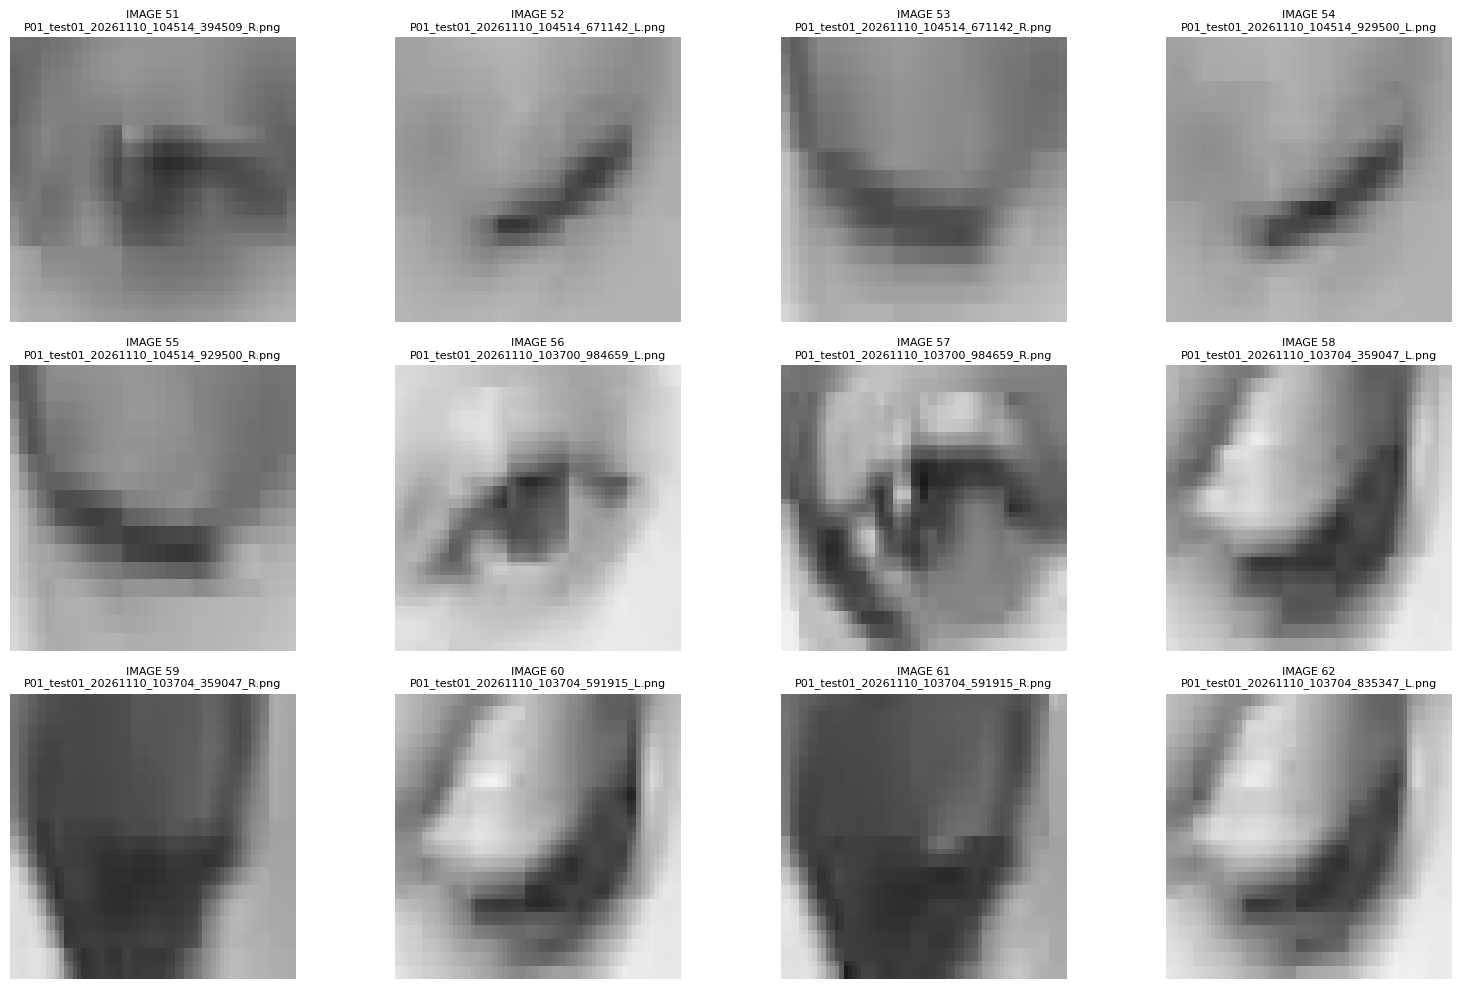

In [ ]:
show_batch(51)


In [ ]:
save_batch(51, "occccoocsooo")

Saved images 51 to 62


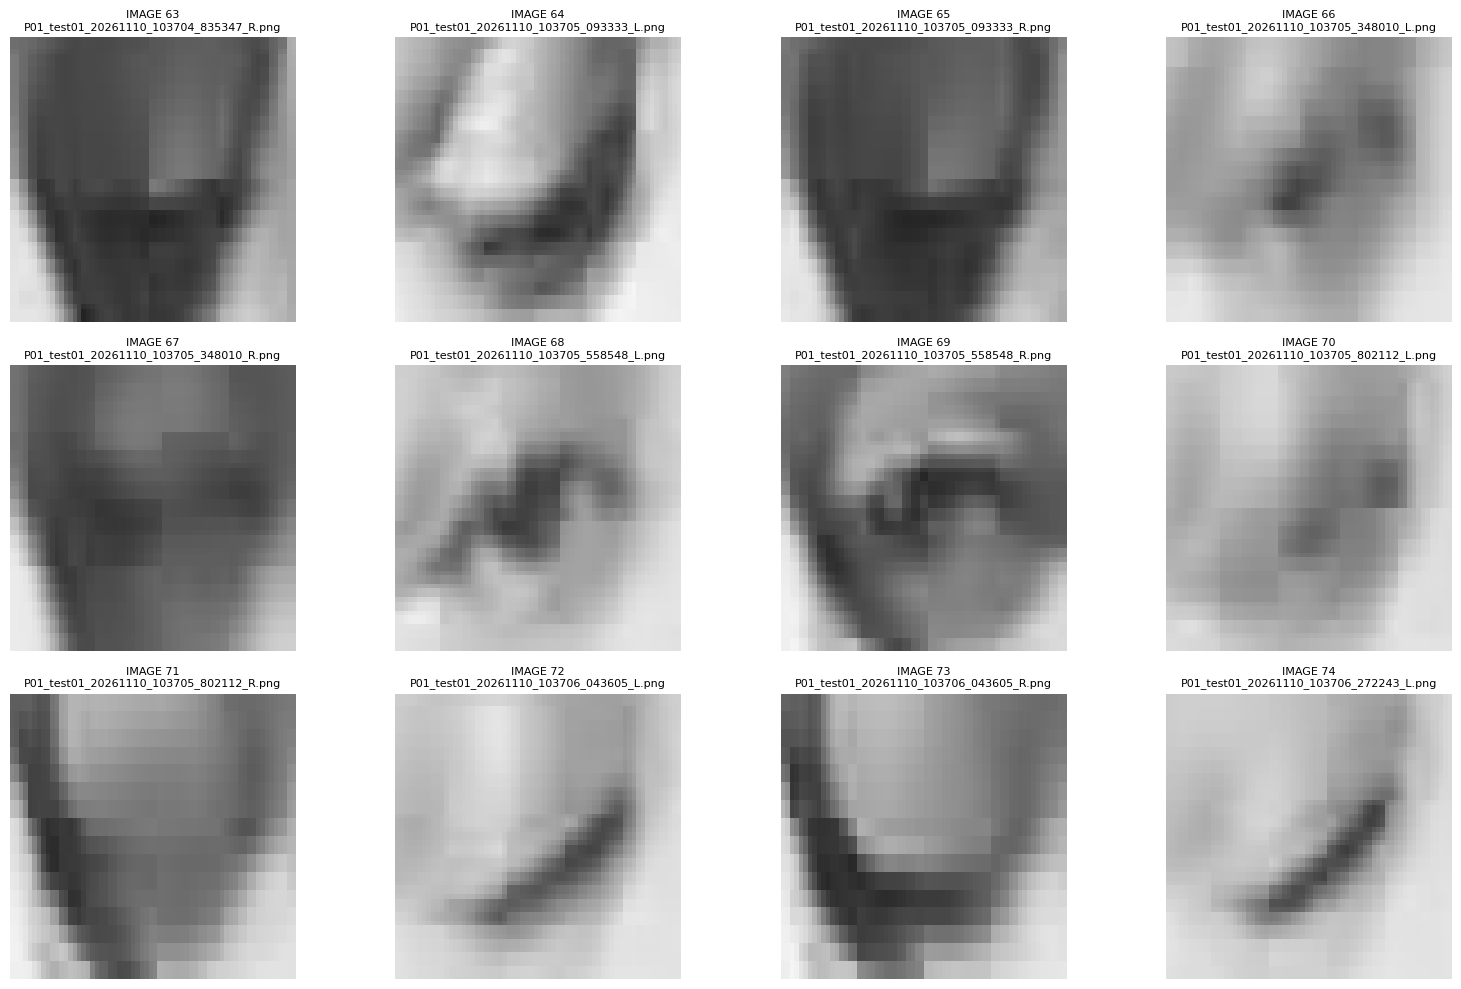

In [ ]:
show_batch(63)


In [ ]:
save_batch(63, "oooosoossccc")

Saved images 63 to 74


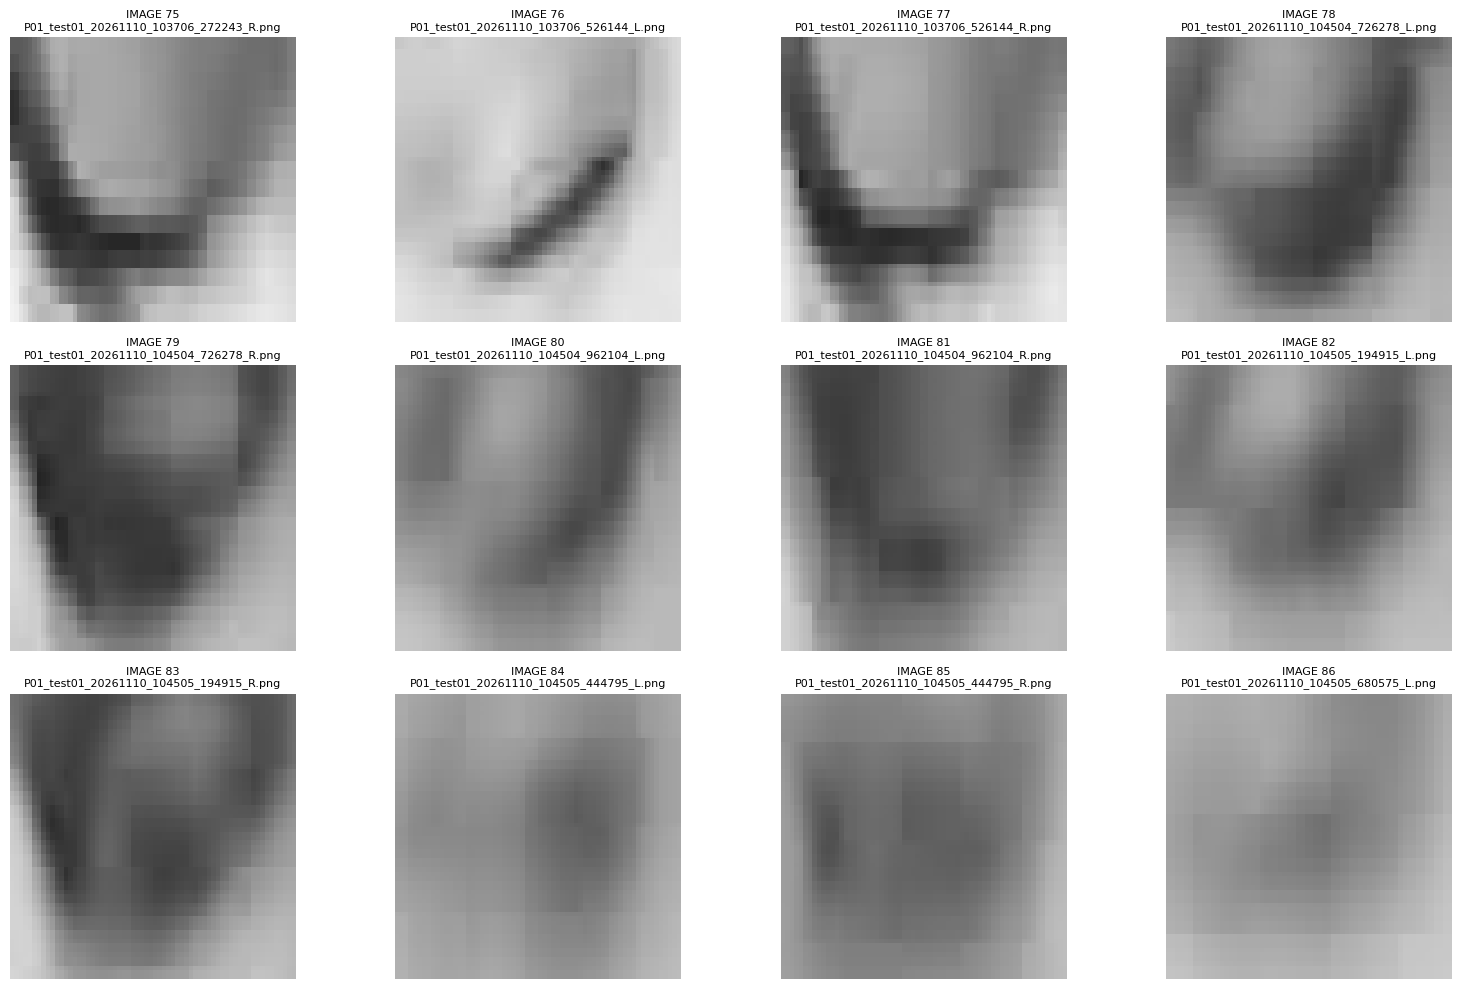

In [ ]:
show_batch(75)

In [ ]:
save_batch(75, "ccccssssssss")

Saved images 75 to 86


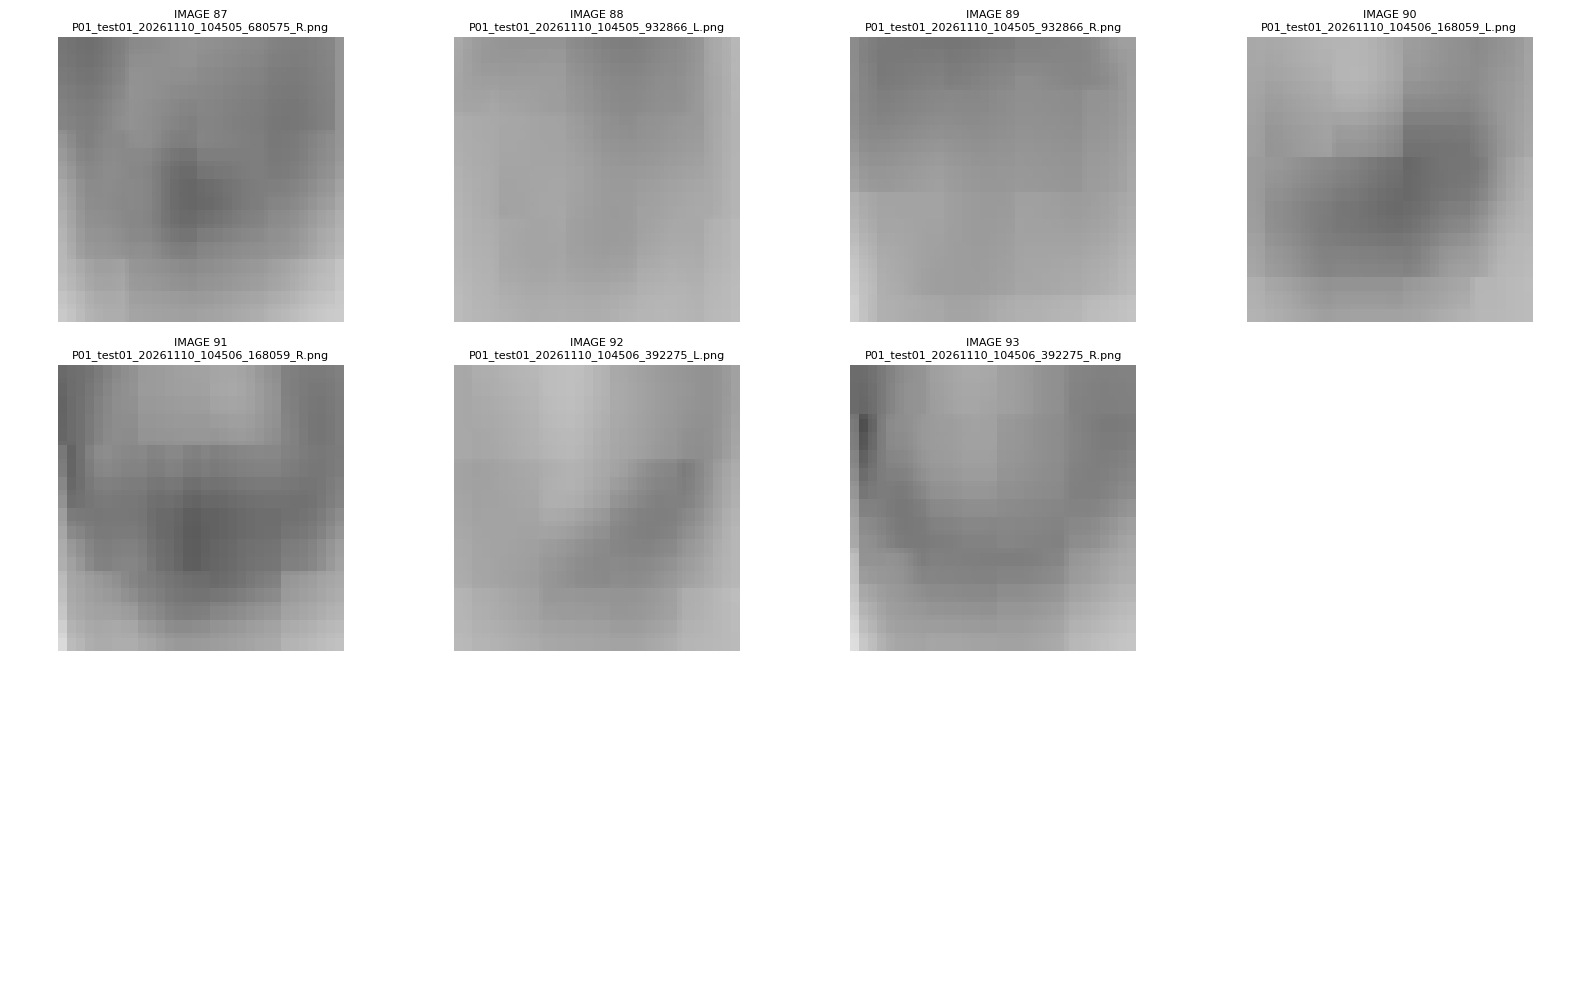

In [ ]:
show_batch(87)


In [ ]:
save_batch(87, "sssssss")

Saved images 87 to 93


In [ ]:
from pathlib import Path
import pandas as pd

OUT = Path("/content/SmartCap_Review_v2")
csv_path = OUT / "review_log.csv"

if not csv_path.exists():
    print("ERROR: review_log.csv not found!")
else:
    df = pd.read_csv(csv_path)

    print("Total reviewed records:", len(df))
    print("Unique image numbers:", df["image_number"].nunique())
    print("Duplicate records:", df["image_number"].duplicated().sum())

    print("\nLabels:")
    print(df["correct_label"].value_counts())

    print("\nMissing image numbers:")
    reviewed = set(df["image_number"].astype(int))
    missing = sorted(set(range(94)) - reviewed)
    print(missing if missing else "None")

    print("\nSaved folders:")
    for label in ["open", "closed", "skip"]:
        folder = OUT / label
        count = len(list(folder.glob("*"))) if folder.exists() else 0
        print(f"{label}: {count}")

Total reviewed records: 95
Unique image numbers: 91
Duplicate records: 4

Labels:
correct_label
open      35
skip      35
closed    25
Name: count, dtype: int64

Missing image numbers:
[24, 25, 26]

Saved folders:
open: 35
closed: 24
skip: 35


In [ ]:
import pandas as pd
from pathlib import Path

OUT = Path("/content/SmartCap_Review_v2")
df = pd.read_csv(OUT / "review_log.csv")

print("=== DUPLICATE IMAGE NUMBERS ===")

duplicates = df[
    df.duplicated(subset=["image_number"], keep=False)
].sort_values("image_number")

print(duplicates.to_string(index=False))

print("\n=== MISSING IMAGES ===")

reviewed = set(df["image_number"].astype(int))
missing = sorted(set(range(94)) - reviewed)

print(missing)

print("\n=== CLOSED LABEL CHECK ===")

closed_rows = df[df["correct_label"] == "closed"]
print(closed_rows.to_string(index=False))

=== DUPLICATE IMAGE NUMBERS ===
 image_number                                filename original_folder correct_label
            0 P01_test01_20261110_103709_873866_L.png          closed          open
            0 P01_test01_20261110_103709_873866_L.png          closed        closed
            1 P01_test01_20261110_103709_873866_R.png          closed        closed
            1 P01_test01_20261110_103709_873866_R.png          closed          open
            2 P01_test01_20261110_103710_104802_L.png          closed        closed
            2 P01_test01_20261110_103710_104802_L.png          closed        closed
            3 P01_test01_20261110_103710_104802_R.png          closed          open
            3 P01_test01_20261110_103710_104802_R.png          closed        closed

=== MISSING IMAGES ===
[24, 25, 26]

=== CLOSED LABEL CHECK ===
 image_number                                filename original_folder correct_label
            2 P01_test01_20261110_103710_104802_L.png          

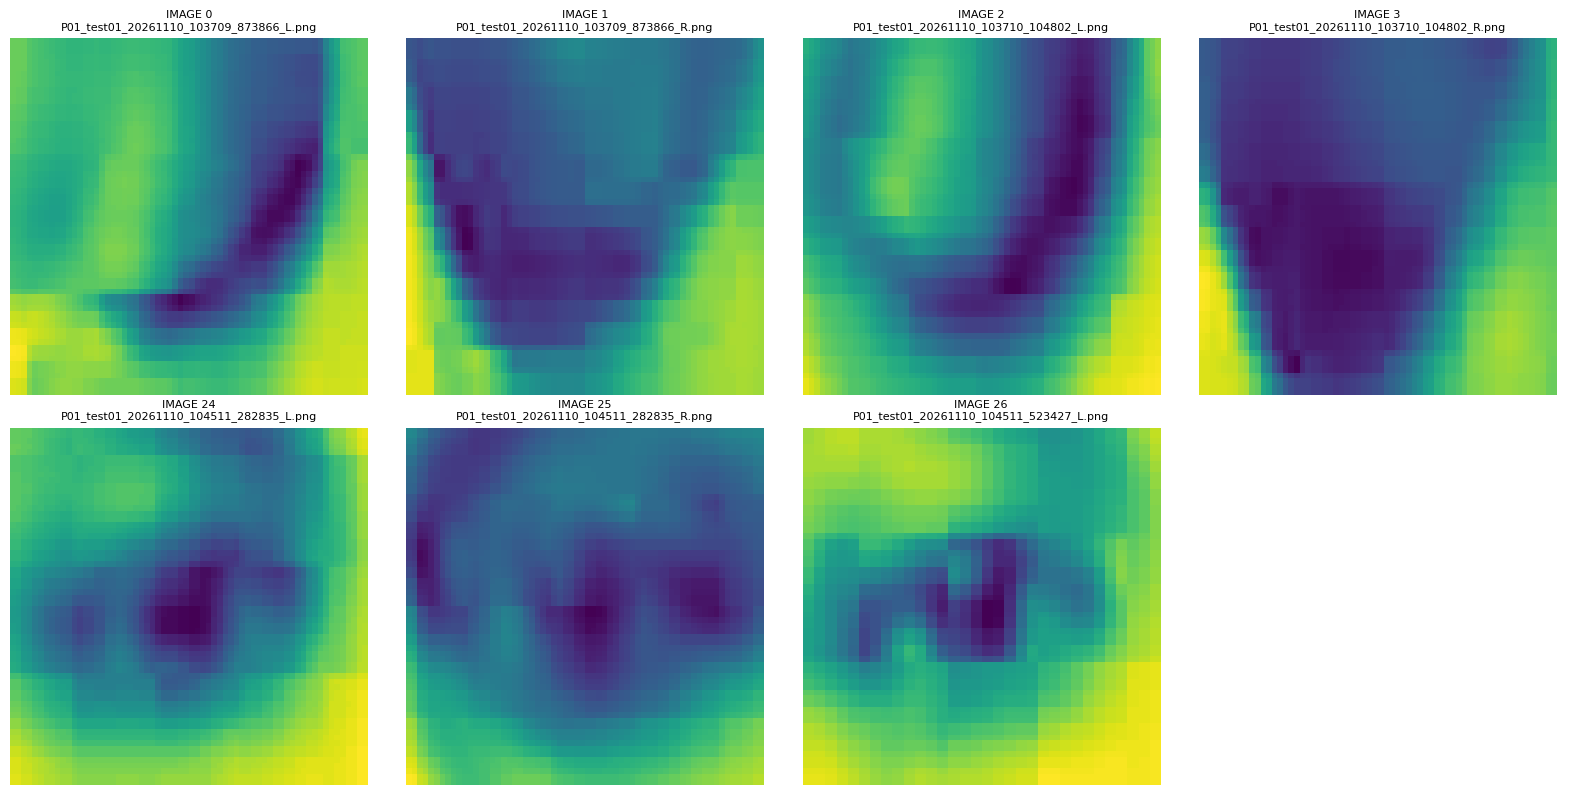

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

BASE = Path("/content/SmartCap_New_Data/data_raw/P01/test01")

images = []

for folder in ["open", "closed"]:
    for ext in ["*.jpg", "*.jpeg", "*.png"]:
        images.extend((BASE / folder).glob(ext))

images = sorted(images)

check_indices = [0, 1, 2, 3, 24, 25, 26]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, idx in zip(axes, check_indices):
    img_path = images[idx]
    img = Image.open(img_path)

    ax.imshow(img)
    ax.set_title(f"IMAGE {idx}\n{img_path.name}", fontsize=8)
    ax.axis("off")

axes[7].axis("off")
plt.tight_layout()
plt.show()

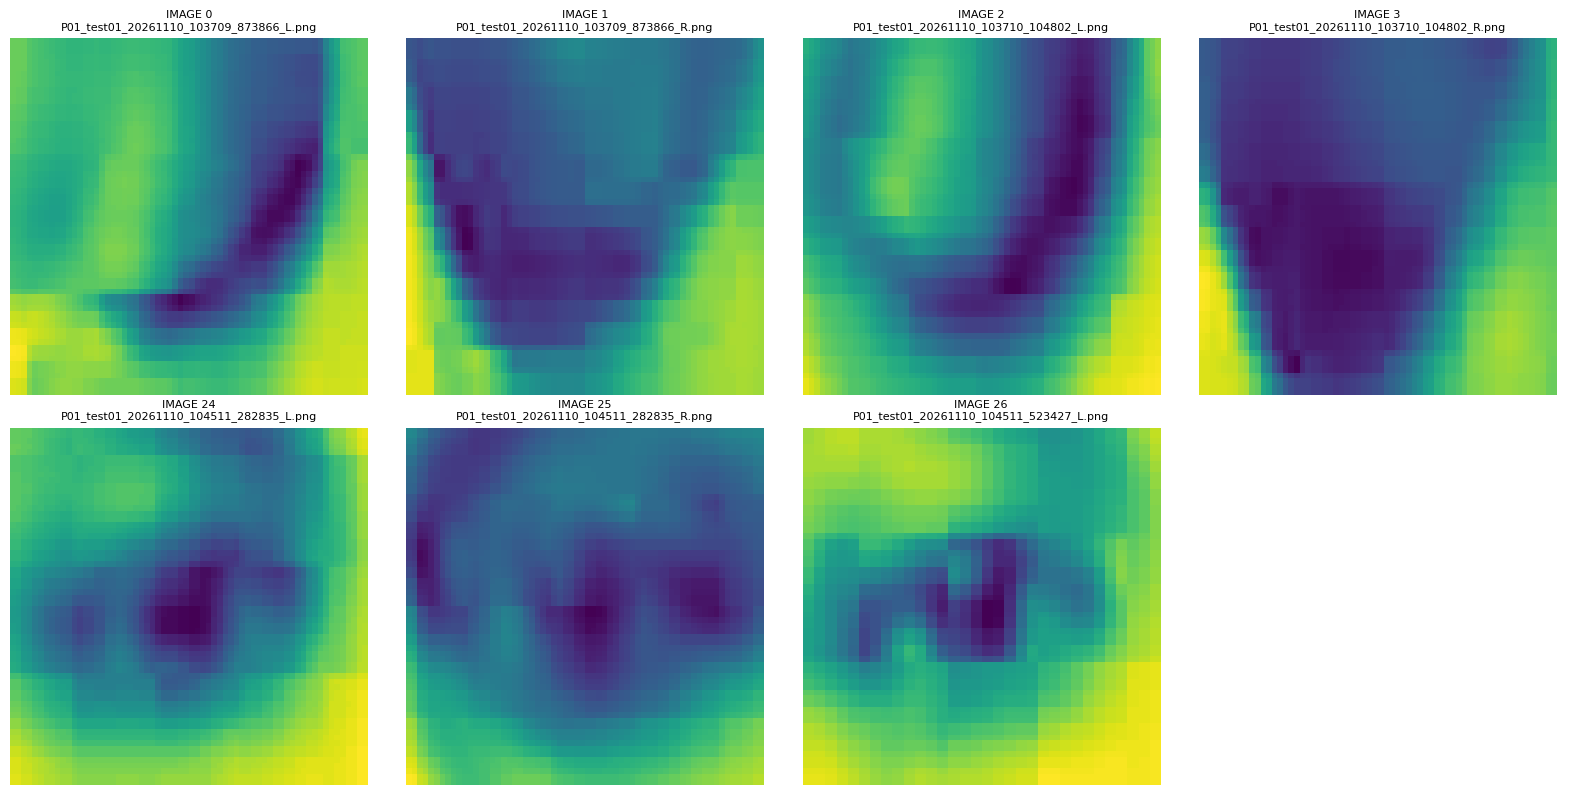

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

check_indices = [0, 1, 2, 3, 24, 25, 26]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, idx in zip(axes, check_indices):
    img_path = images[idx]
    ax.imshow(Image.open(img_path))
    ax.set_title(f"IMAGE {idx}\n{img_path.name}", fontsize=8)
    ax.axis("off")

axes[7].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
labels = input("Enter 7 labels (O/C/S): ").strip().upper()

if len(labels) == 7 and all(x in "OCS" for x in labels):
    print("Labels received:", labels)
else:
    print("Invalid! Enter exactly 7 letters: O, C, S")

Enter 7 labels (O/C/S): cccsooo
Labels received: CCCSOOO


In [ ]:
import pandas as pd
import shutil
from pathlib import Path

BASE = Path("/content/SmartCap_New_Data/data_raw/P01/test01")
OUT = Path("/content/SmartCap_Review_v2")
CSV = OUT / "review_log.csv"

# 1. Rebuild the original image list in the same sorted order
images = []

for folder in ["open", "closed"]:
    for ext in ["*.jpg", "*.jpeg", "*.png"]:
        images.extend((BASE / folder).glob(ext))

images = sorted(images)

assert len(images) == 94, f"Expected 94 images, found {len(images)}"

# 2. Read the old review log
df = pd.read_csv(CSV)

# 3. Remove duplicate image numbers
df = df.drop_duplicates(subset=["image_number"], keep="last").copy()
df["image_number"] = df["image_number"].astype(int)

# 4. Apply your confirmed labels
corrections = {
    0: "closed",
    1: "closed",
    2: "closed",
    3: "skip",
    24: "open",
    25: "open",
    26: "open"
}

for idx, label in corrections.items():
    if idx in df["image_number"].values:
        df.loc[df["image_number"] == idx, "correct_label"] = label
    else:
        src = images[idx]
        df.loc[len(df)] = {
            "image_number": idx,
            "filename": src.name,
            "original_folder": src.parent.name,
            "correct_label": label
        }

# 5. Update filenames and original folders from source images
for idx in range(94):
    src = images[idx]
    mask = df["image_number"] == idx
    df.loc[mask, "filename"] = src.name
    df.loc[mask, "original_folder"] = src.parent.name

# 6. Sort and save corrected review log
df = df.sort_values("image_number").reset_index(drop=True)
df.to_csv(CSV, index=False)

# 7. Rebuild review folders from original images
for label in ["open", "closed", "skip"]:
    folder = OUT / label
    folder.mkdir(parents=True, exist_ok=True)

    for old_file in folder.iterdir():
        if old_file.is_file():
            old_file.unlink()

for _, row in df.iterrows():
    idx = int(row["image_number"])
    label = row["correct_label"]
    src = images[idx]

    if label not in ["open", "closed", "skip"]:
        raise ValueError(f"Invalid label at image {idx}: {label}")

    destination = OUT / label / f"{idx:03d}_{src.name}"
    shutil.copy2(src, destination)

# 8. Final verification
print("=== FINAL DATASET REVIEW ===")
print("Total records:", len(df))
print("Unique images:", df["image_number"].nunique())
print("Missing images:", sorted(set(range(94)) - set(df["image_number"])))

print("\nLabels:")
print(df["correct_label"].value_counts())

print("\nFolder counts:")
for label in ["open", "closed", "skip"]:
    print(label, ":", len(list((OUT / label).glob("*"))))

print("\nCorrection completed successfully!")

=== FINAL DATASET REVIEW ===
Total records: 91
Unique images: 91
Missing images: [24, 25, 90]

Labels:
correct_label
skip      35
open      33
closed    23
Name: count, dtype: int64

Folder counts:
open : 33
closed : 23
skip : 35

Correction completed successfully!


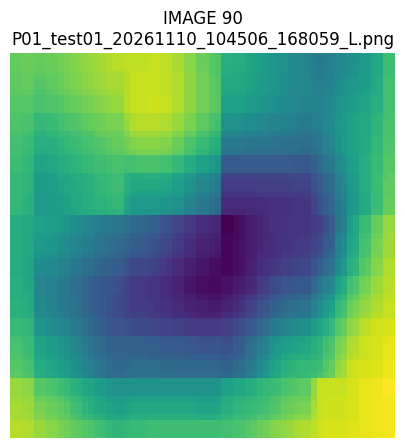

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

img_path = images[90]

plt.figure(figsize=(6, 5))
plt.imshow(Image.open(img_path))
plt.title(f"IMAGE 90\n{img_path.name}")
plt.axis("off")
plt.show()

In [ ]:
label_90 = input("Image 90 - O (Open), C (Closed), S (Skip): ").strip().upper()

if label_90 in ["O", "C", "S"]:
    print("Image 90 label:", label_90)
else:
    print("Invalid label. Run again and enter O, C, or S.")

Image 90 - O (Open), C (Closed), S (Skip): s
Image 90 label: S


In [ ]:
import pandas as pd
import shutil
from pathlib import Path

BASE = Path("/content/SmartCap_New_Data/data_raw/P01/test01")
OUT = Path("/content/SmartCap_Review_v2")
CSV = OUT / "review_log.csv"

# Original images
images = []

for folder in ["open", "closed"]:
    for ext in ["*.jpg", "*.jpeg", "*.png"]:
        images.extend((BASE / folder).glob(ext))

images = sorted(images)

assert len(images) == 94, f"Expected 94 images, found {len(images)}"

# Read existing labels
old_df = pd.read_csv(CSV)
old_df["image_number"] = old_df["image_number"].astype(int)

# Keep one label per image
labels = {}

for _, row in old_df.iterrows():
    labels[row["image_number"]] = row["correct_label"]

# Confirmed corrections
labels.update({
    0: "closed",
    1: "closed",
    2: "closed",
    3: "skip",
    24: "open",
    25: "open",
    26: "open",
    90: "skip"
})

# Check that every image has a valid label
assert all(i in labels for i in range(94)), "Some images still have no label!"
assert all(labels[i] in ["open", "closed", "skip"] for i in range(94))

# Rebuild complete CSV without duplicate indices
rows = []

for i, src in enumerate(images):
    rows.append({
        "image_number": i,
        "filename": src.name,
        "original_folder": src.parent.name,
        "correct_label": labels[i]
    })

df_final = pd.DataFrame(rows)
df_final.to_csv(CSV, index=False)

# Rebuild output folders
for label in ["open", "closed", "skip"]:
    folder = OUT / label
    folder.mkdir(parents=True, exist_ok=True)

    for file in folder.iterdir():
        if file.is_file():
            file.unlink()

# Copy images according to final labels
for i, src in enumerate(images):
    label = labels[i]
    destination = OUT / label / f"{i:03d}_{src.name}"
    shutil.copy2(src, destination)

# Final verification
print("TOTAL RECORDS:", len(df_final))
print("UNIQUE IMAGES:", df_final["image_number"].nunique())
print("MISSING:", sorted(set(range(94)) - set(df_final["image_number"])))
print("\nLABEL COUNTS:")
print(df_final["correct_label"].value_counts())

print("\nFOLDER COUNTS:")
for label in ["open", "closed", "skip"]:
    print(label, ":", len(list((OUT / label).glob("*"))))

TOTAL RECORDS: 94
UNIQUE IMAGES: 94
MISSING: []

LABEL COUNTS:
correct_label
skip      36
open      35
closed    23
Name: count, dtype: int64

FOLDER COUNTS:
open : 35
closed : 23
skip : 36


In [ ]:
from pathlib import Path
from collections import Counter

MRL = Path("/content/MRL_Eye_Dataset")

files = [
    p for p in MRL.rglob("*")
    if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
]

valid = []
invalid = []

for p in files:
    parts = p.stem.split("_")

    if len(parts) >= 5 and parts[4] in ["0", "1"]:
        valid.append((p, parts[0], parts[4]))
    else:
        invalid.append(p)

print("=== MRL DATASET CHECK ===")
print("Total images:", len(files))
print("Valid images:", len(valid))
print("Invalid images:", len(invalid))

print("\nClasses:")
print("Closed:", sum(1 for p, s, label in valid if label == "0"))
print("Open:", sum(1 for p, s, label in valid if label == "1"))

print("\nUnique subjects:", len(set(s for p, s, label in valid)))
print("Subject examples:", sorted(set(s for p, s, label in valid))[:10])

print("\nExample filenames:")
for p, s, label in valid[:5]:
    print(p.name, "| Subject:", s, "| Label:", label)

=== MRL DATASET CHECK ===
Total images: 84898
Valid images: 84898
Invalid images: 0

Classes:
Closed: 41946
Open: 42952

Unique subjects: 37
Subject examples: ['s0001', 's0002', 's0003', 's0004', 's0005', 's0006', 's0007', 's0008', 's0009', 's0010']

Example filenames:
s0010_00397_0_0_1_0_0_01.png | Subject: s0010 | Label: 1
s0010_00043_0_0_0_0_0_01.png | Subject: s0010 | Label: 0
s0010_00374_0_0_1_0_0_01.png | Subject: s0010 | Label: 1
s0010_00120_0_0_0_0_0_01.png | Subject: s0010 | Label: 0
s0010_00209_0_0_0_0_0_01.png | Subject: s0010 | Label: 0


In [ ]:
import pandas as pd
import shutil
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

# =====================================
# 1. Define paths
# =====================================

MRL = Path("/content/MRL_Eye_Dataset")
SMARTCAP = Path("/content/SmartCap_New_Data/data_raw/P01/test01")
REVIEW = Path("/content/SmartCap_Review_v2")
DATASET = Path("/content/SmartCap_Eye_Classification")

# =====================================
# 2. Read MRL images and labels
# =====================================

mrl_rows = []

for p in MRL.rglob("*"):
    if p.suffix.lower() not in [".png", ".jpg", ".jpeg"]:
        continue

    parts = p.stem.split("_")

    if len(parts) >= 5 and parts[4] in ["0", "1"]:
        label = "closed" if parts[4] == "0" else "open"

        mrl_rows.append({
            "path": p,
            "subject": parts[0],
            "label": label
        })

mrl_df = pd.DataFrame(mrl_rows)

print("MRL images:", len(mrl_df))
print(mrl_df["label"].value_counts())

# =====================================
# 3. Split MRL by subjects
# =====================================

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        mrl_df,
        groups=mrl_df["subject"]
    )
)

train_df = mrl_df.iloc[train_idx]
val_df = mrl_df.iloc[val_idx]

train_subjects = set(train_df["subject"])
val_subjects = set(val_df["subject"])

assert len(train_subjects & val_subjects) == 0

print("\nMRL Train:", len(train_df))
print("MRL Validation:", len(val_df))
print("Train subjects:", len(train_subjects))
print("Validation subjects:", len(val_subjects))
print("Subject overlap:", train_subjects & val_subjects)

# =====================================
# 4. Read reviewed SmartCap images
# =====================================

review_df = pd.read_csv(REVIEW / "review_log.csv")

review_df = review_df[
    review_df["correct_label"].isin(["open", "closed"])
].copy()

assert len(review_df) == 58
assert review_df["image_number"].nunique() == 58

smartcap_images = []

for folder in ["open", "closed"]:
    for ext in ["*.jpg", "*.jpeg", "*.png"]:
        smartcap_images.extend((SMARTCAP / folder).glob(ext))

smartcap_images = sorted(smartcap_images)

assert len(smartcap_images) == 94

# =====================================
# 5. Create YOLO folders
# =====================================

if DATASET.exists():
    shutil.rmtree(DATASET)

for split in ["train", "val", "test"]:
    for label in ["open", "closed"]:
        (DATASET / split / label).mkdir(
            parents=True,
            exist_ok=True
        )

# =====================================
# 6. Copy MRL training images
# =====================================

def copy_mrl(dataframe, split_name):
    for i, row in enumerate(dataframe.itertuples(index=False), 1):
        destination = DATASET / split_name / row.label / row.path.name
        shutil.copy2(row.path, destination)

        if i % 10000 == 0:
            print(f"{split_name}: copied {i} images")

copy_mrl(train_df, "train")
copy_mrl(val_df, "val")

# =====================================
# 7. Copy SmartCap external test images
# =====================================

for _, row in review_df.iterrows():
    idx = int(row["image_number"])
    label = row["correct_label"]

    source = smartcap_images[idx]

    destination = (
        DATASET / "test" / label /
        f"{idx:03d}_{source.name}"
    )

    shutil.copy2(source, destination)

# =====================================
# 8. Final verification
# =====================================

print("\n========== FINAL DATASET ==========")

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for label in ["open", "closed"]:
        count = len(list((DATASET / split / label).glob("*")))
        print(f"{label}: {count}")

print("\nDataset path:", DATASET)
print("Subject overlap:", len(train_subjects & val_subjects))
print("\nDATASET PREPARATION COMPLETED!")

MRL images: 84898
label
open      42952
closed    41946
Name: count, dtype: int64

MRL Train: 60756
MRL Validation: 24142
Train subjects: 29
Validation subjects: 8
Subject overlap: set()
train: copied 10000 images
train: copied 20000 images
train: copied 30000 images
train: copied 40000 images
train: copied 50000 images
train: copied 60000 images
val: copied 10000 images
val: copied 20000 images

========== FINAL DATASET ==========

TRAIN
open: 30516
closed: 30240

VAL
open: 12436
closed: 11706

TEST
open: 35
closed: 23

Dataset path: /content/SmartCap_Eye_Classification
Subject overlap: 0

DATASET PREPARATION COMPLETED!


In [ ]:
# Install Ultralytics if needed
!pip install -q ultralytics

import torch
from ultralytics import YOLO
from pathlib import Path

# Dataset path
DATASET = Path("/content/SmartCap_Eye_Classification")

# Check GPU
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Load YOLOv8 Classification pretrained model
model = YOLO("yolov8n-cls.pt")

# Start a NEW training run
results = model.train(
    data=str(DATASET),
    epochs=30,
    imgsz=224,
    batch=16,
    workers=2,
    device=0 if torch.cuda.is_available() else "cpu",
    project="/content/SmartCap_Training",
    name="eye_classification_v1",
    patience=8,
    seed=42,
    plots=True,
    save=True,
    verbose=True
)

print("\nTRAINING COMPLETED!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
CUDA Available: False
Ultralytics 8.4.208 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SmartCap_Eye_Classification, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, fo

KeyboardInterrupt: 

In [ ]:

!pip install -q ultralytics

import torch
from pathlib import Path
from ultralytics import YOLO

DATASET = Path("/content/SmartCap_Eye_Classification")

if not DATASET.exists():
    raise FileNotFoundError("Dataset not found. We need to rebuild it first.")

print("Training on CPU")
print("CUDA Available:", torch.cuda.is_available())

model = YOLO("yolov8n-cls.pt")

results = model.train(
    data=str(DATASET),
    epochs=5,
    imgsz=160,
    batch=8,
    workers=2,
    device="cpu",
    project="/content/SmartCap_Training",
    name="eye_classification_cpu",
    patience=3,
    seed=42,
    plots=True,
    save=True,
    verbose=True
)

print("Training completed!")


Training on CPU
CUDA Available: False
Ultralytics 8.4.208 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SmartCap_Eye_Classification, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=160, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=eye_clas

In [14]:
import tensorflow as tf
model = tf.keras.models.load_model("/content/best_eye_model.keras")
print("input:", model.input_shape, "| output:", model.output_shape)

input: (None, 64, 64, 1) | output: (None, 1)


In [15]:
import os
import numpy as np
import tensorflow as tf
from sklearn.metrics import confusion_matrix, balanced_accuracy_score

MODEL_PATH = "/content/best_eye_model.keras"

# تأكد إن كل الملفات موجودة قبل ما نكمّل
for f in (MODEL_PATH, "/content/mrl_64.npz", "/content/cap_64.npz"):
    print(("OK      " if os.path.exists(f) else "MISSING ") + f)
assert all(os.path.exists(f) for f in (MODEL_PATH, "/content/mrl_64.npz", "/content/cap_64.npz")), \
    "في ملف ناقص، شغّل الخلية الخاصة بيه الأول"

model = tf.keras.models.load_model(MODEL_PATH)
print("input:", model.input_shape, "| output:", model.output_shape)

m = np.load("/content/mrl_64.npz")
Xte_m, yte_m = m["Xte"], m["yte"]
c = np.load("/content/cap_64.npz")
Xte_c, yte_c = c["Xte"], c["yte"]

prep = lambda X: (X.astype("float32") / 255.0)[..., None]

def report(name, X, y, thr=0.5):
    p = model.predict(prep(X), verbose=0).ravel()
    pred = (p > thr).astype(int)
    cm = confusion_matrix(y, pred, labels=[0, 1])
    print(f"\n{name}: n={len(y)} | acc={(pred == y).mean():.3f} | balanced={balanced_accuracy_score(y, pred):.3f}")
    print("   open recall %.3f | closed recall %.3f" % (cm[0, 0] / max(1, cm[0].sum()), cm[1, 1] / max(1, cm[1].sum())))
    print("   [[open->open, open->closed], [closed->open, closed->closed]]:", cm.tolist())

report("MRL test (sanity check)", Xte_m, yte_m)
report("CAP test BEFORE fine-tuning", Xte_c, yte_c)

OK      /content/best_eye_model.keras
MISSING /content/mrl_64.npz
MISSING /content/cap_64.npz


AssertionError: في ملف ناقص، شغّل الخلية الخاصة بيه الأول

In [16]:
import os
from pathlib import Path

checks = {
    "الموديل":       "/content/best_eye_model.keras",
    "داتا MRL":      "/content/mrl_64.npz",
    "داتا الكاب":    "/content/cap_64.npz",
    "zip الـ MRL":   "/content/mrlEyes_2018_01.zip",
}
for name, path in checks.items():
    print(("OK      " if os.path.exists(path) else "MISSING "), name, "->", path)

R = Path("/content/SmartCap_Review_v1")
print("\nReview folder exists:", R.exists())
if R.exists():
    for lab in ("open", "closed", "skip"):
        n = sum(len(list((R / lab).glob(e))) for e in ("*.png", "*.jpg", "*.jpeg"))
        print("  ", lab, n)

OK       الموديل -> /content/best_eye_model.keras
MISSING  داتا MRL -> /content/mrl_64.npz
MISSING  داتا الكاب -> /content/cap_64.npz
OK       zip الـ MRL -> /content/mrlEyes_2018_01.zip

Review folder exists: False


In [17]:
!unzip -q -o /content/mrlEyes_2018_01.zip -d /content/mrl

import numpy as np, glob, os, random
from collections import defaultdict
from PIL import Image

root = "/content/mrl/mrlEyes_2018_01"
files = glob.glob(f"{root}/**/*.png", recursive=True)
print("images found:", len(files))

cnt = defaultdict(lambda: [0, 0])          # [open, closed]
for f in files:
    p = os.path.basename(f).split("_")
    cnt[p[0]][1 if p[4] == "0" else 0] += 1
subjects = sorted(cnt)
N = sum(sum(v) for v in cnt.values())
r_all = sum(v[1] for v in cnt.values()) / N

best = None
for seed in range(5000):
    s = subjects[:]; random.Random(seed).shuffle(s)
    parts = {"train": s[:27], "val": s[27:32], "test": s[32:]}
    score = 0
    for k in ("val", "test"):
        o = sum(cnt[x][0] for x in parts[k]); c = sum(cnt[x][1] for x in parts[k]); n = o + c
        score += abs(c / n - r_all) + 0.5 * abs(n / N - 0.10)
    if best is None or score < best[0]: best = (score, seed, parts)
split_subj = best[2]

def load(subj_list):
    S = set(subj_list); X, y = [], []
    for f in files:
        p = os.path.basename(f).split("_")
        if p[0] in S:
            X.append(np.asarray(Image.open(f).convert("L").resize((64, 64)), dtype=np.uint8))
            y.append(1 if p[4] == "0" else 0)          # 1 = closed, 0 = open
    return np.stack(X), np.array(y)

d = {k: load(v) for k, v in split_subj.items()}
for k, (X, y) in d.items():
    print(k, X.shape, "closed ratio %.2f" % y.mean())
np.savez_compressed("/content/mrl_64.npz", Xtr=d["train"][0], ytr=d["train"][1],
                    Xva=d["val"][0], yva=d["val"][1], Xte=d["test"][0], yte=d["test"][1])
print("saved")

images found: 84898
train (67372, 64, 64) closed ratio 0.49
val (8955, 64, 64) closed ratio 0.49
test (8571, 64, 64) closed ratio 0.52
saved


In [18]:
import numpy as np, tensorflow as tf
from sklearn.metrics import confusion_matrix, balanced_accuracy_score

model = tf.keras.models.load_model("/content/best_eye_model.keras")
print("input:", model.input_shape, "| output:", model.output_shape)

m = np.load("/content/mrl_64.npz")
Xte, yte = m["Xte"], m["yte"]
X = (Xte.astype("float32") / 255.0)[..., None]
p = model.predict(X, verbose=0).ravel()

for thr in (0.5, 0.45):
    pred = (p > thr).astype(int)
    cm = confusion_matrix(yte, pred, labels=[0, 1])
    print(f"\nthreshold {thr}: acc={(pred == yte).mean():.4f} | balanced={balanced_accuracy_score(yte, pred):.4f}")
    print("   open recall %.4f | closed recall %.4f" % (cm[0, 0] / cm[0].sum(), cm[1, 1] / cm[1].sum()))
    print("   confusion:", cm.tolist())

input: (None, 64, 64, 1) | output: (None, 1)

threshold 0.5: acc=0.9466 | balanced=0.9451
   open recall 0.9082 | closed recall 0.9820
   confusion: [[3740, 378], [80, 4373]]

threshold 0.45: acc=0.9442 | balanced=0.9426
   open recall 0.9014 | closed recall 0.9838
   confusion: [[3712, 406], [72, 4381]]


In [19]:
from pathlib import Path
import os

print("Top level:", sorted(os.listdir("/content")))
print()
for p in sorted(Path("/content").rglob("*")):
    if p.is_dir() and p.name in ("open", "closed") and "mrl" not in str(p).lower():
        n = sum(len(list(p.glob(e))) for e in ("*.png", "*.jpg", "*.jpeg"))
        print(p, "->", n, "images")

Top level: ['.config', 'MRL_Eye_Dataset', 'SmartCap_New_Data', 'best_eye_model.keras', 'data_raw.rar', 'mrl', 'mrlEyes_2018_01.zip', 'mrl_64.npz', 'sample_data']



In [20]:
from pathlib import Path
from collections import Counter

root = Path("/content/SmartCap_New_Data")
print("exists:", root.exists())
exts = Counter(p.suffix.lower() for p in root.rglob("*") if p.is_file())
print("file types:", dict(exts))
print()
for d in sorted(p for p in root.rglob("*") if p.is_dir()):
    n = sum(1 for f in d.iterdir() if f.is_file())
    print(d.relative_to(root), "->", n, "files")

exists: True
file types: {}



In [21]:
!apt-get -qq install -y p7zip-full > /dev/null
!7z x -y /content/data_raw.rar -o/content/SmartCap_New_Data

from pathlib import Path
from collections import Counter
root = Path("/content/SmartCap_New_Data")
exts = Counter(p.suffix.lower() for p in root.rglob("*") if p.is_file())
print("\nfile types:", dict(exts))
for d in sorted(p for p in root.rglob("*") if p.is_dir()):
    n = sum(1 for f in d.iterdir() if f.is_file())
    if n: print(d.relative_to(root), "->", n, "files")


7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576

Scanning the drive for archives:
  0M Scan /content/                   1 file, 95953 bytes (94 KiB)

Extracting archive: /content/data_raw.rar
--
Path = /content/data_raw.rar
Type = Rar5
Physical Size = 95953
Solid = -
Blocks = 58
Encrypted = -
Multivolume = -
Volumes = 1

  0%    ERROR: Unsupported Method : data_raw/P01/s01/meta.json
  0% 1 - data_raw/P01/s01/meta.json                                   ERROR: Unsupported Method : data_raw/P01/test01/closed/P01_test01_20261110_131154_165549_L.png
  1% 1 - data_raw/P01/test01/closed/P01_test01_20261110_131154_165549_L.png                                                                           

In [22]:

from pathlib import Path
import numpy as np
import os

BASE = Path("/content")

# 1. Inspect important folders
folders = [
    "MRL_Eye_Dataset",
    "SmartCap_New_Data",
    "mrl"
]

for folder_name in folders:
    folder = BASE / folder_name

    print("\n" + "=" * 55)
    print("FOLDER:", folder_name)

    if not folder.exists():
        print("NOT FOUND")
        continue

    image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
    image_count = sum(
        1 for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    )

    print("Total images:", image_count)

    print("First folders/files:")
    for item in list(folder.iterdir())[:15]:
        print(" -", item.name, "(folder)" if item.is_dir() else "(file)")


# 2. Inspect NPZ file
npz_path = BASE / "mrl_64.npz"

print("\n" + "=" * 55)
print("NPZ FILE")

if npz_path.exists():
    data = np.load(npz_path, allow_pickle=False)

    for key in data.files:
        arr = data[key]
        print(key, "| shape:", arr.shape, "| dtype:", arr.dtype)
else:
    print("mrl_64.npz not found")


# 3. Inspect existing Keras model
model_path = BASE / "best_eye_model.keras"

print("\n" + "=" * 55)
print("KERAS MODEL")

if model_path.exists():
    import tensorflow as tf

    model = tf.keras.models.load_model(
        model_path,
        compile=False
    )

    print("Input shape:", model.input_shape)
    print("Output shape:", model.output_shape)
    print("Model summary:")
    model.summary()
else:
    print("best_eye_model.keras not found")



FOLDER: MRL_Eye_Dataset
Total images: 84898
First folders/files:
 - mrlEyes_2018_01 (folder)

FOLDER: SmartCap_New_Data
Total images: 46
First folders/files:
 - data_raw (folder)

FOLDER: mrl
Total images: 84898
First folders/files:
 - mrlEyes_2018_01 (folder)

NPZ FILE
Xtr | shape: (67372, 64, 64) | dtype: uint8
ytr | shape: (67372,) | dtype: int64
Xva | shape: (8955, 64, 64) | dtype: uint8
yva | shape: (8955,) | dtype: int64
Xte | shape: (8571, 64, 64) | dtype: uint8
yte | shape: (8571,) | dtype: int64

KERAS MODEL
Input shape: (None, 64, 64, 1)
Output shape: (None, 1)
Model summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 682,753 (2.60 MB)

 Trainable params: 682,753 (2.60 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:

from pathlib import Path
import numpy as np
import csv

BASE = Path("/content")

# ==========================================
# 1. CHECK MRL LABELS
# ==========================================

data = np.load(BASE / "mrl_64.npz")

print("=" * 50)
print("MRL LABEL DISTRIBUTION")

for split in ["Xtr", "Xva", "Xte"]:
    y_key = "y" + split[1:]

    labels, counts = np.unique(
        data[y_key],
        return_counts=True
    )

    print(f"\n{split}:")
    for label, count in zip(labels, counts):
        print(f"Label {label}: {count}")

# ==========================================
# 2. CHECK SMARTCAP FOLDER TREE
# ==========================================

smartcap = BASE / "SmartCap_New_Data"

print("\n" + "=" * 50)
print("SMARTCAP FOLDER STRUCTURE")

for path in smartcap.rglob("*"):
    if path.is_dir():
        print("FOLDER:", path.relative_to(smartcap))
    elif path.is_file():
        print("FILE:", path.relative_to(smartcap))

# ==========================================
# 3. COUNT IMAGES PER FOLDER
# ==========================================

print("\n" + "=" * 50)
print("SMARTCAP IMAGE COUNTS")

extensions = {".jpg", ".jpeg", ".png", ".bmp"}

for folder in smartcap.rglob("*"):
    if folder.is_dir():
        count = sum(
            1 for p in folder.iterdir()
            if p.is_file() and p.suffix.lower() in extensions
        )

        if count:
            print(folder.relative_to(smartcap), ":", count)

# ==========================================
# 4. FIND REVIEW CSV FILES
# ==========================================

print("\n" + "=" * 50)
print("CSV FILES")

for csv_file in smartcap.rglob("*.csv"):
    print("\nCSV:", csv_file)

    try:
        with open(csv_file, "r", encoding="utf-8-sig") as f:
            for i, line in enumerate(f):
                print(line.rstrip())
                if i >= 5:
                    break
    except Exception as e:
        print("Could not read:", e)


MRL LABEL DISTRIBUTION

Xtr:
Label 0: 34294
Label 1: 33078

Xva:
Label 0: 4540
Label 1: 4415

Xte:
Label 0: 4118
Label 1: 4453

SMARTCAP FOLDER STRUCTURE
FOLDER: data_raw
FOLDER: data_raw/P01
FOLDER: data_raw/P01/s01
FOLDER: data_raw/P01/test01
FILE: data_raw/P01/s01/meta.json
FOLDER: data_raw/P01/s01/open
FOLDER: data_raw/P01/s01/closed
FILE: data_raw/P01/s01/log.csv
FILE: data_raw/P01/test01/meta.json
FOLDER: data_raw/P01/test01/open
FOLDER: data_raw/P01/test01/closed
FILE: data_raw/P01/test01/log.csv
FILE: data_raw/P01/test01/open/P01_test01_20261110_131214_954278_R.png
FILE: data_raw/P01/test01/open/P01_test01_20261110_131217_121571_R.png
FILE: data_raw/P01/test01/open/P01_test01_20261110_131216_164527_R.png
FILE: data_raw/P01/test01/open/P01_test01_20261110_131217_838500_R.png
FILE: data_raw/P01/test01/open/P01_test01_20261110_131215_921191_R.png
FILE: data_raw/P01/test01/open/P01_test01_20261110_131216_870753_R.png
FILE: data_raw/P01/test01/open/P01_test01_20261110_131215_197797_

MRL LABEL DISTRIBUTION
Label 0: 34294 images
Label 1: 33078 images


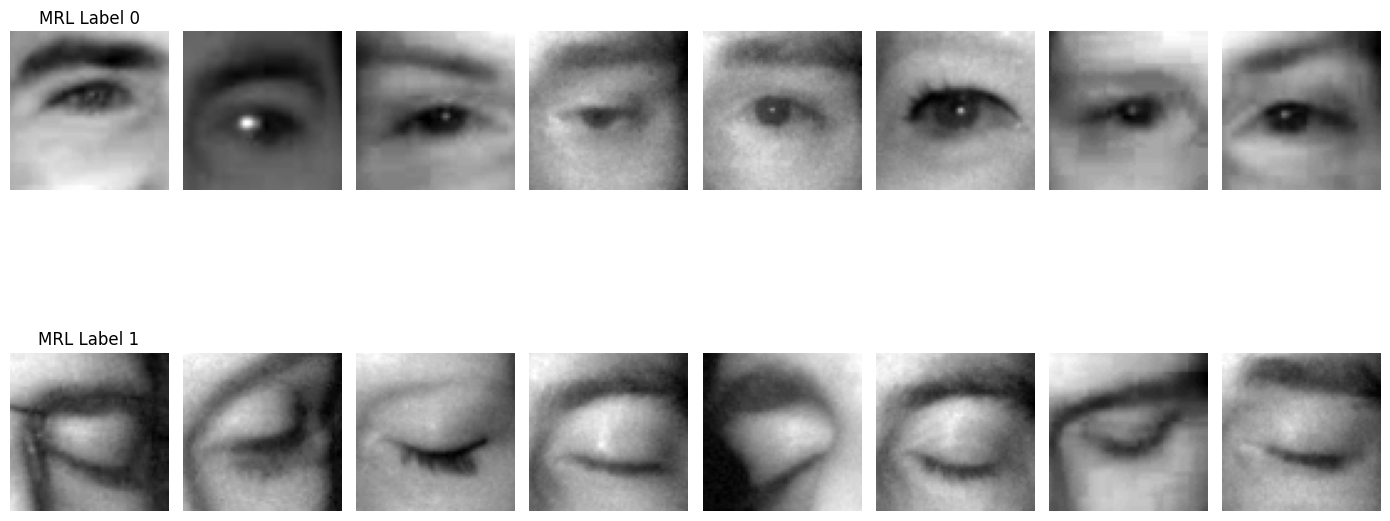


SMARTCAP IMAGE VALIDATION
OPEN: 17 valid / 28 total
CLOSED: 7 valid / 18 total

Unreadable images: 22
BAD: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131214_724089_L.png
BAD: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131214_954278_L.png
BAD: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131215_921191_R.png
BAD: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131216_164527_L.png
BAD: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131216_395967_L.png
BAD: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131216_395967_R.png
BAD: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131216_642841_L.png
BAD: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131216_870753_L.png
BAD: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131217_121571_L.png
BAD: /content/SmartCap_N

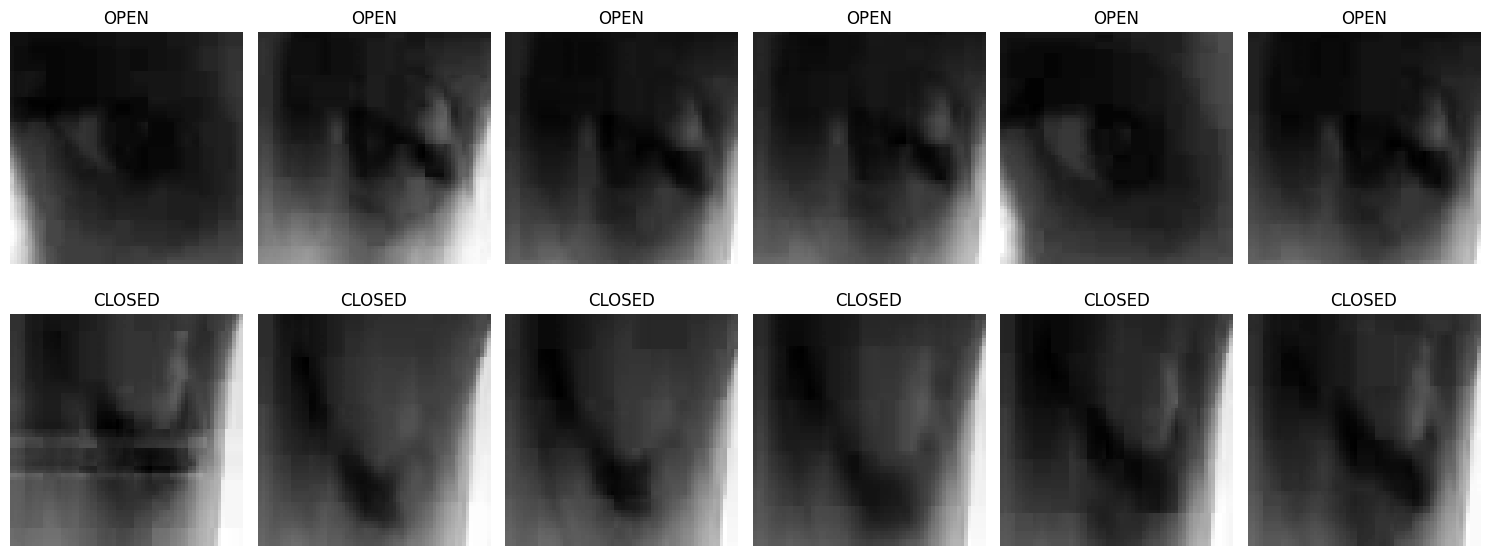

In [25]:

import numpy as np
import matplotlib.pyplot as plt
import cv2
from pathlib import Path
import random

BASE = Path("/content")

# ==========================================
# 1. CHECK MRL LABELS
# ==========================================

data = np.load(BASE / "mrl_64.npz")

X = data["Xtr"]
y = data["ytr"]

print("=" * 50)
print("MRL LABEL DISTRIBUTION")

for label in np.unique(y):
    count = np.sum(y == label)
    print(f"Label {label}: {count} images")

# Display samples from every label
labels = np.unique(y)

fig, axes = plt.subplots(
    len(labels), 8,
    figsize=(14, 4 * len(labels))
)

if len(labels) == 1:
    axes = np.array([axes])

for row, label in enumerate(labels):

    indices = np.where(y == label)[0]

    selected = np.random.choice(
        indices,
        min(8, len(indices)),
        replace=False
    )

    for col, idx in enumerate(selected):

        axes[row, col].imshow(X[idx], cmap="gray")
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_title(f"MRL Label {label}")

plt.tight_layout()
plt.show()


# ==========================================
# 2. CHECK SMARTCAP IMAGES SAFELY
# ==========================================

smartcap = (
    BASE /
    "SmartCap_New_Data/data_raw/P01/test01"
)

extensions = {".jpg", ".jpeg", ".png", ".bmp"}

print("\n" + "=" * 50)
print("SMARTCAP IMAGE VALIDATION")

valid_images = {}
bad_images = []

for label in ["open", "closed"]:

    folder = smartcap / label

    image_paths = sorted([
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in extensions
    ])

    valid_images[label] = []

    for path in image_paths:

        img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

        if img is None or img.size == 0:
            bad_images.append(path)
            continue

        valid_images[label].append((path, img))

    print(
        f"{label.upper()}: "
        f"{len(valid_images[label])} valid / "
        f"{len(image_paths)} total"
    )

print("\nUnreadable images:", len(bad_images))

for path in bad_images:
    print("BAD:", path)


# ==========================================
# 3. DISPLAY VALID SMARTCAP IMAGES
# ==========================================

fig, axes = plt.subplots(2, 6, figsize=(15, 6))

for row, label in enumerate(["open", "closed"]):

    samples = valid_images[label]

    selected = random.sample(
        samples,
        min(6, len(samples))
    )

    for col, (path, img) in enumerate(selected):

        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(label.upper())
        axes[row, col].axis("off")

        # Show filename for traceability
        axes[row, col].set_xlabel(path.name[-18:])

    for col in range(len(selected), 6):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


In [26]:

# =========================================================
# SMARTCAP + MRL DATASET MERGING AND CPU FINE-TUNING
# =========================================================

import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import cv2
import numpy as np
import tensorflow as tf
import random

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# =========================================================
# 1. SETTINGS
# =========================================================

BASE = Path("/content")

NPZ_PATH = BASE / "mrl_64.npz"
MODEL_PATH = BASE / "best_eye_model.keras"

SMARTCAP_PATH = (
    BASE / "SmartCap_New_Data/data_raw/P01/test01"
)

OUTPUT_MODEL = BASE / "best_eye_model_v2.keras"

SEED = 42
MAX_MRL_PER_CLASS = 10000

EPOCHS = 5
BATCH_SIZE = 64

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

# Force CPU
try:
    tf.config.set_visible_devices([], "GPU")
except RuntimeError:
    pass

print("TensorFlow:", tf.__version__)
print("Training device: CPU")

# =========================================================
# 2. LOAD MRL DATA
# =========================================================

print("\nLoading MRL dataset...")

if not NPZ_PATH.exists():
    raise FileNotFoundError(NPZ_PATH)

mrl = np.load(NPZ_PATH)

Xtr = mrl["Xtr"]
ytr = mrl["ytr"]

Xva = mrl["Xva"]
yva = mrl["yva"]

Xte = mrl["Xte"]
yte = mrl["yte"]

print("Original MRL:")
print("Train:", Xtr.shape)
print("Validation:", Xva.shape)
print("Test:", Xte.shape)

# Label mapping confirmed:
# 0 = OPEN
# 1 = CLOSED

# =========================================================
# 3. SELECT BALANCED MRL TRAINING SAMPLES
# =========================================================

print("\nSelecting balanced MRL training samples...")

selected_indices = []

for label in [0, 1]:

    indices = np.where(ytr == label)[0]

    count = min(
        MAX_MRL_PER_CLASS,
        len(indices)
    )

    chosen = np.random.choice(
        indices,
        size=count,
        replace=False
    )

    selected_indices.extend(chosen)

selected_indices = np.array(selected_indices)

np.random.shuffle(selected_indices)

X_mrl_train = Xtr[selected_indices]
y_mrl_train = ytr[selected_indices]

print("Selected MRL training:", X_mrl_train.shape)

# =========================================================
# 4. LOAD SMARTCAP IMAGES
# =========================================================

print("\nLoading SmartCap images...")

smartcap_images = []
smartcap_labels = []
smartcap_groups = []

bad_images = []

for folder_name, label in [
    ("open", 0),
    ("closed", 1)
]:

    folder = SMARTCAP_PATH / folder_name

    if not folder.exists():
        raise FileNotFoundError(folder)

    for image_path in sorted(folder.glob("*")):

        if image_path.suffix.lower() not in [
            ".png", ".jpg", ".jpeg", ".bmp"
        ]:
            continue

        image = cv2.imread(
            str(image_path),
            cv2.IMREAD_GRAYSCALE
        )

        if image is None or image.size == 0:
            bad_images.append(str(image_path))
            continue

        image = cv2.resize(
            image,
            (64, 64),
            interpolation=cv2.INTER_AREA
        )

        # Add channel dimension later
        smartcap_images.append(image)
        smartcap_labels.append(label)

        # Keep L/R images from the same frame together
        group = image_path.stem.rsplit("_", 1)[0]
        smartcap_groups.append(group)

X_smart = np.array(
    smartcap_images,
    dtype=np.uint8
)

y_smart = np.array(
    smartcap_labels,
    dtype=np.int64
)

groups = np.array(smartcap_groups)

print("Valid SmartCap images:", len(X_smart))
print("Unreadable images:", len(bad_images))

for path in bad_images:
    print("Skipped:", path)

print("SmartCap Open:", np.sum(y_smart == 0))
print("SmartCap Closed:", np.sum(y_smart == 1))

if len(X_smart) == 0:
    raise ValueError("No valid SmartCap images found.")

# =========================================================
# 5. SPLIT SMARTCAP BY CAPTURE GROUP
# =========================================================

print("\nSplitting SmartCap by capture group...")

smart_train_indices = []
smart_test_indices = []

rng = np.random.RandomState(SEED)

for label in [0, 1]:

    label_indices = np.where(y_smart == label)[0]

    label_groups = np.unique(groups[label_indices])

    if len(label_groups) < 2:
        raise ValueError(
            f"Not enough separate capture groups for label {label}"
        )

    shuffled_groups = rng.permutation(label_groups)

    test_group_count = max(
        1,
        int(np.ceil(len(shuffled_groups) * 0.20))
    )

    test_groups = set(
        shuffled_groups[:test_group_count]
    )

    for idx in label_indices:

        if groups[idx] in test_groups:
            smart_test_indices.append(idx)
        else:
            smart_train_indices.append(idx)

smart_train_indices = np.array(smart_train_indices)
smart_test_indices = np.array(smart_test_indices)

X_smart_train = X_smart[smart_train_indices]
y_smart_train = y_smart[smart_train_indices]

X_smart_test = X_smart[smart_test_indices]
y_smart_test = y_smart[smart_test_indices]

print("SmartCap train:", len(X_smart_train))
print("SmartCap test:", len(X_smart_test))

# =========================================================
# 6. COMBINE MRL + SMARTCAP
# =========================================================

print("\nCombining datasets...")

X_train = np.concatenate(
    [X_mrl_train, X_smart_train],
    axis=0
)

y_train = np.concatenate(
    [y_mrl_train, y_smart_train],
    axis=0
)

# Shuffle combined training data
shuffle_indices = np.random.permutation(len(X_train))

X_train = X_train[shuffle_indices]
y_train = y_train[shuffle_indices]

# Normalize images
X_train = X_train.astype("float32") / 255.0
X_val = Xva.astype("float32") / 255.0
X_test = Xte.astype("float32") / 255.0
X_smart_test = X_smart_test.astype("float32") / 255.0

# Add grayscale channel
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]
X_smart_test = X_smart_test[..., np.newaxis]

y_train = y_train.astype("float32")
y_val = yva.astype("float32")
y_test = yte.astype("float32")
y_smart_test = y_smart_test.astype("float32")

print("\nFINAL DATASET")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("MRL Test:", X_test.shape)
print("SmartCap Test:", X_smart_test.shape)

print("\nTraining labels:")
print("Open:", np.sum(y_train == 0))
print("Closed:", np.sum(y_train == 1))

# =========================================================
# 7. LOAD EXISTING MODEL
# =========================================================

print("\nLoading existing CNN model...")

if not MODEL_PATH.exists():
    raise FileNotFoundError(MODEL_PATH)

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("Model input:", model.input_shape)
print("Model output:", model.output_shape)

if model.input_shape[1:] != (64, 64, 1):
    raise ValueError("Unexpected model input shape.")

# =========================================================
# 8. COMPILE FOR FINE-TUNING
# =========================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

# =========================================================
# 9. CALLBACKS
# =========================================================

callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(OUTPUT_MODEL),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(BASE / "training_history_v2.csv")
    )
]

# =========================================================
# 10. TRAIN ON CPU
# =========================================================

print("\nStarting CPU fine-tuning...")

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

print("\nTraining completed.")

# =========================================================
# 11. EVALUATE MRL TEST
# =========================================================

print("\nEvaluating on MRL Test...")

best_model = tf.keras.models.load_model(
    OUTPUT_MODEL
)

mrl_results = best_model.evaluate(
    X_test,
    y_test,
    verbose=1,
    return_dict=True
)

print("\nMRL TEST RESULTS")

for key, value in mrl_results.items():
    print(f"{key}: {value:.4f}")

# =========================================================
# 12. EVALUATE SMARTCAP TEST
# =========================================================

print("\nEvaluating on SmartCap Test...")

smart_predictions = best_model.predict(
    X_smart_test,
    verbose=0
).reshape(-1)

smart_predicted_labels = (
    smart_predictions >= 0.5
).astype(int)

print("\nSMARTCAP TEST RESULTS")

print(
    classification_report(
        y_smart_test.astype(int),
        smart_predicted_labels,
        labels=[0, 1],
        target_names=["Open", "Closed"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_smart_test.astype(int),
        smart_predicted_labels,
        labels=[0, 1]
    )
)

# =========================================================
# 13. SAVE FINAL MODEL
# =========================================================

best_model.save(OUTPUT_MODEL)

print("\n====================================")
print("FINE-TUNING FINISHED")
print("New model:", OUTPUT_MODEL)
print("Old model preserved:", MODEL_PATH)
print("====================================")


TensorFlow: 2.21.0
Training device: CPU

Loading MRL dataset...
Original MRL:
Train: (67372, 64, 64)
Validation: (8955, 64, 64)
Test: (8571, 64, 64)

Selecting balanced MRL training samples...
Selected MRL training: (20000, 64, 64)

Loading SmartCap images...
Valid SmartCap images: 24
Unreadable images: 22
Skipped: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131214_724089_L.png
Skipped: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131214_954278_L.png
Skipped: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131215_921191_R.png
Skipped: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131216_164527_L.png
Skipped: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131216_395967_L.png
Skipped: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131216_395967_R.png
Skipped: /content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_13121

In [27]:

from pathlib import Path
import cv2
import os

ROOT = Path(
    "/content/SmartCap_New_Data/data_raw/P01/test01"
)

bad_files = []

for label in ["open", "closed"]:

    folder = ROOT / label

    print("\n", "=" * 45)
    print("FOLDER:", label.upper())

    for path in sorted(folder.iterdir()):

        if path.suffix.lower() not in [
            ".png", ".jpg", ".jpeg", ".bmp"
        ]:
            continue

        size = path.stat().st_size

        img = cv2.imread(
            str(path),
            cv2.IMREAD_GRAYSCALE
        )

        if img is None:
            bad_files.append(path)

            print(
                "BAD |",
                path.name,
                "| Size:",
                size,
                "bytes"
            )

        else:
            print(
                "OK  |",
                path.name,
                "| Size:",
                size,
                "| Shape:",
                img.shape
            )

print("\n" + "=" * 45)
print("TOTAL BAD FILES:", len(bad_files))
print("TOTAL VALID FILES:", 46 - len(bad_files))



FOLDER: OPEN
BAD | P01_test01_20261110_131214_724089_L.png | Size: 0 bytes
OK  | P01_test01_20261110_131214_724089_R.png | Size: 2012 | Shape: (64, 64)
BAD | P01_test01_20261110_131214_954278_L.png | Size: 0 bytes
OK  | P01_test01_20261110_131214_954278_R.png | Size: 2010 | Shape: (64, 64)
OK  | P01_test01_20261110_131215_197797_L.png | Size: 1589 | Shape: (64, 64)
OK  | P01_test01_20261110_131215_197797_R.png | Size: 2005 | Shape: (64, 64)
OK  | P01_test01_20261110_131215_439203_L.png | Size: 1562 | Shape: (64, 64)
OK  | P01_test01_20261110_131215_439203_R.png | Size: 2031 | Shape: (64, 64)
OK  | P01_test01_20261110_131215_706222_L.png | Size: 1553 | Shape: (64, 64)
OK  | P01_test01_20261110_131215_706222_R.png | Size: 1928 | Shape: (64, 64)
OK  | P01_test01_20261110_131215_921191_L.png | Size: 1647 | Shape: (64, 64)
BAD | P01_test01_20261110_131215_921191_R.png | Size: 0 bytes
BAD | P01_test01_20261110_131216_164527_L.png | Size: 0 bytes
OK  | P01_test01_20261110_131216_164527_R.png

In [28]:
import os

print("=== Files in Colab ===")

for item in os.listdir("/content"):
    path = os.path.join("/content", item)

    if os.path.isfile(path):
        size = os.path.getsize(path) / (1024 * 1024)
        print(f"FILE: {item} | {size:.2f} MB")
    else:
        print(f"FOLDER: {item}")

=== Files in Colab ===
FOLDER: .config
FOLDER: SmartCap_New_Data
FILE: best_eye_model_v2.keras | 7.86 MB
FILE: training_history_v2.csv | 0.00 MB
FILE: mrl_64.npz | 194.54 MB
FOLDER: mrl
FOLDER: MRL_Eye_Dataset
FILE: best_eye_model.keras | 7.86 MB
FILE: mrlEyes_2018_01.zip | 326.03 MB
FILE: data_raw.rar | 1.60 MB
FOLDER: sample_data


In [29]:
import os
from pathlib import Path
from collections import Counter

DATA_PATH = Path("/content/SmartCap_New_Data")

print("Dataset exists:", DATA_PATH.exists())
print("\n=== Folder structure ===")

for root, dirs, files in os.walk(DATA_PATH):
    level = len(Path(root).relative_to(DATA_PATH).parts)

    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{Path(root).name}/")

    for file in files[:5]:
        print(f"{indent}    {file}")

print("\n=== File extensions ===")

extensions = Counter(
    file.suffix.lower()
    for file in DATA_PATH.rglob("*")
    if file.is_file()
)

for ext, count in extensions.items():
    print(ext or "No extension", ":", count)

print("\n=== Total files ===")
print(sum(1 for f in DATA_PATH.rglob("*") if f.is_file()))

Dataset exists: True

=== Folder structure ===
SmartCap_New_Data/
    data_raw/
        P01/
            s01/
                meta.json
                log.csv
            test01/
                meta.json
                log.csv

=== File extensions ===
.json : 2
.csv : 2
.png : 46

=== Total files ===
50


In [30]:

from pathlib import Path
from collections import Counter
from PIL import Image
import json
import pandas as pd

DATA_PATH = Path("/content/SmartCap_New_Data/data_raw")

images = list(DATA_PATH.rglob("*.png"))

# 1. Count images by folder
print("=== Images by folder ===")
folder_counts = Counter(img.parent.name.lower() for img in images)

for folder, count in folder_counts.items():
    print(f"{folder}: {count}")

# 2. Check image validity and dimensions
valid_images = []
bad_images = []
dimensions = Counter()

for img_path in images:
    try:
        with Image.open(img_path) as img:
            img.verify()

        with Image.open(img_path) as img:
            dimensions[img.size] += 1

        valid_images.append(img_path)

    except Exception as e:
        bad_images.append((img_path, str(e)))

print("\n=== Image quality check ===")
print("Total PNG images:", len(images))
print("Valid images:", len(valid_images))
print("Bad images:", len(bad_images))
print("Image dimensions:", dimensions)

# 3. Show actual folder structure
print("\n=== Image folders ===")
for folder in sorted(set(img.parent for img in images)):
    print(folder.relative_to(DATA_PATH), "->",
          sum(1 for img in images if img.parent == folder), "images")

# 4. Inspect CSV files
print("\n=== CSV files ===")
for csv_path in DATA_PATH.rglob("*.csv"):
    df = pd.read_csv(csv_path)
    print("\nFile:", csv_path.relative_to(DATA_PATH))
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print(df.head(3).to_string(index=False))


=== Images by folder ===
open: 28
closed: 18

=== Image quality check ===
Total PNG images: 46
Valid images: 24
Bad images: 22
Image dimensions: Counter({(64, 64): 24})

=== Image folders ===
P01/test01/closed -> 18 images
P01/test01/open -> 28 images

=== CSV files ===

File: P01/s01/log.csv
Rows: 0
Columns: ['file', 't_wall', 'state', 'eye', 'ear']
Empty DataFrame
Columns: [file, t_wall, state, eye, ear]
Index: []


EmptyDataError: No columns to parse from file

In [31]:

from pathlib import Path
from PIL import Image
from collections import Counter
import pandas as pd

DATA_PATH = Path("/content/SmartCap_New_Data/data_raw")

valid_by_class = Counter()
bad_by_class = Counter()
bad_files = []

for img_path in DATA_PATH.rglob("*.png"):
    label = img_path.parent.name.lower()

    try:
        with Image.open(img_path) as img:
            img.verify()

        with Image.open(img_path) as img:
            if img.size != (64, 64):
                raise ValueError(f"Unexpected size: {img.size}")

        valid_by_class[label] += 1

    except Exception as e:
        bad_by_class[label] += 1
        bad_files.append((str(img_path), str(e)))

print("=== VALID IMAGES ===")
for label in ["open", "closed"]:
    print(f"{label}: {valid_by_class[label]}")

print("\n=== BAD IMAGES ===")
for label in ["open", "closed"]:
    print(f"{label}: {bad_by_class[label]}")

print("\n=== BAD FILE DETAILS ===")
for path, error in bad_files:
    print(Path(path).name, "->", error)

print("\n=== CSV CHECK ===")
for csv_path in DATA_PATH.rglob("*.csv"):
    print("\n", csv_path.name)

    try:
        df = pd.read_csv(csv_path)
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
    except pd.errors.EmptyDataError:
        print("EMPTY CSV - no data available")


=== VALID IMAGES ===
open: 17
closed: 7

=== BAD IMAGES ===
open: 11
closed: 11

=== BAD FILE DETAILS ===
P01_test01_20261110_131215_921191_R.png -> cannot identify image file '/content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131215_921191_R.png'
P01_test01_20261110_131216_642841_L.png -> cannot identify image file '/content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131216_642841_L.png'
P01_test01_20261110_131214_954278_L.png -> cannot identify image file '/content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131214_954278_L.png'
P01_test01_20261110_131216_870753_L.png -> cannot identify image file '/content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131216_870753_L.png'
P01_test01_20261110_131214_724089_L.png -> cannot identify image file '/content/SmartCap_New_Data/data_raw/P01/test01/open/P01_test01_20261110_131214_724089_L.png'
P01_test01_20261110_131216_395967_R.png -> cannot identify image file '/co

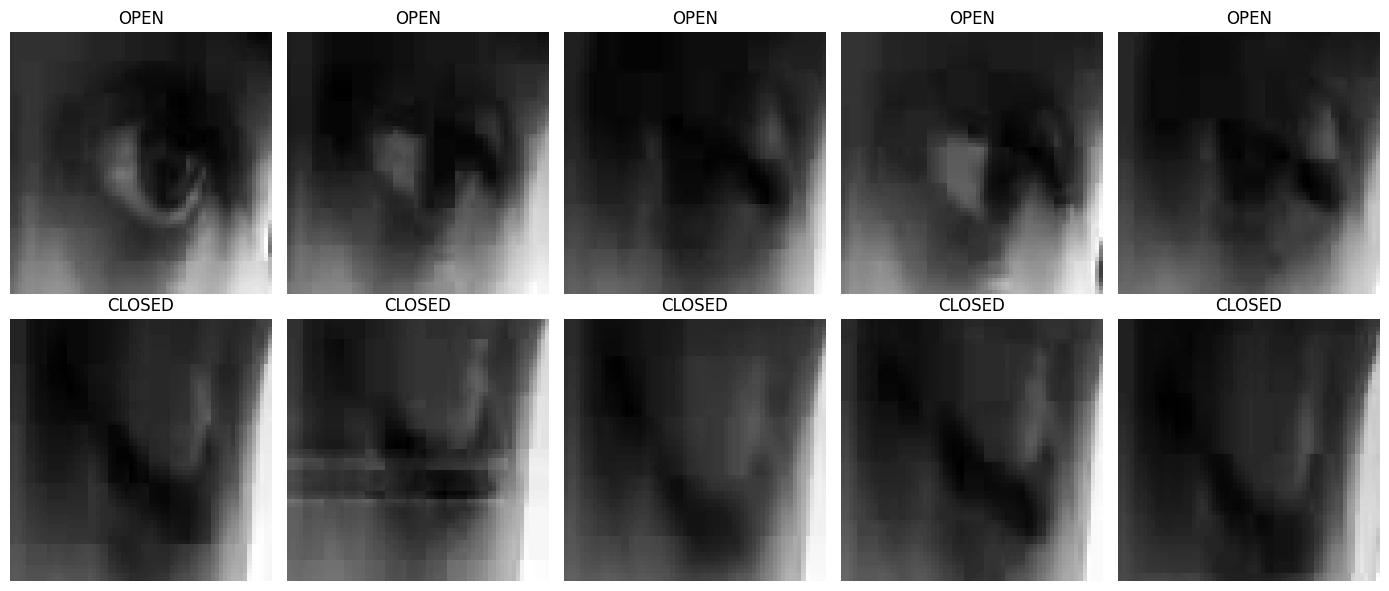

In [32]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random

DATA_PATH = Path("/content/SmartCap_New_Data/data_raw/P01/test01")

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for row, label in enumerate(["open", "closed"]):
    folder = DATA_PATH / label

    valid_images = []

    for path in folder.glob("*.png"):
        try:
            with Image.open(path) as img:
                img.verify()
            valid_images.append(path)
        except Exception:
            pass

    samples = random.sample(valid_images, min(5, len(valid_images)))

    for col, ax in enumerate(axes[row]):
        ax.axis("off")

        if col < len(samples):
            with Image.open(samples[col]) as img:
                ax.imshow(img.convert("L"), cmap="gray")

            ax.set_title(label.upper())

plt.tight_layout()
plt.show()


In [33]:
from pathlib import Path

DATA_PATH = Path("/content/SmartCap_New_Data/data_raw")

for person in sorted(DATA_PATH.iterdir()):
    if not person.is_dir():
        continue

    print(f"\n{'='*40}")
    print("PERSON:", person.name)

    for session in sorted(person.iterdir()):
        if not session.is_dir():
            continue

        print(f"\n  SESSION: {session.name}")

        for label in ["open", "closed"]:
            folder = session / label

            if folder.exists():
                files = list(folder.glob("*.png"))
                print(f"    {label}: {len(files)} PNG files")


PERSON: P01

  SESSION: s01
    open: 0 PNG files
    closed: 0 PNG files

  SESSION: test01
    open: 28 PNG files
    closed: 18 PNG files


In [34]:
from pathlib import Path

DATA_PATH = Path("/content/SmartCap_New_Data/data_raw")

for person in sorted(DATA_PATH.iterdir()):
    if not person.is_dir():
        continue

    print(f"\n{'='*40}")
    print("PERSON:", person.name)

    for session in sorted(person.iterdir()):
        if not session.is_dir():
            continue

        print(f"\n  SESSION: {session.name}")

        for label in ["open", "closed"]:
            folder = session / label

            if folder.exists():
                files = list(folder.glob("*.png"))
                print(f"    {label}: {len(files)} PNG files")


PERSON: P01

  SESSION: s01
    open: 0 PNG files
    closed: 0 PNG files

  SESSION: test01
    open: 28 PNG files
    closed: 18 PNG files


In [35]:
from pathlib import Path

DATA_PATH = Path("/content/SmartCap_New_Data/data_raw.rar")

for person in sorted(DATA_PATH.iterdir()):
    if not person.is_dir():
        continue

    print(f"\n{'='*40}")
    print("PERSON:", person.name)

    for session in sorted(person.iterdir()):
        if not session.is_dir():
            continue

        print(f"\n  SESSION: {session.name}")

        for label in ["open", "closed"]:
            folder = session / label

            if folder.exists():
                files = list(folder.glob("*.png"))
                print(f"    {label}: {len(files)} PNG files")

NotADirectoryError: [Errno 20] Not a directory: '/content/SmartCap_New_Data/data_raw.rar'

In [36]:
!apt-get update -qq
!apt-get install -y unrar

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
W: Failed to fetch https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu/dists/noble/InRelease  Could not connect to ppa.launchpadcontent.net:443 (185.125.189.186), connection timed out Could not connect to ppa.launchpadcontent.net:443 (185.125.189.187), connection timed out Could not connect to ppa.launchpadcontent.net:443 (185.125.189.188), connection timed out
W: Some index files failed to download. They have been ignored, or old ones used instead.
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:7.0.7-1build1).
0 upgraded, 0 newly installed, 0 to remove and 40 not upgraded.


In [37]:
!mkdir -p /content/SmartCap_Extracted
!unrar x -o- "/content/SmartCap_New_Data/data_raw.rar" "/content/SmartCap_Extracted/"


UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from /content/SmartCap_New_Data/data_raw.rar

Creating    /content/SmartCap_Extracted/data_raw                      OK
Creating    /content/SmartCap_Extracted/data_raw/P01                  OK
Creating    /content/SmartCap_Extracted/data_raw/P01/s01              OK
Extracting  /content/SmartCap_Extracted/data_raw/P01/s01/log.csv           0%  OK 
Extracting  /content/SmartCap_Extracted/data_raw/P01/s01/meta.json         0%  OK 
Creating    /content/SmartCap_Extracted/data_raw/P01/test01           OK
Creating    /content/SmartCap_Extracted/data_raw/P01/test01/closed    OK
Extracting  /content/SmartCap_Extracted/data_raw/P01/test01/closed/P01_test01_20261110_131154_165549_L.png       0%  OK 
Extracting  /content/SmartCap_Extracted/data_raw/P01/test01/closed/P01_test01_20261110_131154_165549_R.png       0%  OK 
Extracting  /content/SmartCap_Extracted/data_raw/P01/test01/close

In [38]:
from pathlib import Path

DATA_PATH = Path("/content/SmartCap_Extracted")

for path in sorted(DATA_PATH.rglob("*")):
    if path.is_dir():
        print("FOLDER:", path.relative_to(DATA_PATH))

FOLDER: data_raw
FOLDER: data_raw/P01
FOLDER: data_raw/P01/s01
FOLDER: data_raw/P01/s01/closed
FOLDER: data_raw/P01/s01/open
FOLDER: data_raw/P01/test01
FOLDER: data_raw/P01/test01/closed
FOLDER: data_raw/P01/test01/open
FOLDER: data_raw/P02
FOLDER: data_raw/P02/test01
FOLDER: data_raw/P02/test01/closed
FOLDER: data_raw/P02/test01/open
FOLDER: data_raw/P02/test02
FOLDER: data_raw/P02/test02/closed
FOLDER: data_raw/P02/test02/open


In [39]:
for person in sorted(DATA_PATH.rglob("P*")):
    if not person.is_dir():
        continue

    print(f"\nPERSON: {person.name}")

    for session in sorted(person.iterdir()):
        if session.is_dir():
            print(f"  TEST: {session.name}")

            for label in ["open", "closed"]:
                folder = session / label
                if folder.exists():
                    print(f"    {label}: {len(list(folder.glob('*.png')))}")


PERSON: P01
  TEST: s01
    open: 0
    closed: 0
  TEST: test01
    open: 28
    closed: 18

PERSON: P02
  TEST: test01
    open: 136
    closed: 144
  TEST: test02
    open: 200
    closed: 187


In [40]:

from pathlib import Path
from PIL import Image
from collections import defaultdict

DATA_PATH = Path("/content/SmartCap_Extracted")

results = defaultdict(lambda: {"valid": 0, "bad": 0, "zero": 0})

for person in sorted(DATA_PATH.glob("P*")):
    if not person.is_dir():
        continue

    for session in sorted(person.iterdir()):
        if not session.is_dir():
            continue

        for label in ["open", "closed"]:
            folder = session / label

            if not folder.exists():
                continue

            for img_path in folder.glob("*"):
                if not img_path.is_file():
                    continue

                key = (person.name, session.name, label)

                try:
                    if img_path.stat().st_size == 0:
                        results[key]["zero"] += 1
                        results[key]["bad"] += 1
                        continue

                    with Image.open(img_path) as img:
                        img.verify()

                    with Image.open(img_path) as img:
                        if img.size != (64, 64):
                            results[key]["bad"] += 1
                            continue

                    results[key]["valid"] += 1

                except Exception:
                    results[key]["bad"] += 1

print("PERSON | SESSION | CLASS | VALID | BAD | ZERO")

for key, counts in sorted(results.items()):
    print(
        f"{key[0]:6} | {key[1]:7} | {key[2]:6} | "
        f"{counts['valid']:5} | {counts['bad']:3} | {counts['zero']:4}"
    )


PERSON | SESSION | CLASS | VALID | BAD | ZERO


In [41]:
from pathlib import Path

for p in Path("/content/SmartCap_Extracted").rglob("*"):
    if p.is_dir() and p.name.lower() in ["open", "closed"]:
        print(p, "=>", len(list(p.iterdir())), "files")

/content/SmartCap_Extracted/data_raw/P01/s01/open => 0 files
/content/SmartCap_Extracted/data_raw/P01/s01/closed => 0 files
/content/SmartCap_Extracted/data_raw/P01/test01/open => 28 files
/content/SmartCap_Extracted/data_raw/P01/test01/closed => 18 files
/content/SmartCap_Extracted/data_raw/P02/test01/open => 136 files
/content/SmartCap_Extracted/data_raw/P02/test01/closed => 144 files
/content/SmartCap_Extracted/data_raw/P02/test02/open => 200 files
/content/SmartCap_Extracted/data_raw/P02/test02/closed => 187 files


In [42]:
from pathlib import Path
from PIL import Image
from collections import defaultdict

DATA_PATH = Path("/content/SmartCap_Extracted/data_raw")

results = defaultdict(lambda: {"valid": 0, "bad": 0, "zero": 0})
dimensions = defaultdict(int)

for person in sorted(DATA_PATH.glob("P*")):
    for session in sorted(person.iterdir()):
        if not session.is_dir():
            continue

        for label in ["open", "closed"]:
            folder = session / label

            if not folder.exists():
                continue

            for img_path in folder.glob("*"):
                if not img_path.is_file():
                    continue

                key = (person.name, session.name, label)

                if img_path.stat().st_size == 0:
                    results[key]["zero"] += 1
                    continue

                try:
                    with Image.open(img_path) as img:
                        img.verify()

                    with Image.open(img_path) as img:
                        dimensions[img.size] += 1

                    results[key]["valid"] += 1

                except Exception:
                    results[key]["bad"] += 1

print("PERSON | SESSION | CLASS | VALID | BAD | ZERO")

for key, value in sorted(results.items()):
    print(
        f"{key[0]} | {key[1]} | {key[2]} | "
        f"{value['valid']} | {value['bad']} | {value['zero']}"
    )

print("\nIMAGE DIMENSIONS:")
for size, count in sorted(dimensions.items()):
    print(f"{size}: {count}")

print("\nTOTAL VALID:", sum(x["valid"] for x in results.values()))
print("TOTAL BAD:", sum(x["bad"] for x in results.values()))
print("TOTAL ZERO:", sum(x["zero"] for x in results.values()))

PERSON | SESSION | CLASS | VALID | BAD | ZERO
P01 | test01 | closed | 18 | 0 | 0
P01 | test01 | open | 28 | 0 | 0
P02 | test01 | closed | 144 | 0 | 0
P02 | test01 | open | 136 | 0 | 0
P02 | test02 | closed | 187 | 0 | 0
P02 | test02 | open | 200 | 0 | 0

IMAGE DIMENSIONS:
(64, 64): 713

TOTAL VALID: 713
TOTAL BAD: 0
TOTAL ZERO: 0


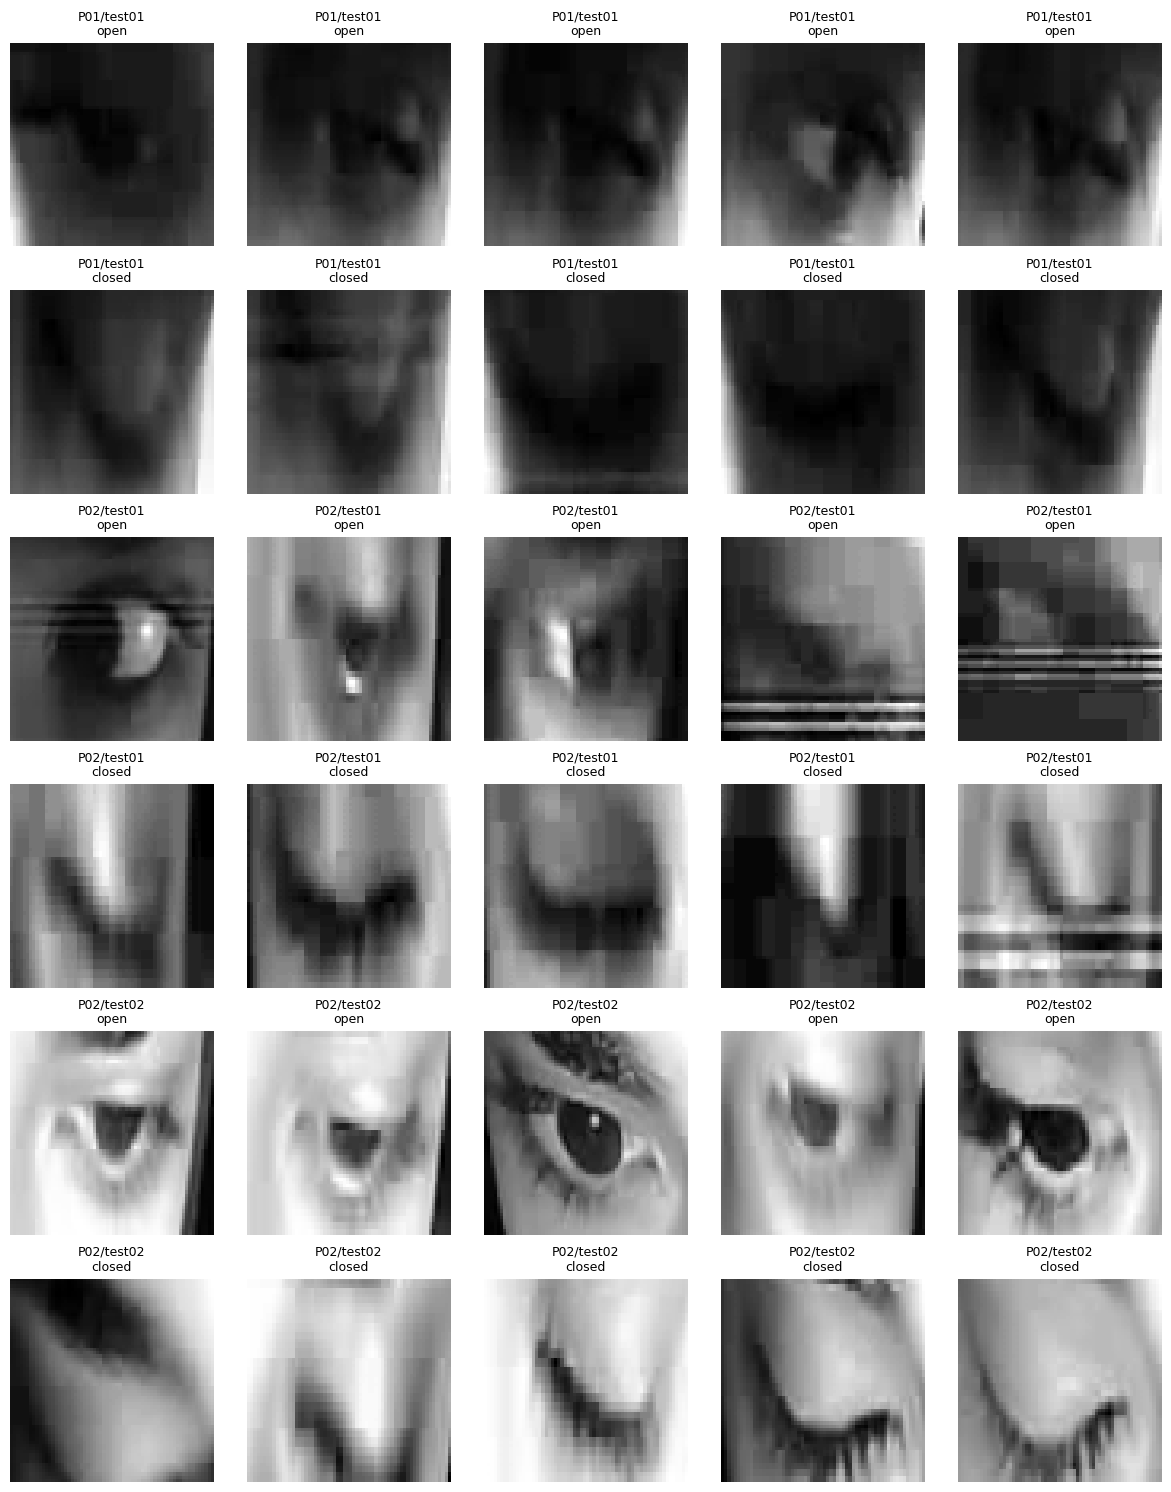

In [43]:
import random
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

DATA_PATH = Path("/content/SmartCap_Extracted/data_raw")

random.seed(42)

samples = []

for person in sorted(DATA_PATH.glob("P*")):
    for session in sorted(person.iterdir()):
        if not session.is_dir():
            continue

        for label in ["open", "closed"]:
            folder = session / label

            if folder.exists():
                images = list(folder.glob("*.png"))

                selected = random.sample(
                    images,
                    min(5, len(images))
                )

                for img_path in selected:
                    samples.append((person.name, session.name, label, img_path))

fig, axes = plt.subplots(6, 5, figsize=(12, 15))

for ax, sample in zip(axes.flat, samples[:30]):
    person, session, label, img_path = sample

    img = Image.open(img_path).convert("L")
    ax.imshow(img, cmap="gray")
    ax.set_title(f"{person}/{session}\n{label}", fontsize=9)
    ax.axis("off")

for ax in axes.flat[len(samples[:30]):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [44]:
from pathlib import Path
from PIL import Image
from collections import defaultdict, Counter
import numpy as np
import hashlib

DATA_PATH = Path("/content/SmartCap_Extracted/data_raw")

stats = []
hashes = defaultdict(list)

for person in sorted(DATA_PATH.glob("P*")):
    for session in sorted(person.iterdir()):
        if not session.is_dir():
            continue

        for label in ["open", "closed"]:
            folder = session / label

            if not folder.exists():
                continue

            for path in folder.glob("*.png"):
                with Image.open(path) as img:
                    arr = np.array(img.convert("L"))

                stats.append({
                    "person": person.name,
                    "session": session.name,
                    "label": label,
                    "mean": float(arr.mean()),
                    "contrast": float(arr.std()),
                    "min": int(arr.min()),
                    "max": int(arr.max()),
                })

                file_hash = hashlib.md5(path.read_bytes()).hexdigest()
                hashes[file_hash].append(str(path))

print("TOTAL IMAGES:", len(stats))

print("\nBRIGHTNESS AND CONTRAST BY CLASS:")
for label in ["open", "closed"]:
    items = [x for x in stats if x["label"] == label]

    print(f"\n{label.upper()}")
    print("Average brightness:", round(np.mean([x["mean"] for x in items]), 2))
    print("Average contrast:", round(np.mean([x["contrast"] for x in items]), 2))
    print("Very dark images:", sum(x["mean"] < 25 for x in items))
    print("Very bright images:", sum(x["mean"] > 230 for x in items))
    print("Very low contrast:", sum(x["contrast"] < 10 for x in items))

duplicates = [paths for paths in hashes.values() if len(paths) > 1]

print("\nEXACT DUPLICATE GROUPS:", len(duplicates))

for group in duplicates[:10]:
    print("\n", *group, sep="\n")

TOTAL IMAGES: 713

BRIGHTNESS AND CONTRAST BY CLASS:

OPEN
Average brightness: 99.02
Average contrast: 33.56
Very dark images: 57
Very bright images: 0
Very low contrast: 40

CLOSED
Average brightness: 99.25
Average contrast: 28.31
Very dark images: 65
Very bright images: 0
Very low contrast: 49

EXACT DUPLICATE GROUPS: 0


DARK IMAGES: 122


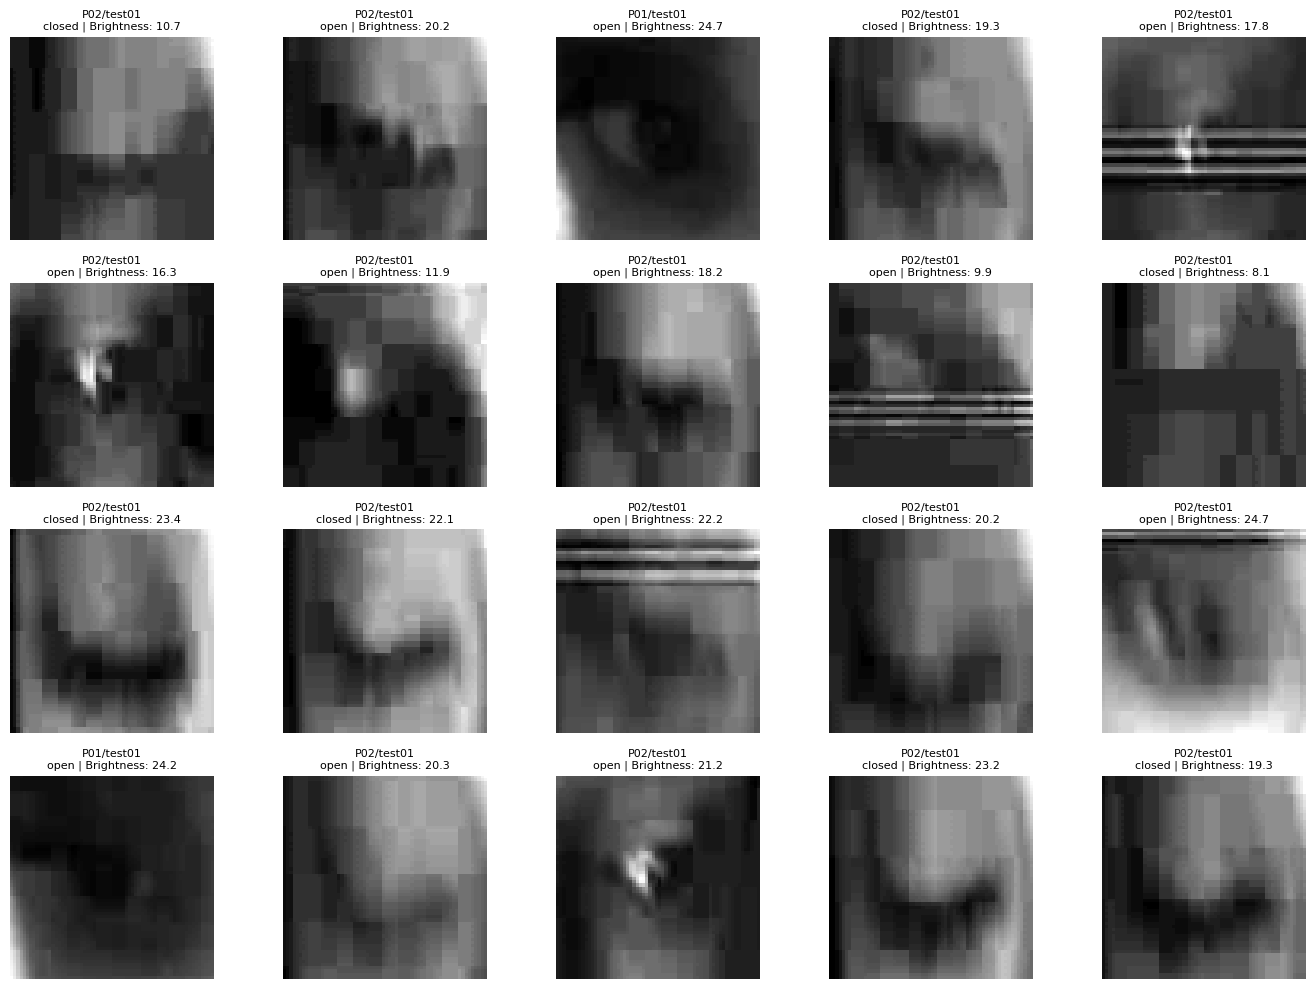

In [45]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import numpy as np
import random

DATA_PATH = Path("/content/SmartCap_Extracted/data_raw")

dark_images = []

for person in sorted(DATA_PATH.glob("P*")):
    for session in sorted(person.iterdir()):
        if not session.is_dir():
            continue

        for label in ["open", "closed"]:
            folder = session / label

            if not folder.exists():
                continue

            for path in folder.glob("*.png"):
                with Image.open(path) as img:
                    arr = np.array(img.convert("L"))

                if arr.mean() < 25:
                    dark_images.append((path, person.name, session.name, label, arr.mean()))

print("DARK IMAGES:", len(dark_images))

random.seed(42)
selected = random.sample(dark_images, min(20, len(dark_images)))

fig, axes = plt.subplots(4, 5, figsize=(14, 10))

for ax, (path, person, session, label, brightness) in zip(axes.flat, selected):
    with Image.open(path) as img:
        ax.imshow(img.convert("L"), cmap="gray")

    ax.set_title(
        f"{person}/{session}\n{label} | Brightness: {brightness:.1f}",
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

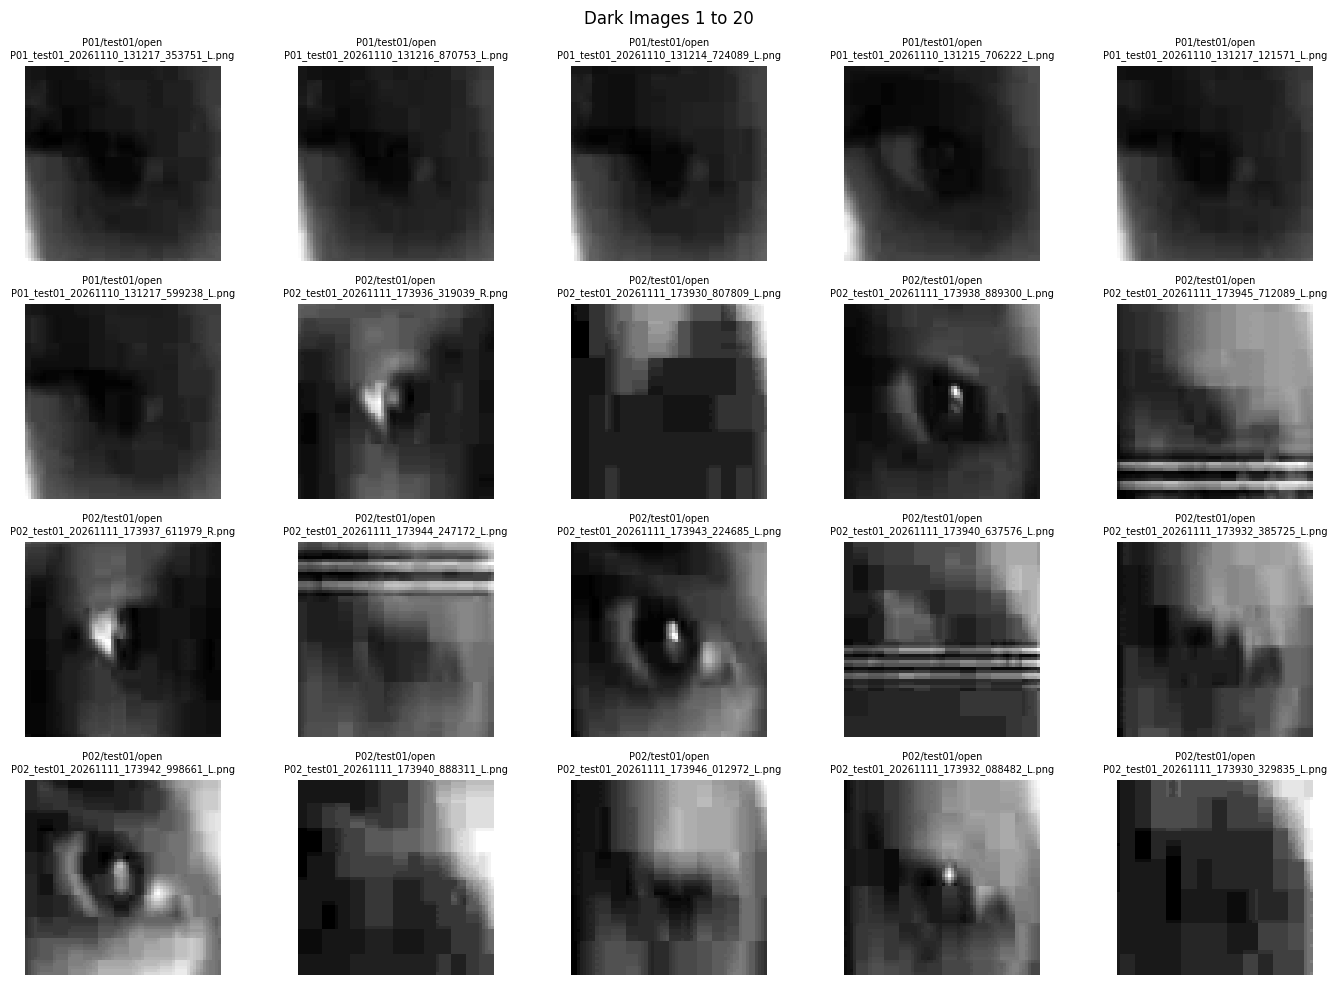

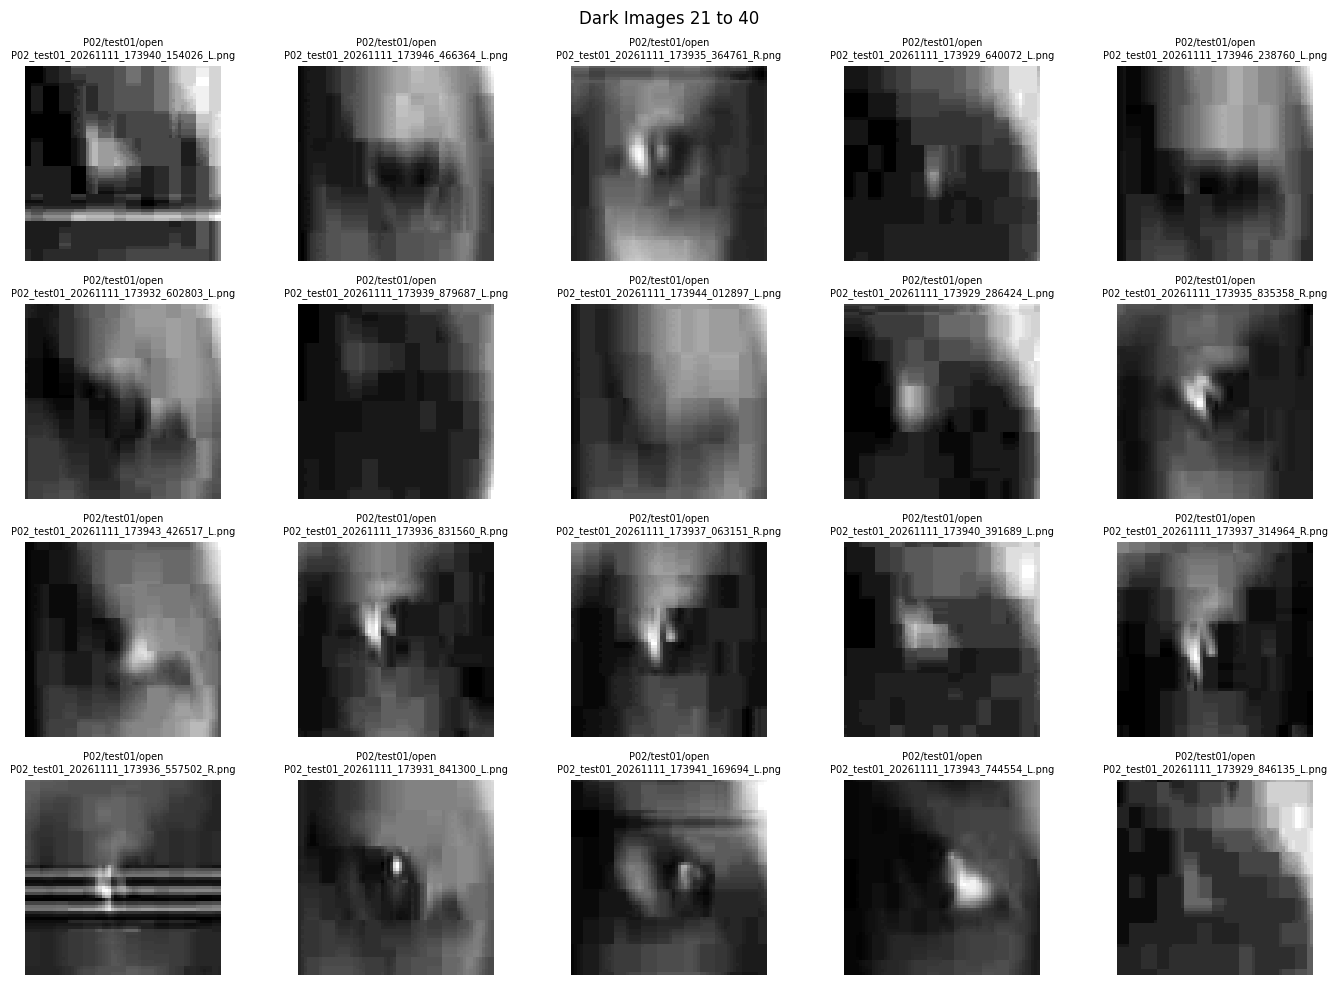

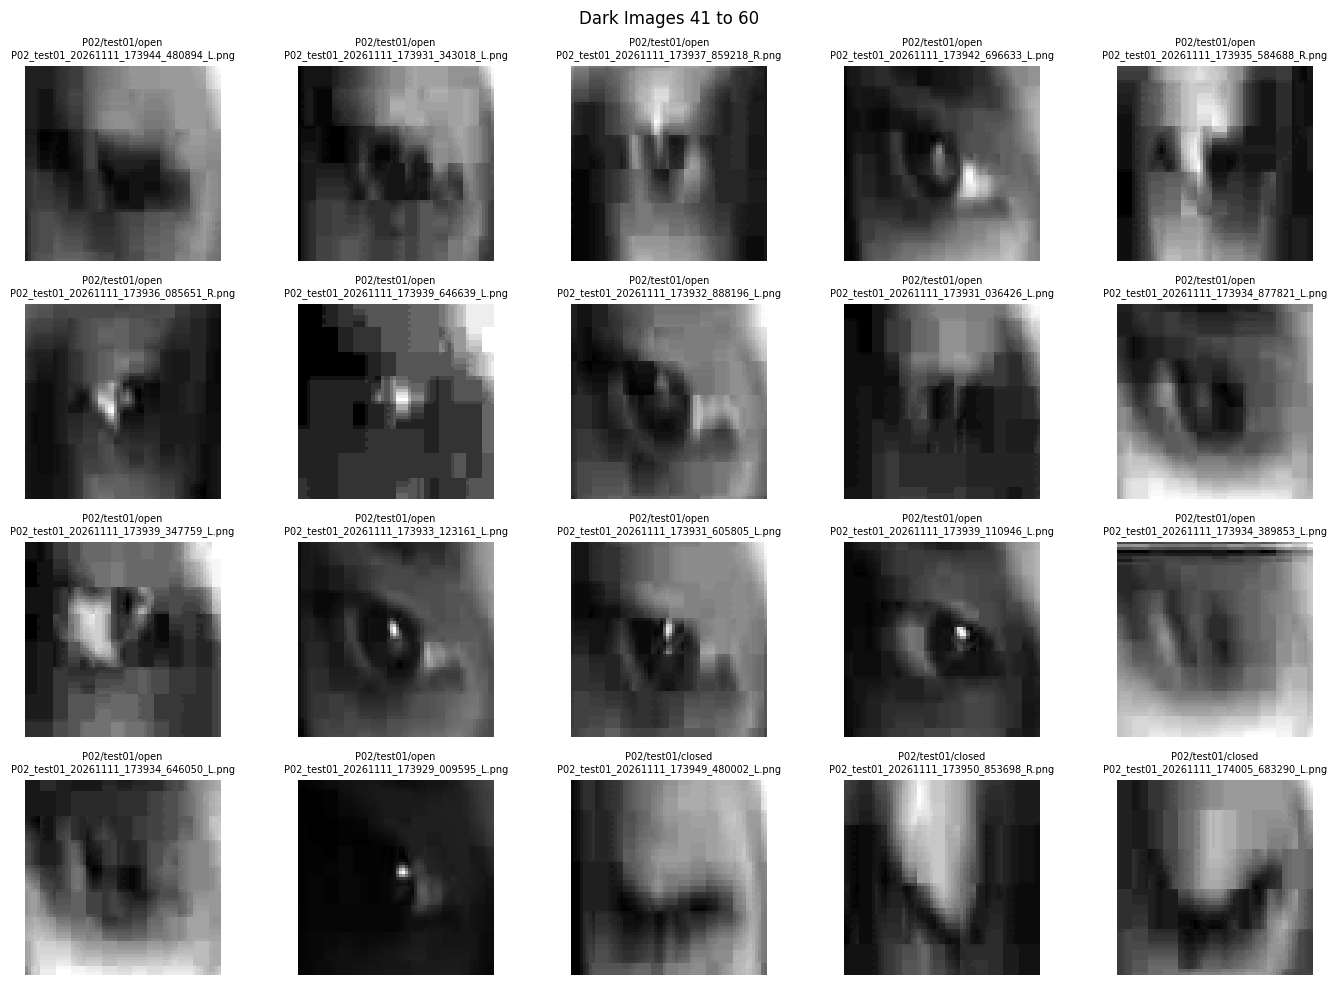

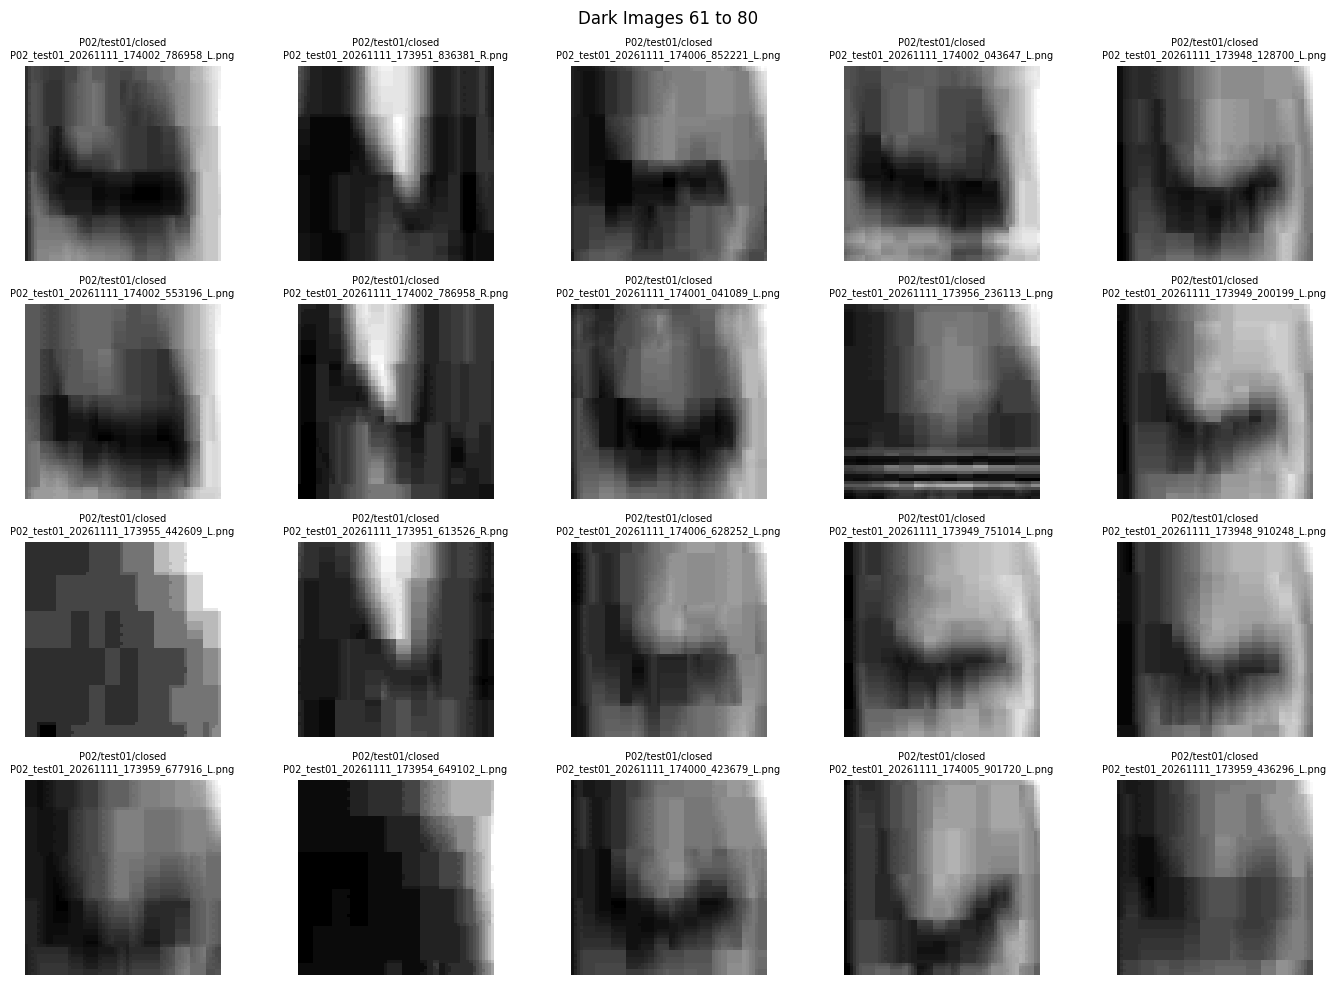

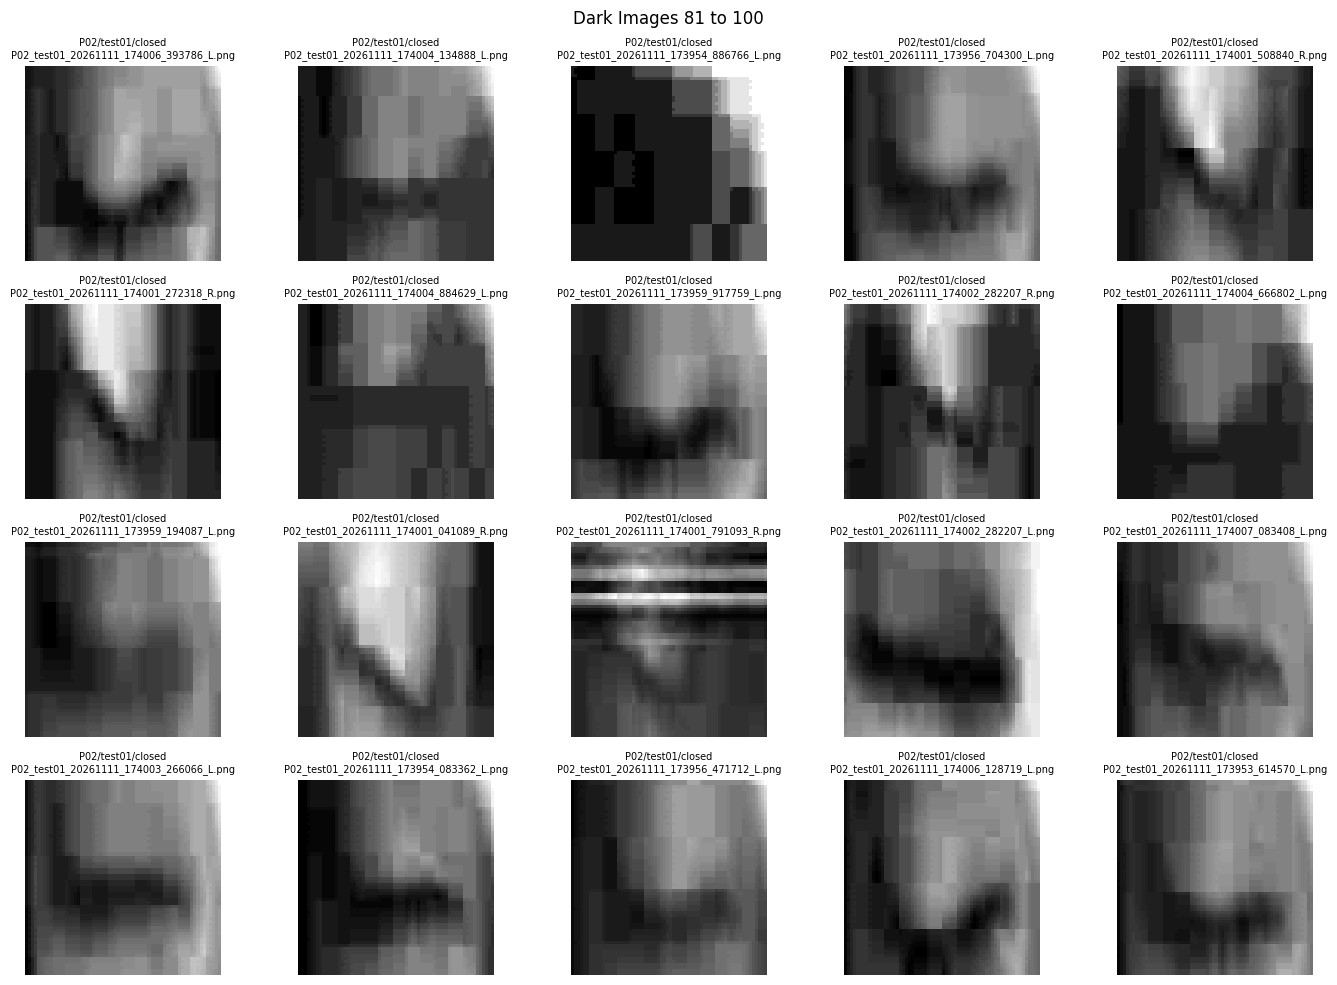

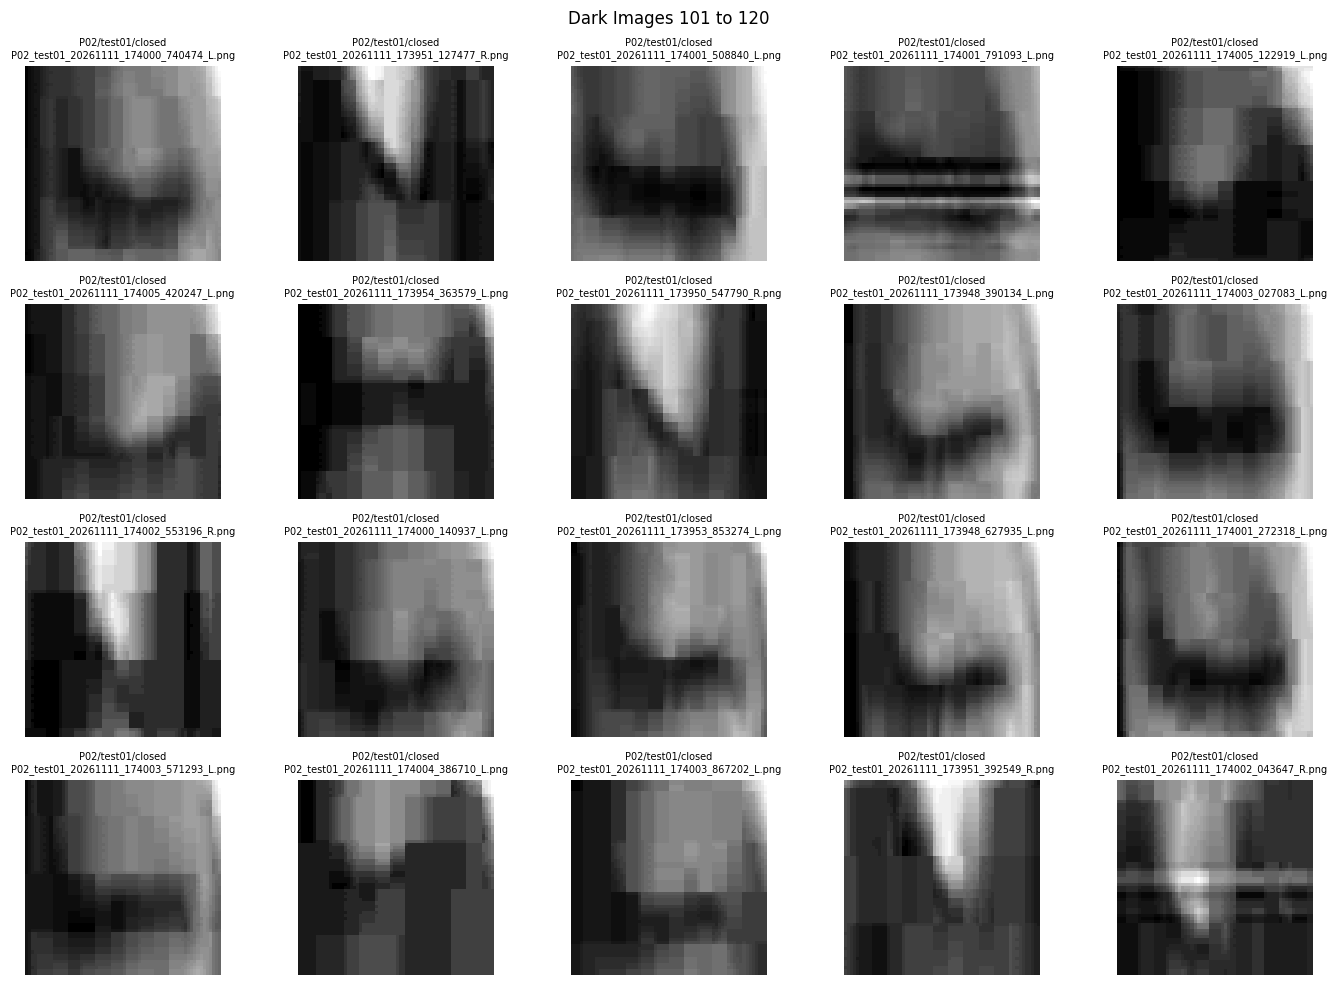

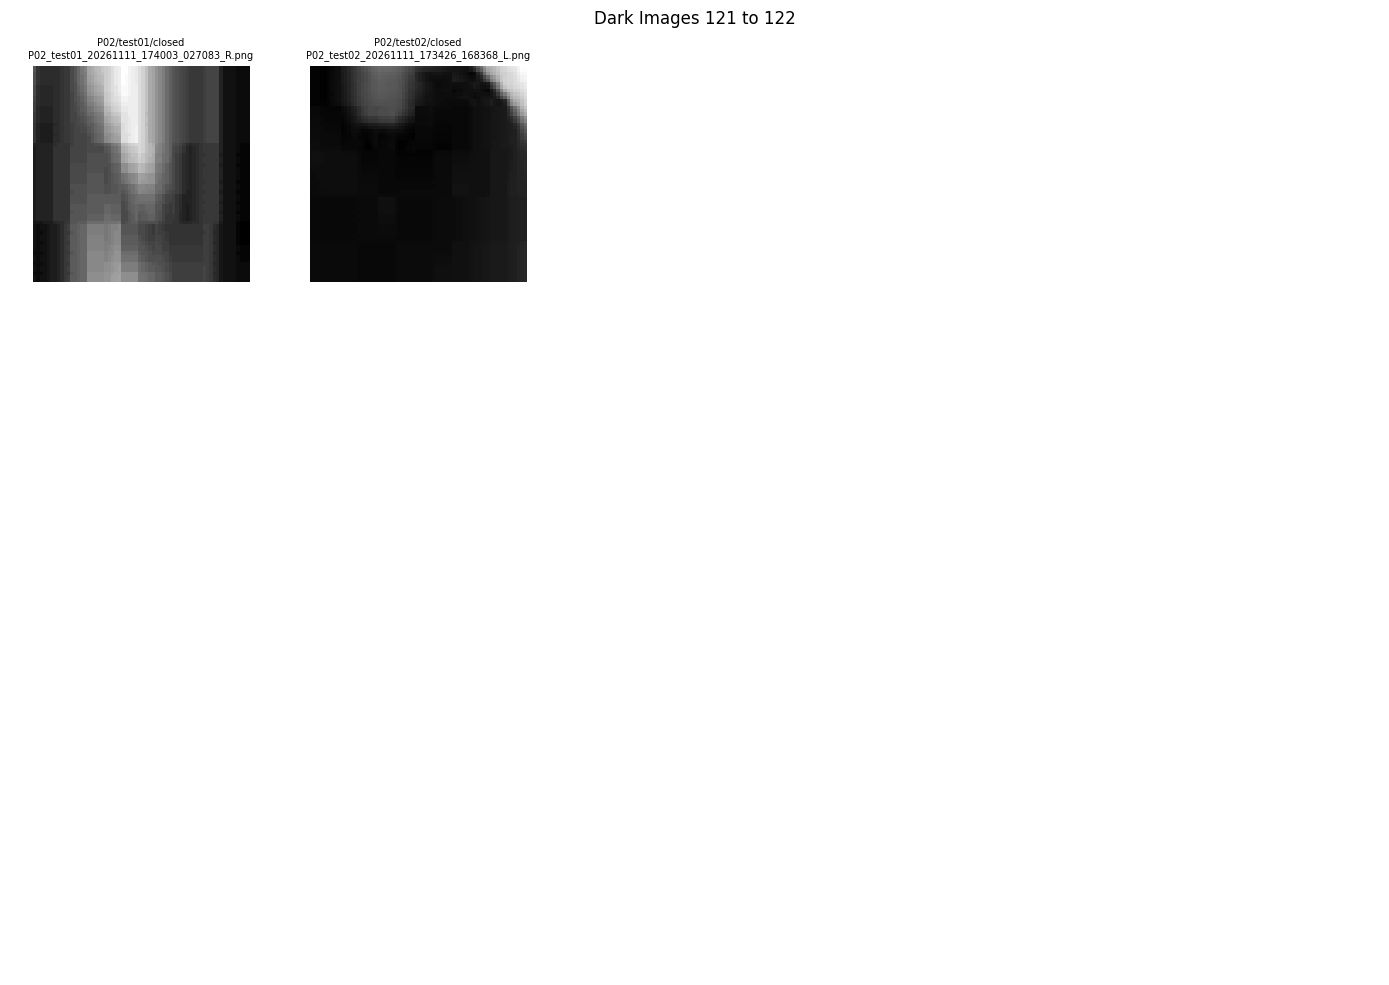

In [46]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import numpy as np

DATA_PATH = Path("/content/SmartCap_Extracted/data_raw")

dark_images = []

for person in sorted(DATA_PATH.glob("P*")):
    for session in sorted(person.iterdir()):
        if not session.is_dir():
            continue

        for label in ["open", "closed"]:
            folder = session / label

            if folder.exists():
                for path in folder.glob("*.png"):
                    with Image.open(path) as img:
                        arr = np.array(img.convert("L"))

                    if arr.mean() < 25:
                        dark_images.append((path, person.name, session.name, label))

for start in range(0, len(dark_images), 20):
    batch = dark_images[start:start+20]

    fig, axes = plt.subplots(4, 5, figsize=(14, 10))

    for ax, (path, person, session, label) in zip(axes.flat, batch):
        with Image.open(path) as img:
            ax.imshow(img.convert("L"), cmap="gray")

        ax.set_title(
            f"{person}/{session}/{label}\n{path.name}",
            fontsize=7
        )
        ax.axis("off")

    for ax in axes.flat[len(batch):]:
        ax.axis("off")

    plt.suptitle(f"Dark Images {start+1} to {start+len(batch)}")
    plt.tight_layout()
    plt.show()

In [47]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("/content/SmartCap_Extracted/data_raw")

image_scores = []

for person in sorted(DATA_PATH.glob("P*")):
    for session in sorted(person.iterdir()):
        if not session.is_dir():
            continue

        for label in ["open", "closed"]:
            folder = session / label

            if not folder.exists():
                continue

            for path in folder.glob("*.png"):
                img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

                if img is None:
                    continue

                score = cv2.Laplacian(img, cv2.CV_64F).var()

                image_scores.append({
                    "path": path,
                    "person": person.name,
                    "session": session.name,
                    "label": label,
                    "score": score
                })

image_scores.sort(key=lambda x: x["score"])

print("TOTAL IMAGES:", len(image_scores))
print("\nLOWEST SHARPNESS SCORES:")

for item in image_scores[:20]:
    print(
        f"{item['person']} | {item['session']} | "
        f"{item['label']} | {item['path'].name} | "
        f"Score: {item['score']:.2f}"
    )

TOTAL IMAGES: 713

LOWEST SHARPNESS SCORES:
P02 | test01 | closed | P02_test01_20261111_173955_442609_L.png | Score: 0.57
P02 | test01 | closed | P02_test01_20261111_173954_886766_L.png | Score: 0.73
P02 | test01 | open | P02_test01_20261111_173939_646639_L.png | Score: 1.27
P02 | test01 | open | P02_test01_20261111_173940_888311_L.png | Score: 1.36
P02 | test01 | closed | P02_test01_20261111_174004_386710_L.png | Score: 1.39
P02 | test01 | closed | P02_test01_20261111_174004_666802_L.png | Score: 1.43
P02 | test01 | open | P02_test01_20261111_173930_329835_L.png | Score: 1.52
P02 | test01 | closed | P02_test01_20261111_173954_649102_L.png | Score: 1.54
P02 | test01 | open | P02_test01_20261111_173929_846135_L.png | Score: 2.01
P02 | test01 | open | P02_test01_20261111_173939_879687_L.png | Score: 2.02
P02 | test01 | open | P02_test01_20261111_173940_391689_L.png | Score: 2.06
P02 | test01 | closed | P02_test01_20261111_174004_884629_L.png | Score: 2.13
P02 | test01 | closed | P02_test

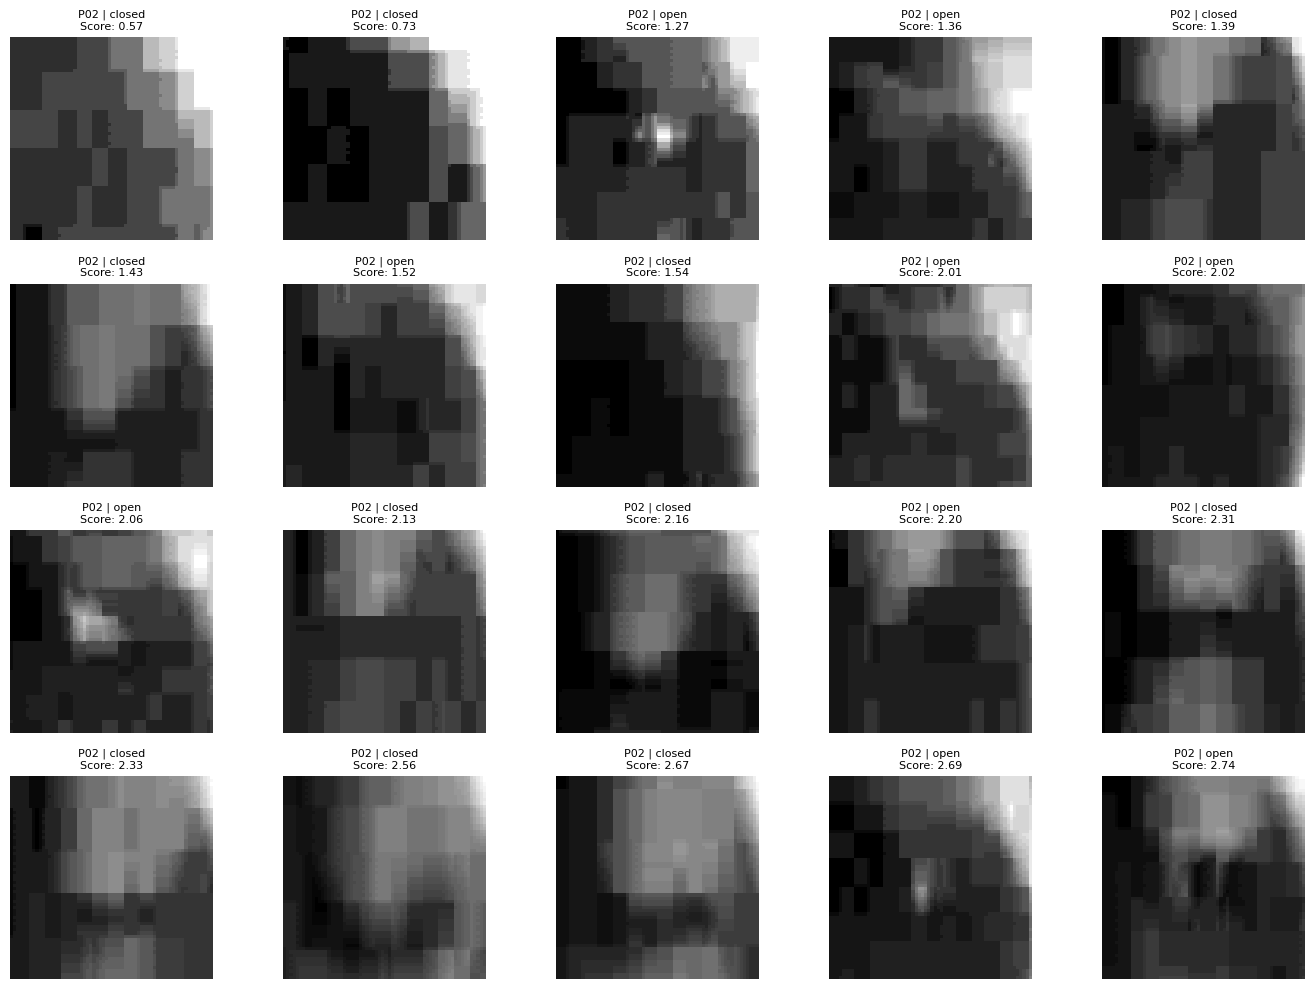

In [48]:
fig, axes = plt.subplots(4, 5, figsize=(14, 10))

for ax, item in zip(axes.flat, image_scores[:20]):
    img = cv2.imread(str(item["path"]), cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap="gray")
    ax.set_title(
        f"{item['person']} | {item['label']}\n"
        f"Score: {item['score']:.2f}",
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [49]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path

DATA_PATH = Path("/content/SmartCap_Extracted/data_raw")

records = []

for person in sorted(DATA_PATH.glob("P*")):
    for session in sorted(person.iterdir()):
        if not session.is_dir():
            continue

        for label in ["open", "closed"]:
            folder = session / label

            if not folder.exists():
                continue

            for path in folder.glob("*.png"):
                img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

                if img is None:
                    continue

                brightness = float(img.mean())
                contrast = float(img.std())
                sharpness = float(
                    cv2.Laplacian(img, cv2.CV_64F).var()
                )

                records.append({
                    "person": person.name,
                    "session": session.name,
                    "label": label,
                    "filename": path.name,
                    "path": str(path),
                    "brightness": brightness,
                    "contrast": contrast,
                    "sharpness": sharpness
                })

df = pd.DataFrame(records)

print("TOTAL:", len(df))

print("\nQUALITY DISTRIBUTION:")

print("Very dark:", (df["brightness"] < 25).sum())
print("Low contrast:", (df["contrast"] < 10).sum())
print("Low sharpness (< 3):", (df["sharpness"] < 3).sum())
print("Very low sharpness (< 1):", (df["sharpness"] < 1).sum())

print("\nBY PERSON AND CLASS:")

print(
    df.groupby(["person", "label"])[
        ["brightness", "contrast", "sharpness"]
    ].mean().round(2)
)

TOTAL: 713

QUALITY DISTRIBUTION:
Very dark: 122
Low contrast: 89
Low sharpness (< 3): 23
Very low sharpness (< 1): 2

BY PERSON AND CLASS:
               brightness  contrast  sharpness
person label                                  
P01    closed       51.68     28.49      36.38
       open         42.90     20.89      19.21
P02    closed      101.84     28.30     118.74
       open        103.70     34.62     204.91


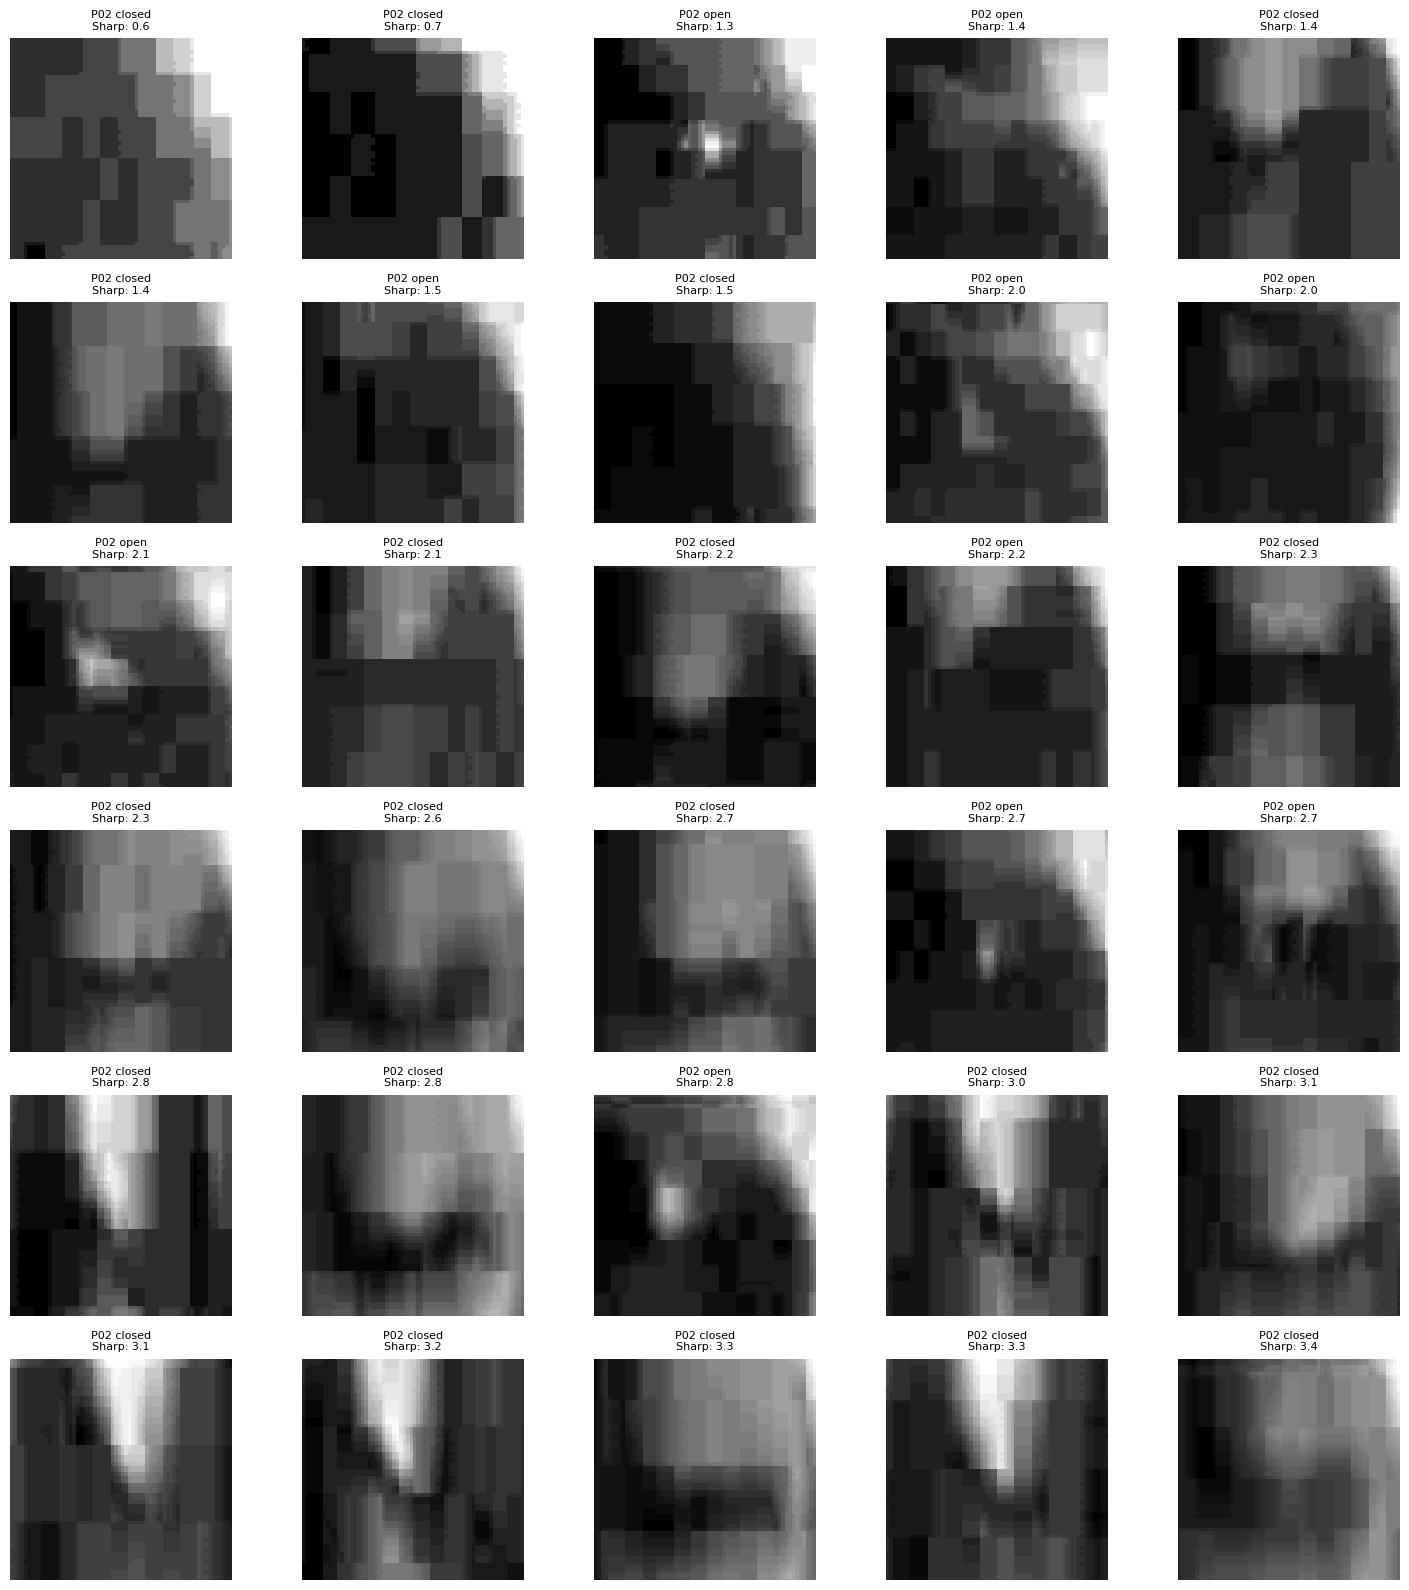

In [50]:
import matplotlib.pyplot as plt

worst = df.nsmallest(30, "sharpness")

fig, axes = plt.subplots(6, 5, figsize=(15, 16))

for ax, (_, item) in zip(axes.flat, worst.iterrows()):
    img = cv2.imread(item["path"], cv2.IMREAD_GRAYSCALE)

    ax.imshow(img, cmap="gray")
    ax.set_title(
        f"{item['person']} {item['label']}\n"
        f"Sharp: {item['sharpness']:.1f}",
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [51]:
suspect = df[
    (df["brightness"] < 25) |
    (df["contrast"] < 10) |
    (df["sharpness"] < 3)
].copy()

print("SUSPECT IMAGES:", len(suspect))

print("\nBY CLASS:")
print(suspect.groupby("label").size())

print("\nBY SESSION:")
print(suspect.groupby(["person", "session", "label"]).size())

suspect.to_csv(
    "/content/SmartCap_quality_review.csv",
    index=False
)

print("\nReport saved successfully.")

SUSPECT IMAGES: 126

BY CLASS:
label
closed    69
open      57
dtype: int64

BY SESSION:
person  session  label 
P01     test01   open       6
P02     test01   closed    68
                 open      51
        test02   closed     1
dtype: int64

Report saved successfully.


In [52]:
import numpy as np

df["dark"] = df["brightness"] < 25
df["low_contrast"] = df["contrast"] < 10
df["blurry"] = df["sharpness"] < 3

print("REASON COUNTS:")
print("Dark only:", (
    df["dark"] & ~df["low_contrast"] & ~df["blurry"]
).sum())

print("Low contrast only:", (
    df["low_contrast"] & ~df["dark"] & ~df["blurry"]
).sum())

print("Blurry only:", (
    df["blurry"] & ~df["dark"] & ~df["low_contrast"]
).sum())

print("Multiple issues:", (
    df[["dark", "low_contrast", "blurry"]].sum(axis=1) > 1
).sum())

print("\nBY SESSION:")
print(
    df.groupby(["person", "session"])[
        ["dark", "low_contrast", "blurry"]
    ].sum()
)

REASON COUNTS:
Dark only: 37
Low contrast only: 4
Blurry only: 0
Multiple issues: 85

BY SESSION:
                dark  low_contrast  blurry
person session                            
P01    test01      6             2       0
P02    test01    115            87      23
       test02      1             0       0


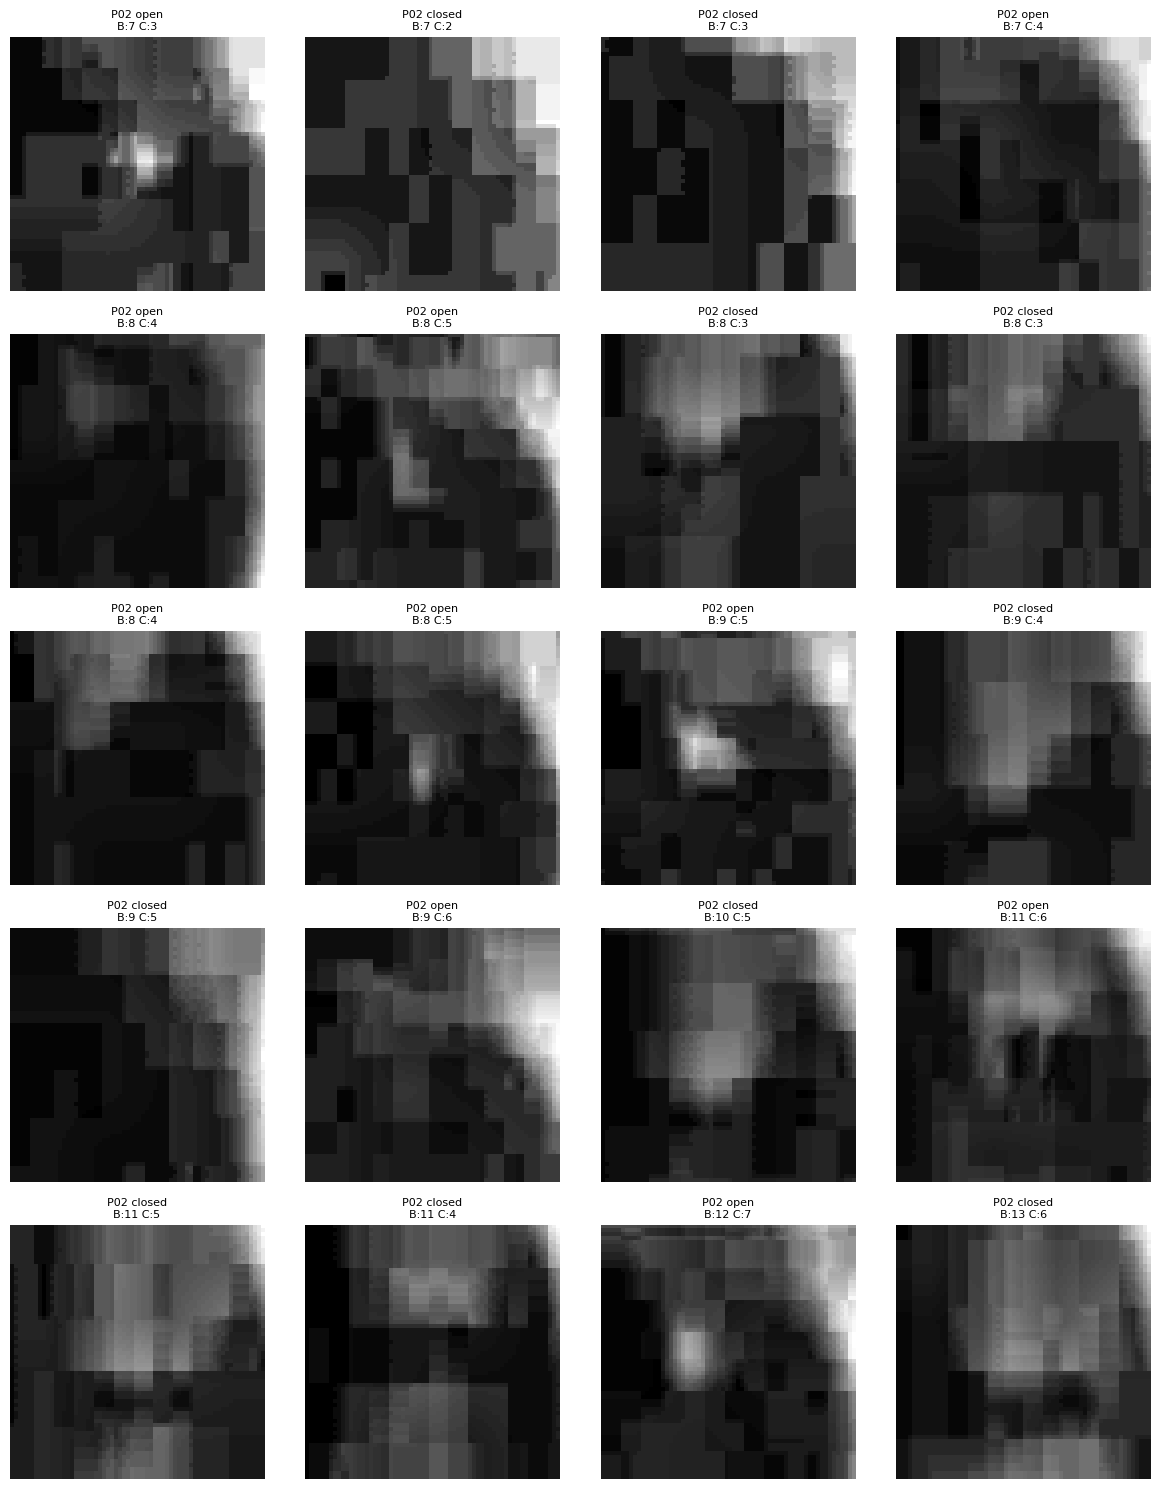

In [53]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# أسوأ 20 صورة حسب اجتماع مشاكل الجودة
worst = df.copy()

worst["issues"] = (
    worst["dark"].astype(int)
    + worst["low_contrast"].astype(int)
    + worst["blurry"].astype(int)
)

worst = worst.sort_values(
    ["issues", "brightness", "sharpness"],
    ascending=[False, True, True]
).head(20)

fig, axes = plt.subplots(5, 4, figsize=(12, 15))

for ax, (_, item) in zip(axes.flat, worst.iterrows()):
    img = cv2.imread(item["path"], cv2.IMREAD_GRAYSCALE)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(4, 4)
    )

    enhanced = clahe.apply(img)

    ax.imshow(enhanced, cmap="gray")
    ax.set_title(
        f"{item['person']} {item['label']}\n"
        f"B:{item['brightness']:.0f} "
        f"C:{item['contrast']:.0f}",
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

Images to review: 126


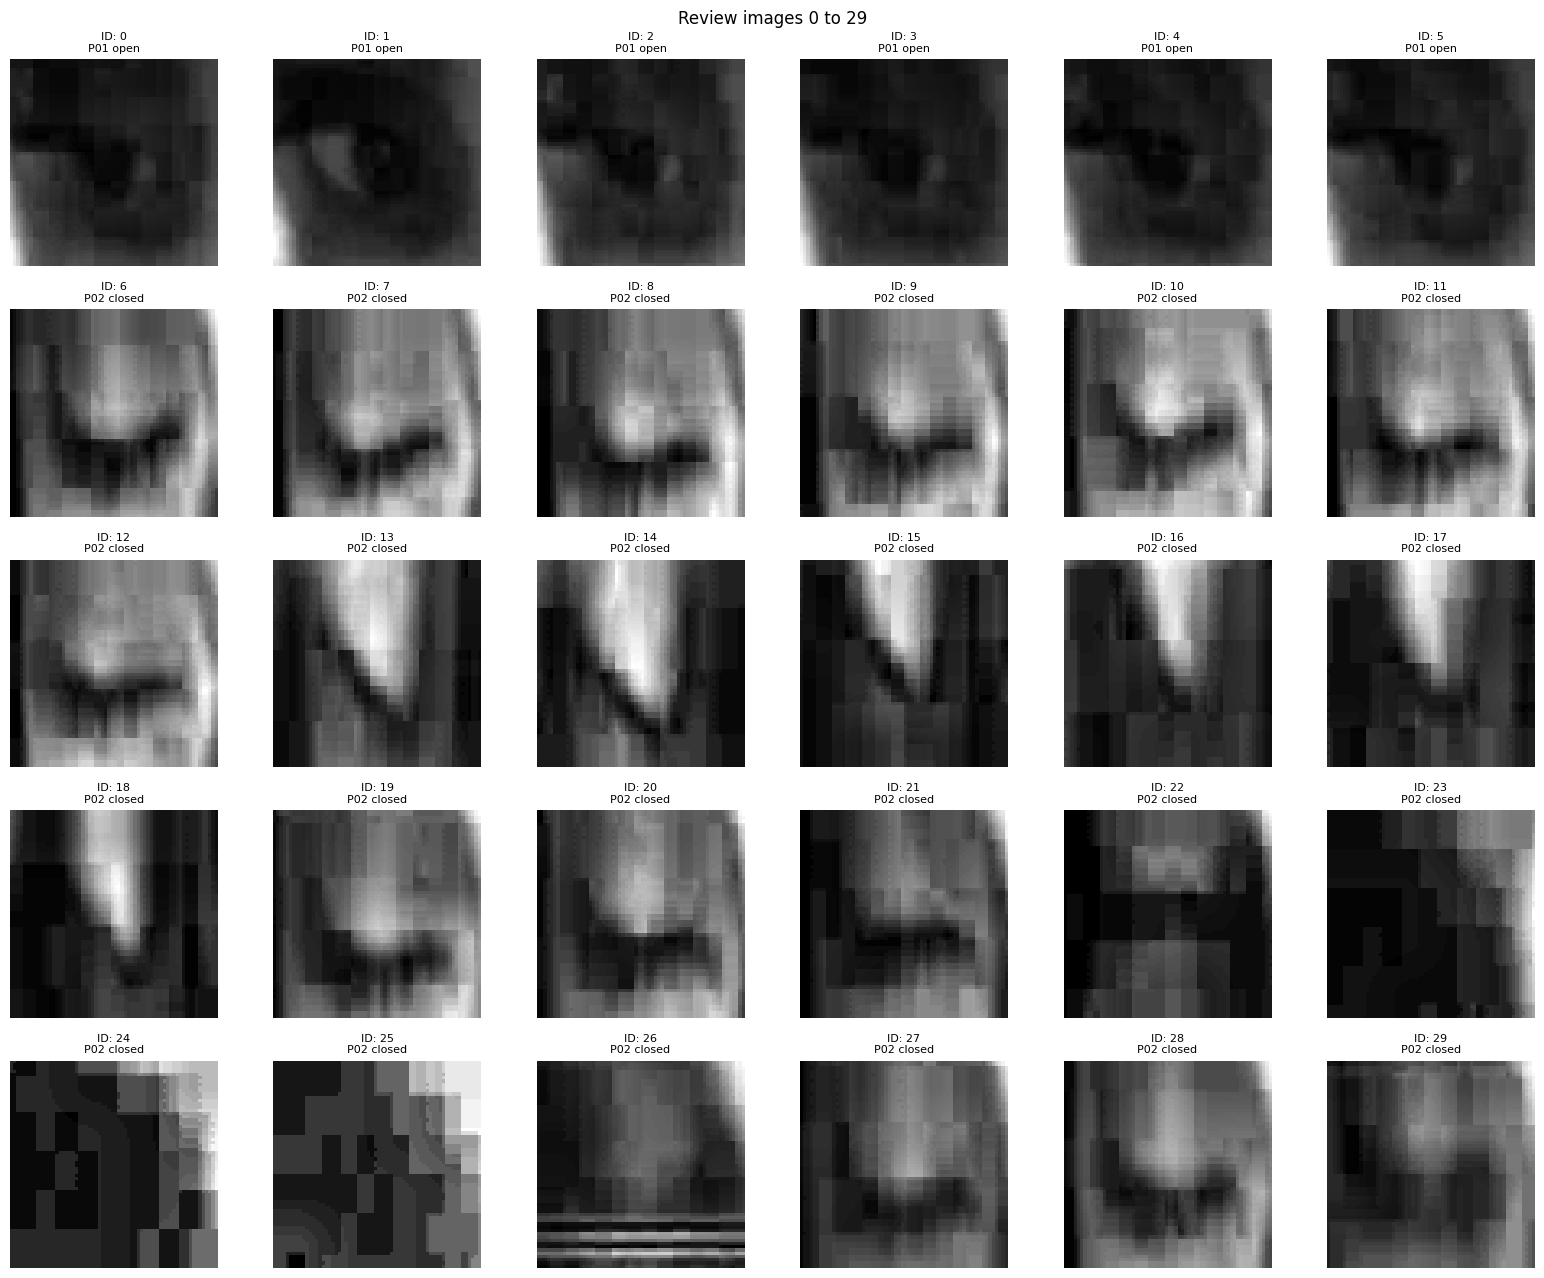

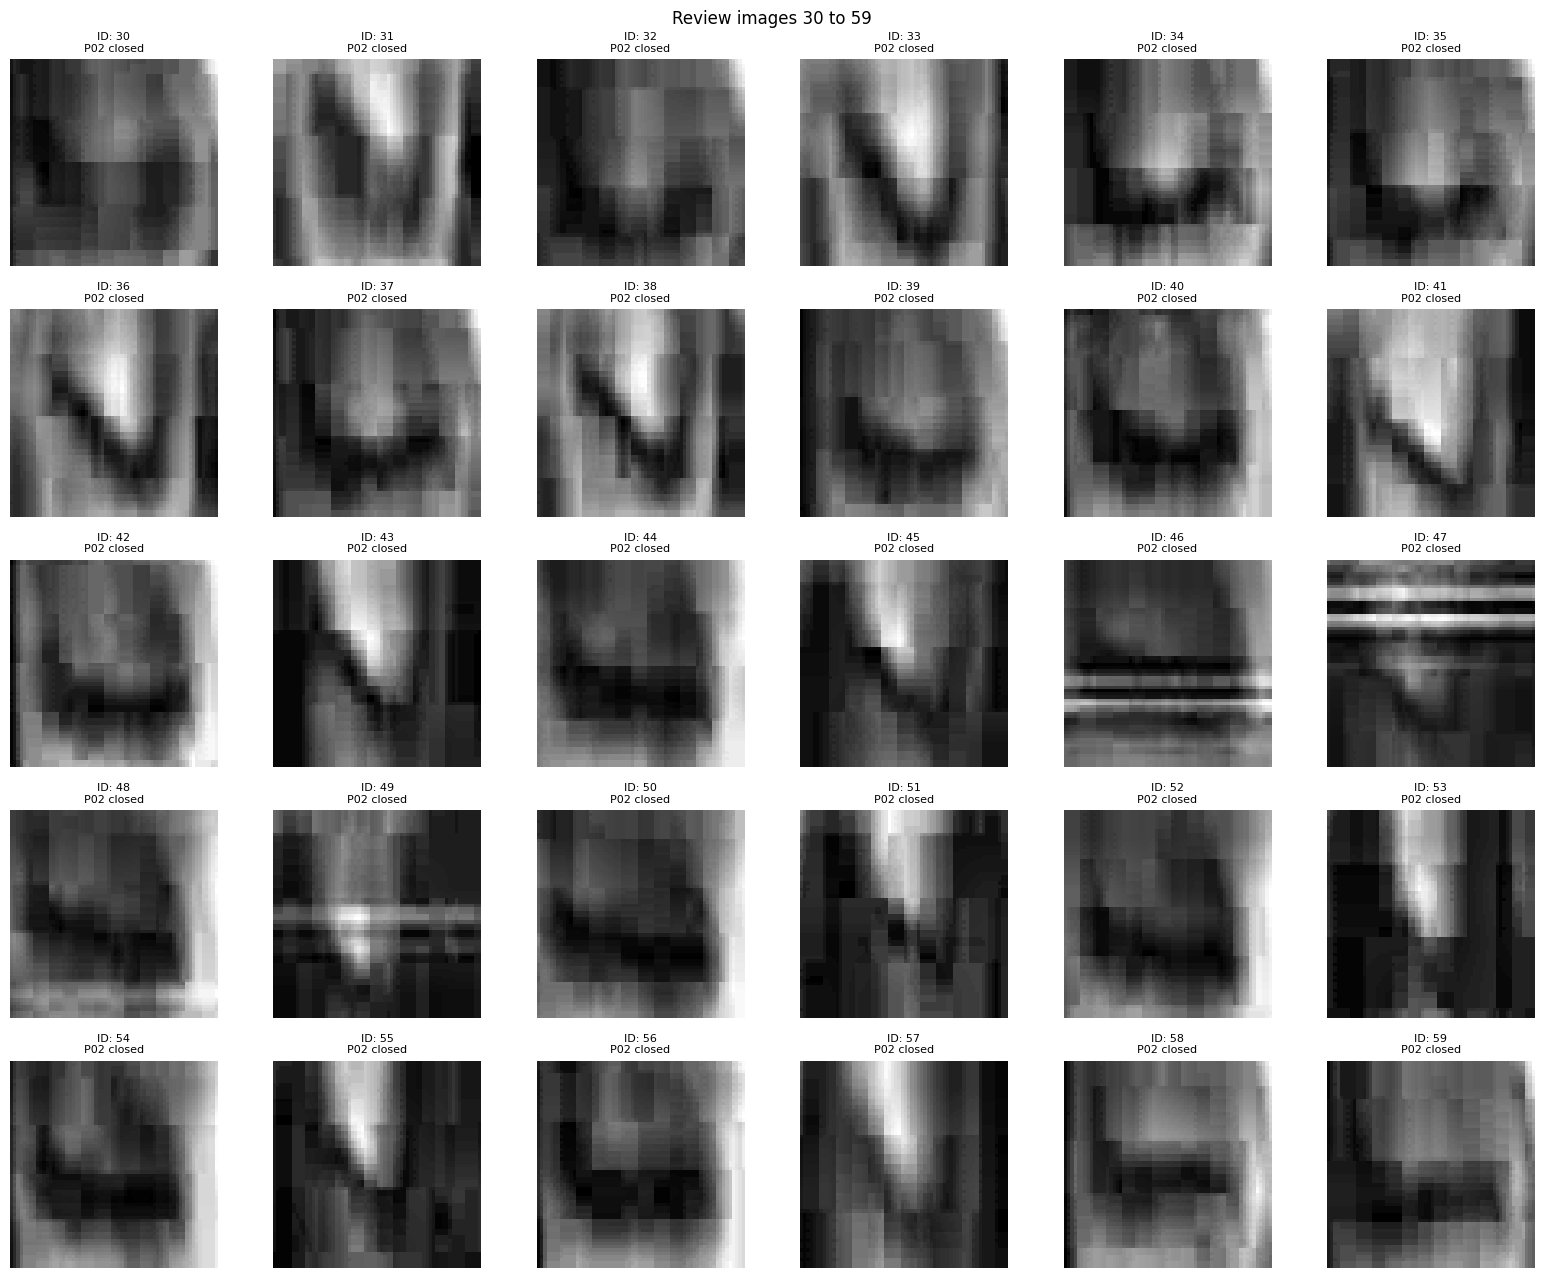

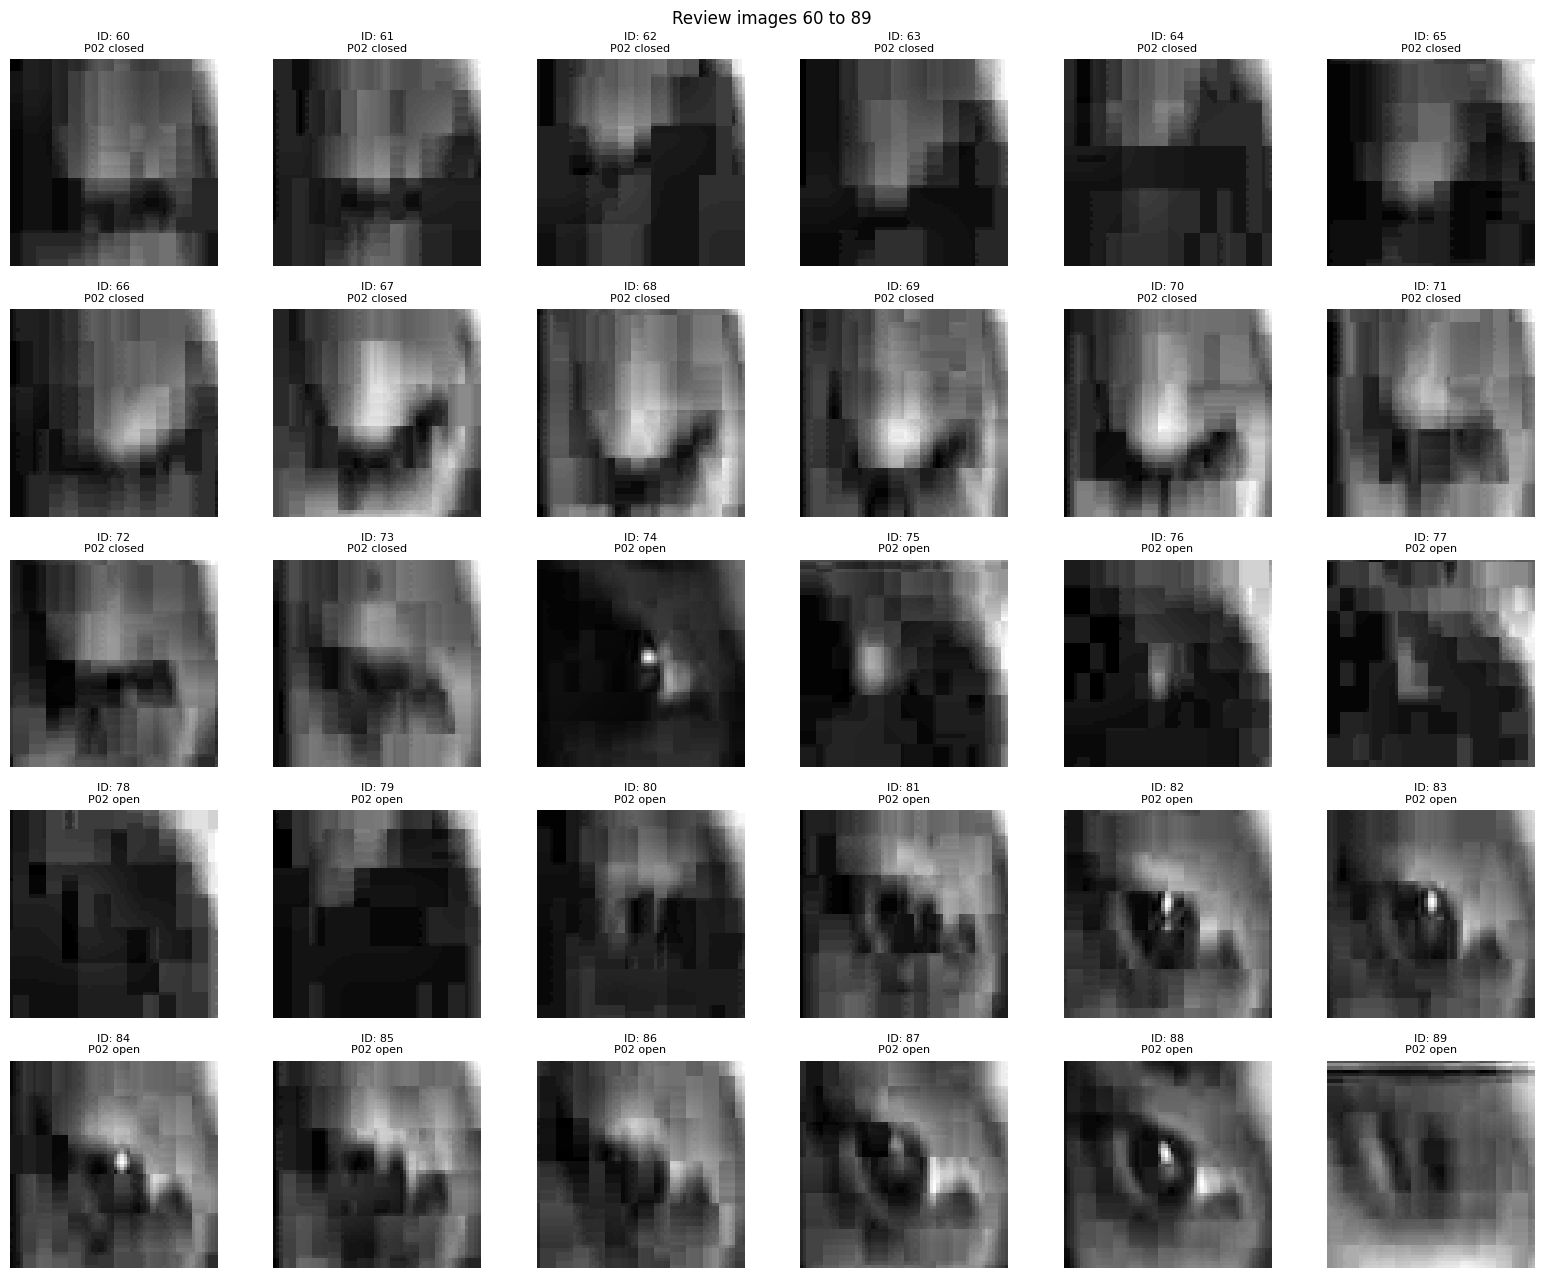

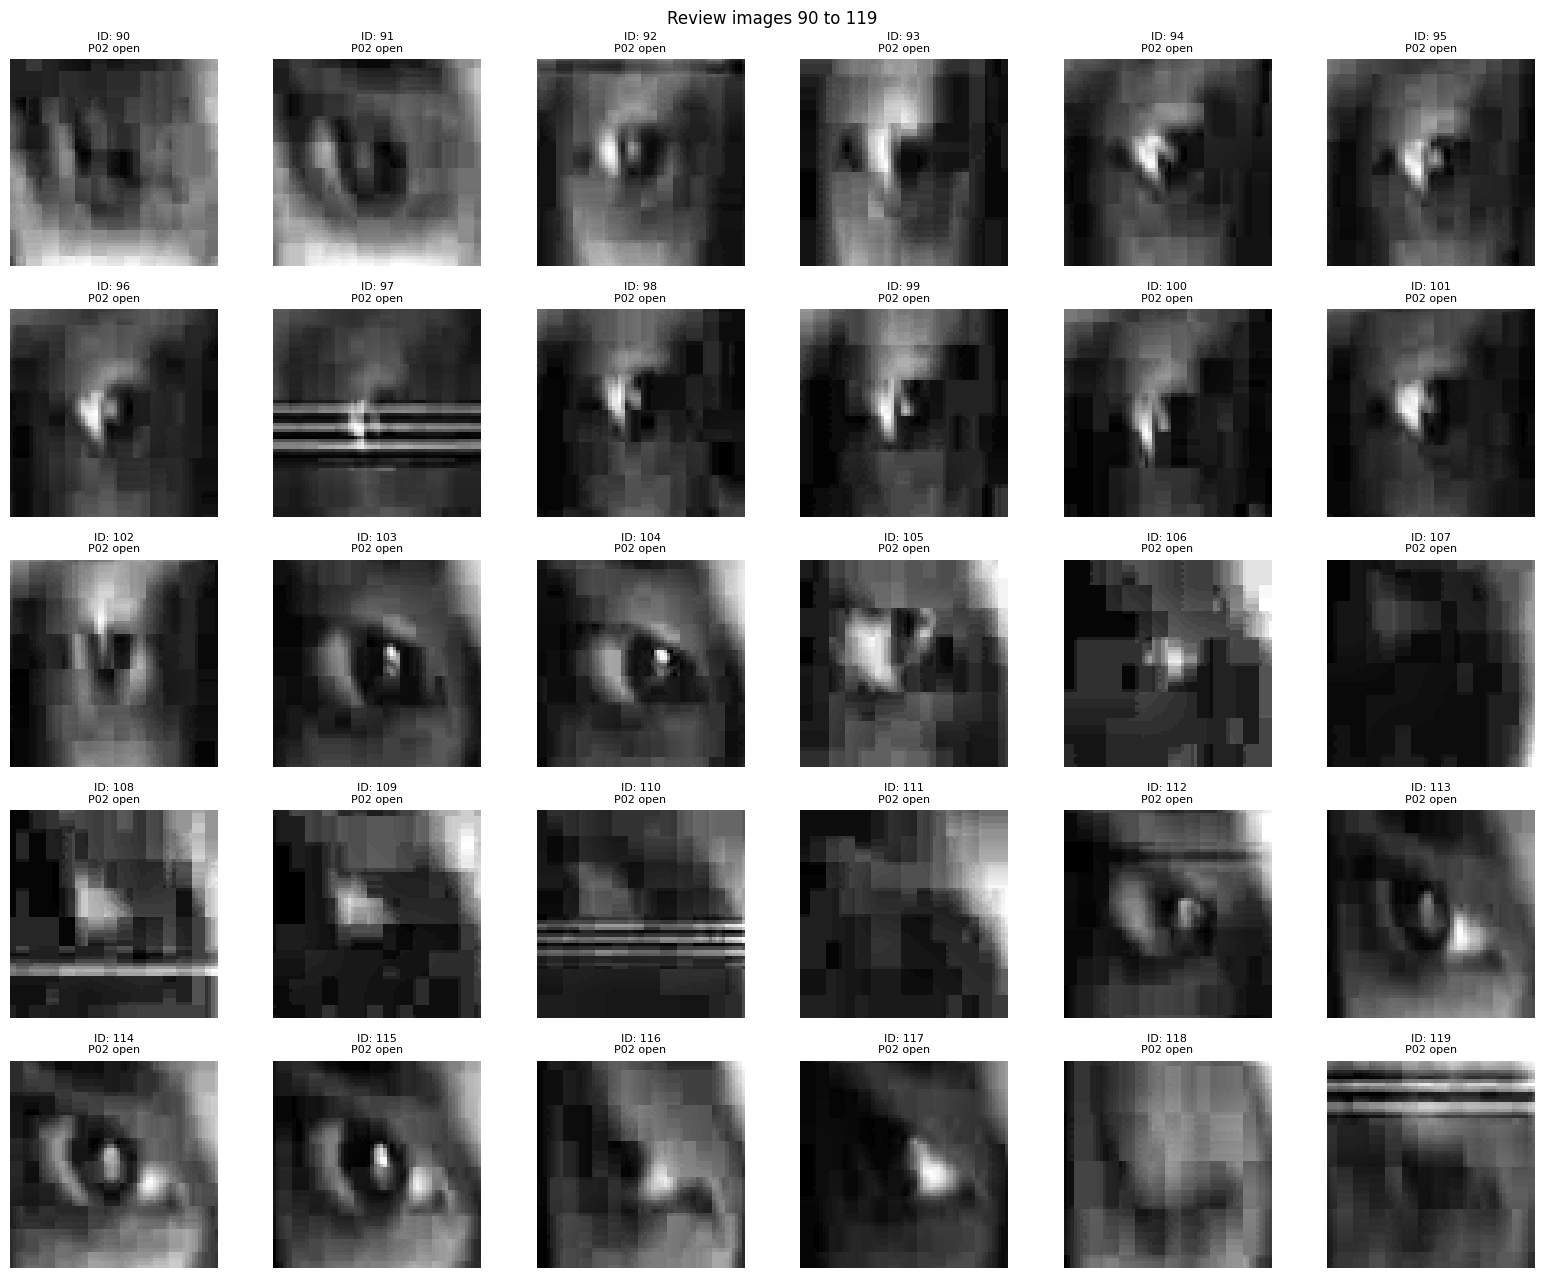

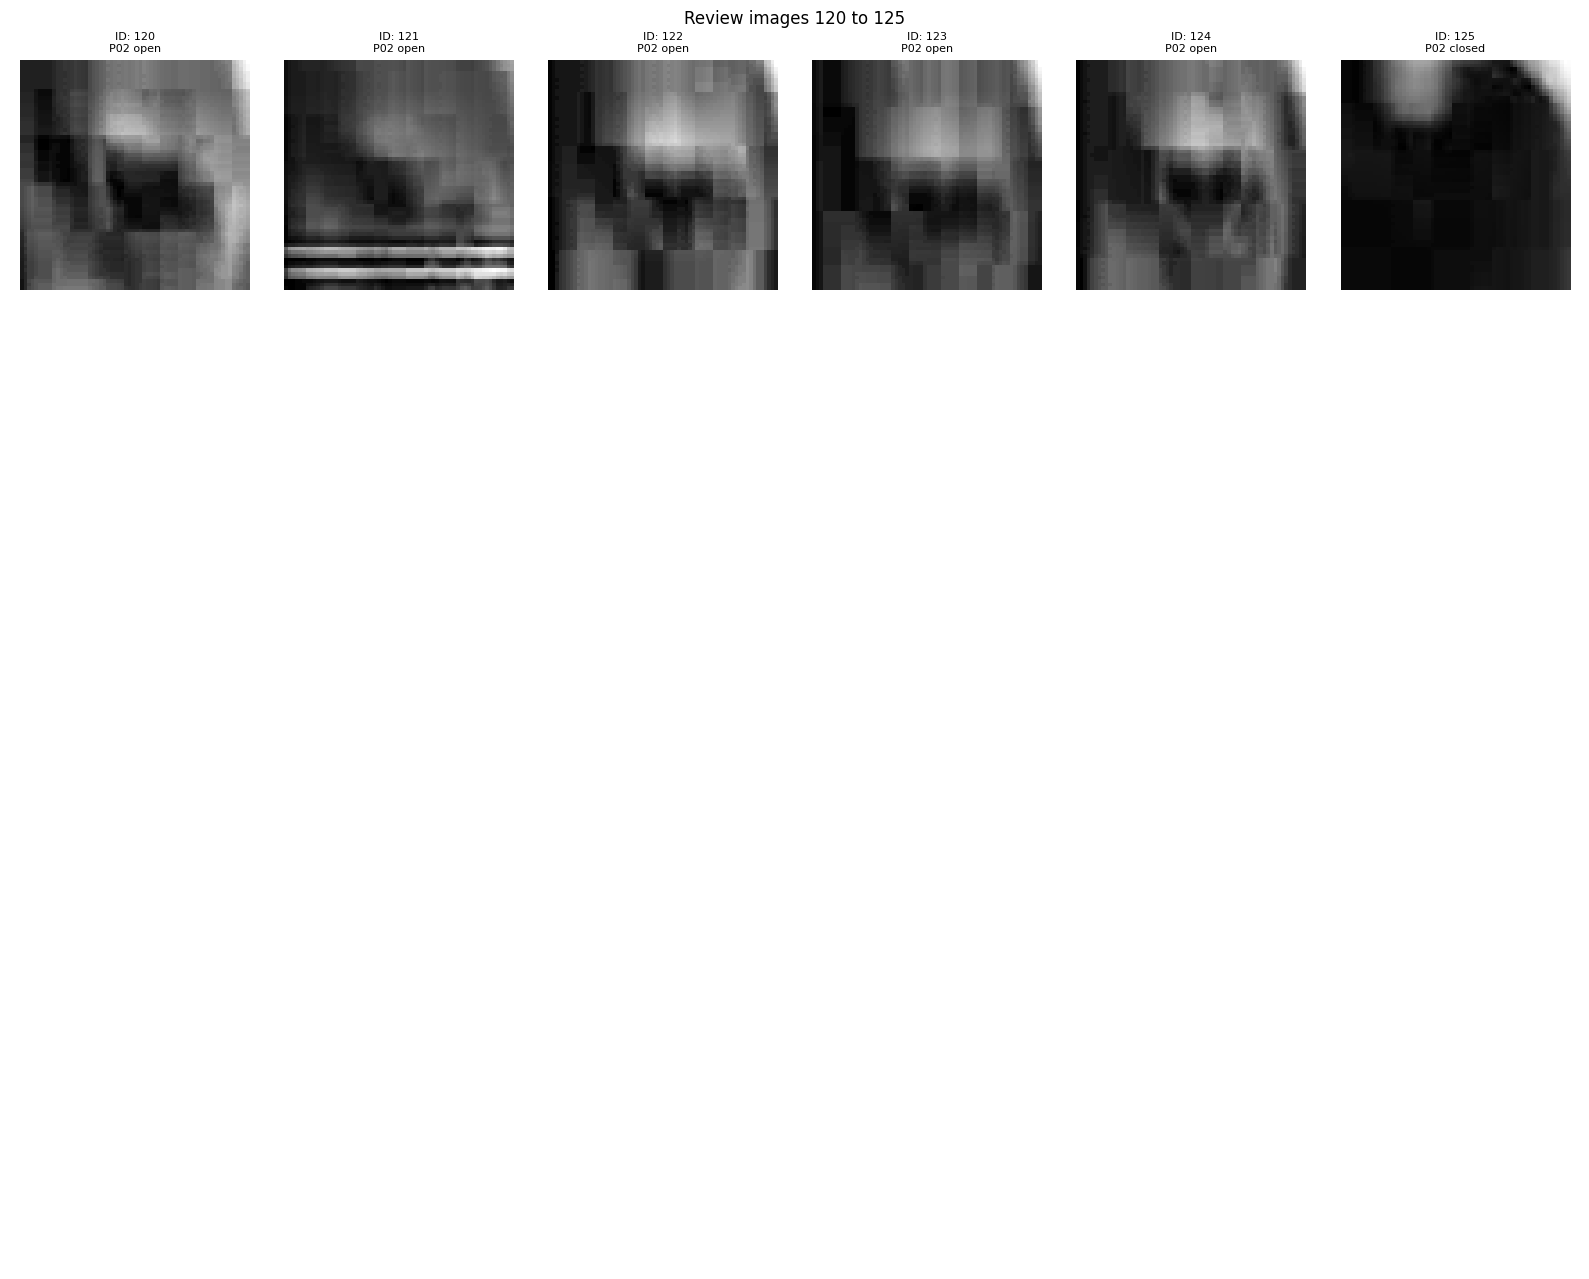

In [54]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# ترتيب ثابت للصور المشتبه فيها
review_df = suspect.sort_values("path").reset_index(drop=True)

print("Images to review:", len(review_df))

for start in range(0, len(review_df), 30):
    batch = review_df.iloc[start:start+30]

    fig, axes = plt.subplots(5, 6, figsize=(16, 13))

    for ax in axes.flat:
        ax.axis("off")

    for ax, (idx, item) in zip(axes.flat, batch.iterrows()):
        img = cv2.imread(item["path"], cv2.IMREAD_GRAYSCALE)

        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(4, 4)
        )
        enhanced = clahe.apply(img)

        ax.imshow(enhanced, cmap="gray")
        ax.set_title(
            f"ID: {idx}\n{item['person']} {item['label']}",
            fontsize=8
        )
        ax.axis("off")

    plt.suptitle(
        f"Review images {start} to {start + len(batch) - 1}"
    )
    plt.tight_layout()
    plt.show()

In [55]:
from pathlib import Path
from PIL import Image
import numpy as np

DATA_PATH = Path("/content/SmartCap_Extracted/data_raw")

X_new = []
y_new = []

# 0 = Open, 1 = Closed
label_map = {
    "open": 0,
    "closed": 1
}

for person in sorted(DATA_PATH.glob("P*")):
    for session in sorted(person.iterdir()):
        if not session.is_dir():
            continue

        for label, class_id in label_map.items():
            folder = session / label

            if not folder.exists():
                continue

            for img_path in sorted(folder.glob("*.png")):
                with Image.open(img_path) as img:
                    arr = np.array(img.convert("L"), dtype=np.float32)

                X_new.append(arr)
                y_new.append(class_id)

X_new = np.array(X_new, dtype=np.float32)
y_new = np.array(y_new, dtype=np.int64)

# Normalize pixels
X_new = X_new / 255.0

# Add channel dimension
X_new = X_new[..., np.newaxis]

np.savez_compressed(
    "/content/SmartCap_New_Data_Processed.npz",
    X=X_new,
    y=y_new
)

print("X shape:", X_new.shape)
print("y shape:", y_new.shape)
print("Open:", np.sum(y_new == 0))
print("Closed:", np.sum(y_new == 1))
print("Saved successfully!")

X shape: (713, 64, 64, 1)
y shape: (713,)
Open: 364
Closed: 349
Saved successfully!


In [56]:
import numpy as np

MRL_PATH = "/content/mrl_64.npz"

data = np.load(MRL_PATH)

print("Available keys:", data.files)

for key in data.files:
    arr = data[key]

    print(f"\nKey: {key}")
    print("Shape:", arr.shape)
    print("Dtype:", arr.dtype)
    print("Min:", arr.min())
    print("Max:", arr.max())

Available keys: ['Xtr', 'ytr', 'Xva', 'yva', 'Xte', 'yte']

Key: Xtr
Shape: (67372, 64, 64)
Dtype: uint8
Min: 0
Max: 255

Key: ytr
Shape: (67372,)
Dtype: int64
Min: 0
Max: 1

Key: Xva
Shape: (8955, 64, 64)
Dtype: uint8
Min: 5
Max: 255

Key: yva
Shape: (8955,)
Dtype: int64
Min: 0
Max: 1

Key: Xte
Shape: (8571, 64, 64)
Dtype: uint8
Min: 7
Max: 255

Key: yte
Shape: (8571,)
Dtype: int64
Min: 0
Max: 1


In [57]:
import numpy as np

data = np.load("/content/mrl_64.npz")

for split in ["tr", "va", "te"]:
    y = data[f"y{split}"]

    unique, counts = np.unique(y, return_counts=True)

    print(f"\n===== MRL {split.upper()} =====")

    for label, count in zip(unique, counts):
        print(f"Label {label}: {count} ({count / len(y) * 100:.2f}%)")

    print("Total:", len(y))


print("\n===== SMARTCAP NEW DATA =====")

unique, counts = np.unique(y_new, return_counts=True)

for label, count in zip(unique, counts):
    print(f"Label {label}: {count} ({count / len(y_new) * 100:.2f}%)")


===== MRL TR =====
Label 0: 34294 (50.90%)
Label 1: 33078 (49.10%)
Total: 67372

===== MRL VA =====
Label 0: 4540 (50.70%)
Label 1: 4415 (49.30%)
Total: 8955

===== MRL TE =====
Label 0: 4118 (48.05%)
Label 1: 4453 (51.95%)
Total: 8571

===== SMARTCAP NEW DATA =====
Label 0: 364 (51.05%)
Label 1: 349 (48.95%)


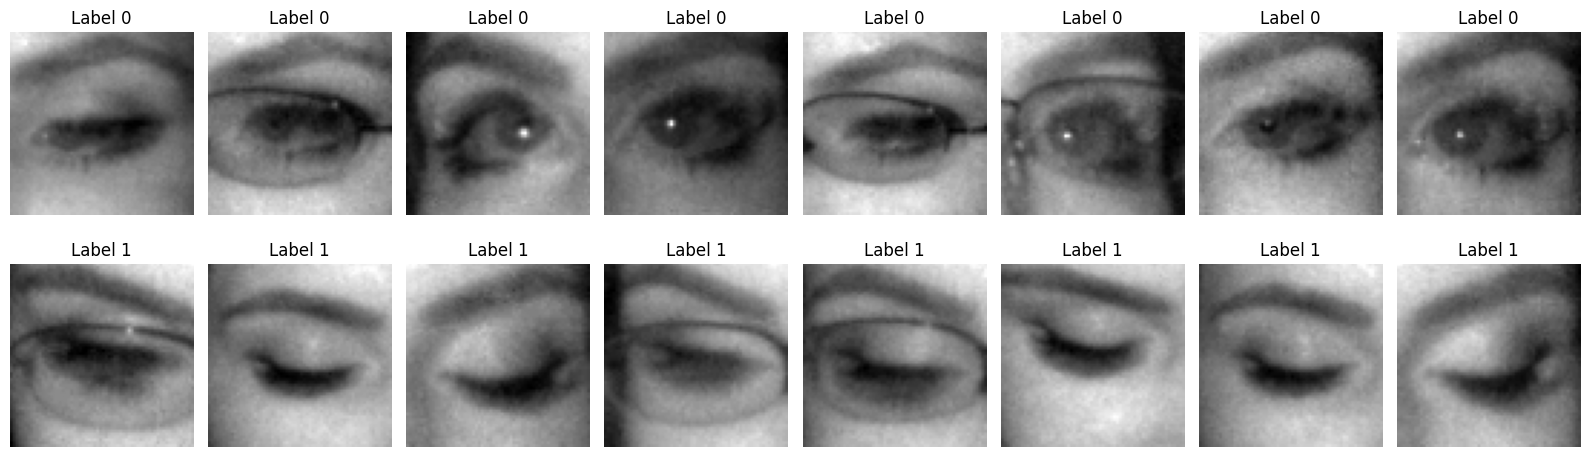

In [58]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

data = np.load("/content/mrl_64.npz")

fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for label in [0, 1]:
    indices = np.where(data["ytr"] == label)[0][:8]

    for ax, idx in zip(axes[label], indices):
        ax.imshow(data["Xtr"][idx], cmap="gray")
        ax.set_title(f"Label {label}")
        ax.axis("off")

plt.tight_layout()
plt.show()

In [59]:
from pathlib import Path

P01_PATH = Path("/content/SmartCap_Extracted/data_raw/P01")

for folder in ["open", "closed"]:
    total = 0

    for path in P01_PATH.rglob(folder):
        if path.is_dir():
            total += len(list(path.glob("*.png")))

    print(folder.upper(), ":", total)

OPEN : 28
CLOSED : 18


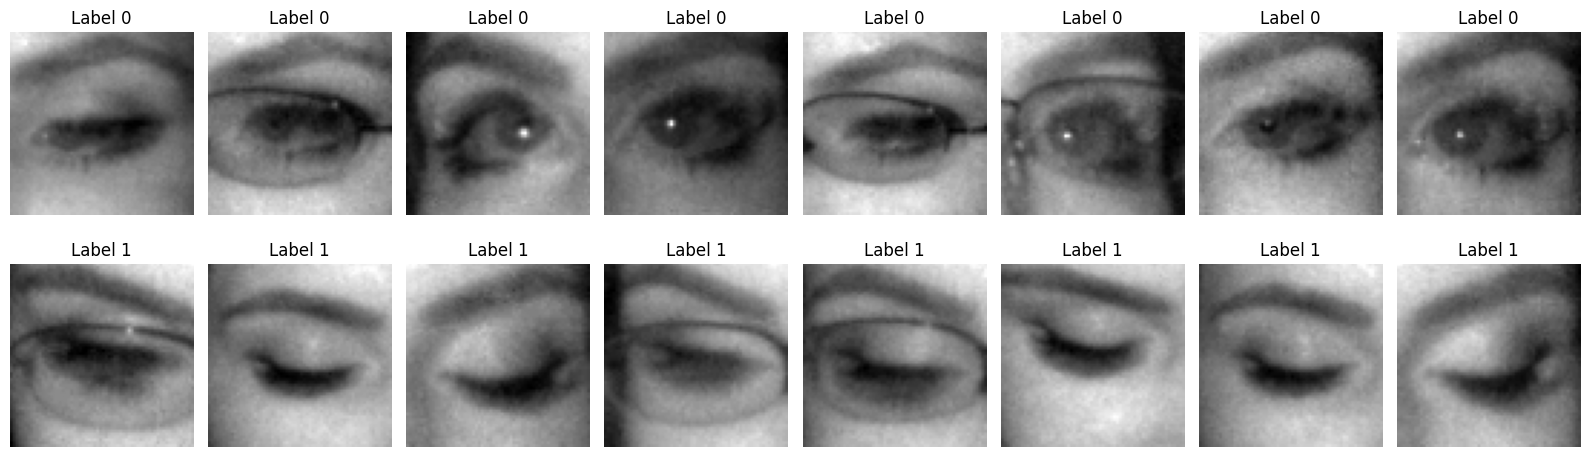

In [60]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load("/content/mrl_64.npz")

fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for label in [0, 1]:
    indices = np.where(data["ytr"] == label)[0][:8]

    for ax, idx in zip(axes[label], indices):
        ax.imshow(data["Xtr"][idx], cmap="gray")
        ax.set_title(f"Label {label}")
        ax.axis("off")

plt.tight_layout()
plt.show()

In [61]:
import numpy as np
from pathlib import Path
from PIL import Image

# =====================================
# 1. Load MRL dataset
# =====================================

mrl = np.load("/content/mrl_64.npz")

X_mrl_train = mrl["Xtr"].astype(np.float32) / 255.0
y_mrl_train = mrl["ytr"].astype(np.int64)

X_mrl_val = mrl["Xva"].astype(np.float32) / 255.0
y_mrl_val = mrl["yva"].astype(np.int64)

X_mrl_test = mrl["Xte"].astype(np.float32) / 255.0
y_mrl_test = mrl["yte"].astype(np.int64)

# Add channel dimension
X_mrl_train = X_mrl_train[..., np.newaxis]
X_mrl_val = X_mrl_val[..., np.newaxis]
X_mrl_test = X_mrl_test[..., np.newaxis]


# =====================================
# 2. Load SmartCap images
# =====================================

DATA_PATH = Path("/content/SmartCap_Extracted/data_raw")

def load_smartcap_sessions(session_names):
    images = []
    labels = []

    for person in sorted(DATA_PATH.glob("P*")):
        for session in sorted(person.iterdir()):

            if not session.is_dir():
                continue

            if (person.name, session.name) not in session_names:
                continue

            for label_name, label_id in [
                ("open", 0),
                ("closed", 1)
            ]:
                folder = session / label_name

                for image_path in sorted(folder.glob("*.png")):
                    with Image.open(image_path) as img:
                        arr = np.array(
                            img.convert("L"),
                            dtype=np.float32
                        )

                    images.append(arr / 255.0)
                    labels.append(label_id)

    X = np.array(images, dtype=np.float32)[..., np.newaxis]
    y = np.array(labels, dtype=np.int64)

    return X, y


# P01/test01 + P02/test01 for training
X_smart_train, y_smart_train = load_smartcap_sessions([
    ("P01", "test01"),
    ("P02", "test01")
])

# P02/test02 reserved for independent testing
X_smart_test, y_smart_test = load_smartcap_sessions([
    ("P02", "test02")
])


# =====================================
# 3. Merge training data
# =====================================

X_train = np.concatenate(
    [X_mrl_train, X_smart_train],
    axis=0
)

y_train = np.concatenate(
    [y_mrl_train, y_smart_train],
    axis=0
)

# Shuffle training data only
rng = np.random.default_rng(42)
indices = rng.permutation(len(X_train))

X_train = X_train[indices]
y_train = y_train[indices]


# =====================================
# 4. Save merged dataset
# =====================================

np.savez_compressed(
    "/content/SmartCap_MRL_Merged.npz",
    X_train=X_train,
    y_train=y_train,
    X_val=X_mrl_val,
    y_val=y_mrl_val,
    X_test_mrl=X_mrl_test,
    y_test_mrl=y_mrl_test,
    X_test_smartcap=X_smart_test,
    y_test_smartcap=y_smart_test
)


# =====================================
# 5. Print final information
# =====================================

print("========== FINAL DATASET ==========")

print("\nTRAINING")
print("Shape:", X_train.shape)
print("Open:", np.sum(y_train == 0))
print("Closed:", np.sum(y_train == 1))

print("\nVALIDATION")
print("Shape:", X_mrl_val.shape)

print("\nMRL TEST")
print("Shape:", X_mrl_test.shape)

print("\nSMARTCAP TEST")
print("Shape:", X_smart_test.shape)
print("Open:", np.sum(y_smart_test == 0))
print("Closed:", np.sum(y_smart_test == 1))

print("\nSaved: /content/SmartCap_MRL_Merged.npz")

========== FINAL DATASET ==========

TRAINING
Shape: (67698, 64, 64, 1)
Open: 34458
Closed: 33240

VALIDATION
Shape: (8955, 64, 64, 1)

MRL TEST
Shape: (8571, 64, 64, 1)

SMARTCAP TEST
Shape: (387, 64, 64, 1)
Open: 200
Closed: 187

Saved: /content/SmartCap_MRL_Merged.npz


In [62]:
import tensorflow as tf
from pathlib import Path

MODEL_PATH = "/content/best_eye_model_v2.keras"

print("Model exists:", Path(MODEL_PATH).exists())

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("\n========== MODEL SUMMARY ==========")
model.summary()

print("\nInput shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total parameters:", model.count_params())

Model exists: True

========== MODEL SUMMARY ==========


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 682,753 (2.60 MB)

 Trainable params: 682,753 (2.60 MB)

 Non-trainable params: 0 (0.00 B)


Input shape: (None, 64, 64, 1)
Output shape: (None, 1)
Total parameters: 682753


In [63]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

MODEL_PATH = "/content/best_eye_model_v2.keras"
DATA_PATH = "/content/SmartCap_MRL_Merged.npz"

# Load model
model = tf.keras.models.load_model(MODEL_PATH, compile=False)

# Confirm final activation
print("Final layer activation:",
      model.layers[-1].get_config().get("activation"))

# Load merged datasets
data = np.load(DATA_PATH)

X_mrl_test = data["X_mrl_test"]
y_mrl_test = data["y_mrl_test"]

X_smartcap_test = data["X_smartcap_test"]
y_smartcap_test = data["y_smartcap_test"]

# Compile for binary classification
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

def evaluate_dataset(name, X, y):
    predictions = model.predict(X, verbose=0).reshape(-1)

    # Convert sigmoid probabilities to class labels
    y_pred = (predictions >= 0.5).astype(int)
    y_true = y.astype(int).reshape(-1)

    print(f"\n{'='*45}")
    print(name)
    print(f"{'='*45}")

    print("Images:", len(y_true))
    print(f"Accuracy: {accuracy_score(y_true, y_pred) * 100:.2f}%")

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=["Open", "Closed"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

# Evaluate original MRL test
evaluate_dataset(
    "MRL TEST",
    X_mrl_test,
    y_mrl_test
)

# Evaluate independent SmartCap test
evaluate_dataset(
    "SMARTCAP TEST - P02/test02",
    X_smartcap_test,
    y_smartcap_test
)


Final layer activation: sigmoid


KeyError: 'X_mrl_test is not a file in the archive'

In [64]:
import numpy as np

DATA_PATH = "/content/SmartCap_MRL_Merged.npz"

data = np.load(DATA_PATH)

print("Available keys:")
for key in data.files:
    print(f"{key}: shape = {data[key].shape}, dtype = {data[key].dtype}")

Available keys:
X_train: shape = (67698, 64, 64, 1), dtype = float32
y_train: shape = (67698,), dtype = int64
X_val: shape = (8955, 64, 64, 1), dtype = float32
y_val: shape = (8955,), dtype = int64
X_test_mrl: shape = (8571, 64, 64, 1), dtype = float32
y_test_mrl: shape = (8571,), dtype = int64
X_test_smartcap: shape = (387, 64, 64, 1), dtype = float32
y_test_smartcap: shape = (387,), dtype = int64


In [65]:
import numpy as np
from pathlib import Path

# Inspect processed SmartCap data
path = "/content/SmartCap_New_Data_Processed.npz"
data = np.load(path)

print("Processed data keys:")
for key in data.files:
    print(key, data[key].shape, data[key].dtype)

# Check P01 original folders
p01_path = Path("/content/SmartCap_Extracted/data_raw/P01")

print("\nP01 files:")
for folder in ["test01/open", "test01/closed"]:
    folder_path = p01_path / folder
    files = list(folder_path.glob("*")) if folder_path.exists() else []
    print(folder, "=", len(files))

Processed data keys:
X (713, 64, 64, 1) float32
y (713,) int64

P01 files:
test01/open = 28
test01/closed = 18


In [66]:

import numpy as np
import tensorflow as tf
from pathlib import Path
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# =====================================
# 1. Load model
# =====================================

MODEL_PATH = "/content/best_eye_model_v2.keras"
DATA_PATH = "/content/SmartCap_MRL_Merged.npz"

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

# =====================================
# 2. Load MRL and P02 test data
# =====================================

data = np.load(DATA_PATH)

X_mrl = data["X_test_mrl"]
y_mrl = data["y_test_mrl"]

X_p02 = data["X_test_smartcap"]
y_p02 = data["y_test_smartcap"]

# =====================================
# 3. Load P01 images
# =====================================

P01_PATH = Path("/content/SmartCap_Extracted/data_raw/P01/test01")

images = []
labels = []

for folder, label in [("open", 0), ("closed", 1)]:
    folder_path = P01_PATH / folder

    for file_path in sorted(folder_path.iterdir()):
        if not file_path.is_file():
            continue

        try:
            img = Image.open(file_path).convert("L")
            img = img.resize((64, 64))

            arr = np.array(img, dtype=np.float32) / 255.0
            arr = np.expand_dims(arr, axis=-1)

            images.append(arr)
            labels.append(label)

        except Exception as e:
            print(f"Skipped {file_path.name}: {e}")

X_p01 = np.array(images, dtype=np.float32)
y_p01 = np.array(labels, dtype=np.int64)

print("P01 images loaded:", len(y_p01))
print("P01 shape:", X_p01.shape)

# =====================================
# 4. Evaluation function
# =====================================

def evaluate_dataset(name, X, y):
    predictions = model.predict(X, verbose=0).reshape(-1)

    y_pred = (predictions >= 0.5).astype(int)
    y_true = y.astype(int).reshape(-1)

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print("Total images:", len(y_true))
    print(f"Accuracy: {accuracy_score(y_true, y_pred) * 100:.2f}%")

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Open", "Closed"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

# =====================================
# 5. Evaluate all three datasets
# =====================================

evaluate_dataset("1. MRL TEST", X_mrl, y_mrl)

evaluate_dataset("2. PERSON 1 - P01", X_p01, y_p01)

evaluate_dataset("3. PERSON 2 - P02 TEST", X_p02, y_p02)

print("\nEvaluation completed.")


P01 images loaded: 46
P01 shape: (46, 64, 64, 1)

1. MRL TEST
Total images: 8571
Accuracy: 95.52%

Classification Report:
              precision    recall  f1-score   support

        Open       0.97      0.94      0.95      4118
      Closed       0.94      0.97      0.96      4453

    accuracy                           0.96      8571
   macro avg       0.96      0.95      0.96      8571
weighted avg       0.96      0.96      0.96      8571

Confusion Matrix:
[[3855  263]
 [ 121 4332]]

2. PERSON 1 - P01
Total images: 46
Accuracy: 71.74%

Classification Report:
              precision    recall  f1-score   support

        Open       0.68      1.00      0.81        28
      Closed       1.00      0.28      0.43        18

    accuracy                           0.72        46
   macro avg       0.84      0.64      0.62        46
weighted avg       0.81      0.72      0.66        46

Confusion Matrix:
[[28  0]
 [13  5]]

3. PERSON 2 - P02 TEST
Total images: 387
Accuracy: 81.65%

Class

In [67]:
import shutil
from pathlib import Path

source = Path("/content/best_eye_model_v2.keras")
backup = Path("/content/best_eye_model_v2_backup.keras")

if source.exists():
    shutil.copy2(source, backup)
    print("Backup created successfully!")
    print("Original model:", source)
    print("Backup model:", backup)
else:
    print("ERROR: Original model not found!")

Backup created successfully!
Original model: /content/best_eye_model_v2.keras
Backup model: /content/best_eye_model_v2_backup.keras


In [68]:

import numpy as np
import tensorflow as tf
from pathlib import Path
from PIL import Image

# =========================================
# 1. Load MRL dataset
# =========================================

mrl = np.load("/content/mrl_64.npz")

X_mrl_train = mrl["Xtr"].astype("float32") / 255.0
y_mrl_train = mrl["ytr"].astype("int64")

X_mrl_val = mrl["Xva"].astype("float32") / 255.0
y_mrl_val = mrl["yva"].astype("int64")

# Add grayscale channel
if X_mrl_train.ndim == 3:
    X_mrl_train = X_mrl_train[..., np.newaxis]

if X_mrl_val.ndim == 3:
    X_mrl_val = X_mrl_val[..., np.newaxis]

# =========================================
# 2. Load SmartCap training images
# P01/test01 + P02/test01
# =========================================

base_path = Path("/content/SmartCap_Extracted/data_raw")

smartcap_sessions = [
    ("P01", "test01"),
    ("P02", "test01")
]

smartcap_images = []
smartcap_labels = []

for person, session in smartcap_sessions:
    for folder, label in [("open", 0), ("closed", 1)]:

        folder_path = base_path / person / session / folder

        if not folder_path.exists():
            raise FileNotFoundError(f"Missing folder: {folder_path}")

        for file_path in sorted(folder_path.iterdir()):
            if not file_path.is_file():
                continue

            try:
                img = Image.open(file_path).convert("L")
                img = img.resize((64, 64))

                arr = np.array(img, dtype=np.float32) / 255.0
                arr = arr[..., np.newaxis]

                smartcap_images.append(arr)
                smartcap_labels.append(label)

            except Exception as e:
                print("Skipped:", file_path.name, e)

X_smartcap_train = np.array(smartcap_images, dtype=np.float32)
y_smartcap_train = np.array(smartcap_labels, dtype=np.int64)

# =========================================
# 3. Merge training datasets
# =========================================

X_train = np.concatenate(
    [X_mrl_train, X_smartcap_train],
    axis=0
)

y_train = np.concatenate(
    [y_mrl_train, y_smartcap_train],
    axis=0
)

# Weight SmartCap samples more heavily
mrl_weights = np.ones(len(y_mrl_train), dtype=np.float32)

smartcap_weights = np.full(
    len(y_smartcap_train),
    15.0,
    dtype=np.float32
)

sample_weights = np.concatenate(
    [mrl_weights, smartcap_weights]
)

# Shuffle training data
rng = np.random.default_rng(42)
indices = rng.permutation(len(X_train))

X_train = X_train[indices]
y_train = y_train[indices]
sample_weights = sample_weights[indices]

# =========================================
# 4. Print dataset information
# =========================================

print("MRL training images:", len(X_mrl_train))
print("SmartCap training images:", len(X_smartcap_train))
print("Total training images:", len(X_train))

print("\nSmartCap class distribution:")
print("Open:", np.sum(y_smartcap_train == 0))
print("Closed:", np.sum(y_smartcap_train == 1))

print("\nTraining shape:", X_train.shape)
print("Validation shape:", X_mrl_val.shape)

# =========================================
# 5. Load original model
# =========================================

model = tf.keras.models.load_model(
    "/content/best_eye_model_v2.keras",
    compile=False
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# =========================================
# 6. Training callbacks
# =========================================

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_eye_model_v3.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

# =========================================
# 7. Fine-tuning
# =========================================

history = model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights,
    validation_data=(X_mrl_val, y_mrl_val),
    epochs=12,
    batch_size=64,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

print("\nFine-tuning completed.")
print("Best model saved at:")
print("/content/best_eye_model_v3.keras")


MRL training images: 67372
SmartCap training images: 326
Total training images: 67698

SmartCap class distribution:
Open: 164
Closed: 162

Training shape: (67698, 64, 64, 1)
Validation shape: (8955, 64, 64, 1)
Epoch 1/12
1058/1058 ━━━━━━━━━━━━━━━━━━━━ 0s 418ms/step - accuracy: 0.9820 - loss: 0.2124
Epoch 1: val_loss improved from None to 0.03443, saving model to /content/best_eye_model_v3.keras

Epoch 1: finished saving model to /content/best_eye_model_v3.keras
1058/1058 ━━━━━━━━━━━━━━━━━━━━ 470s 438ms/step - accuracy: 0.9819 - loss: 0.1793 - val_accuracy: 0.9895 - val_loss: 0.0344 - learning_rate: 1.0000e-05
Epoch 2/12
1058/1058 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step - accuracy: 0.9818 - loss: 0.1091
Epoch 2: val_loss did not improve from 0.03443
1058/1058 ━━━━━━━━━━━━━━━━━━━━ 493s 431ms/step - accuracy: 0.9818 - loss: 0.1068 - val_accuracy: 0.9850 - val_loss: 0.0420 - learning_rate: 1.0000e-05
Epoch 3/12
1058/1058 ━━━━━━━━━━━━━━━━━━━━ 0s 418ms/step - accuracy: 0.9833 - loss: 0.0833
Epoch

In [69]:

import numpy as np
import tensorflow as tf
from pathlib import Path
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load test datasets
data = np.load("/content/SmartCap_MRL_Merged.npz")

datasets = {
    "MRL Test": (
        data["X_test_mrl"],
        data["y_test_mrl"]
    ),
    "P02 Test": (
        data["X_test_smartcap"],
        data["y_test_smartcap"]
    )
}

# Load P01 separately
p01_path = Path(
    "/content/SmartCap_Extracted/data_raw/P01/test01"
)

p01_images = []
p01_labels = []

for folder, label in [("open", 0), ("closed", 1)]:
    for file_path in sorted((p01_path / folder).iterdir()):
        if not file_path.is_file():
            continue

        try:
            img = Image.open(file_path).convert("L")
            img = img.resize((64, 64))

            arr = np.array(img, dtype=np.float32) / 255.0
            arr = arr[..., np.newaxis]

            p01_images.append(arr)
            p01_labels.append(label)

        except Exception as e:
            print("Skipped:", file_path.name, e)

datasets["P01"] = (
    np.array(p01_images, dtype=np.float32),
    np.array(p01_labels, dtype=np.int64)
)

# Load both models
models = {
    "V2 - Original": tf.keras.models.load_model(
        "/content/best_eye_model_v2.keras",
        compile=False
    ),
    "V3 - Fine-tuned": tf.keras.models.load_model(
        "/content/best_eye_model_v3.keras",
        compile=False
    )
}

# Evaluate
for dataset_name, (X, y) in datasets.items():

    print("\n" + "=" * 65)
    print("DATASET:", dataset_name)
    print("=" * 65)

    for model_name, model in models.items():

        probabilities = model.predict(X, verbose=0).reshape(-1)
        predictions = (probabilities >= 0.5).astype(int)

        accuracy = accuracy_score(y, predictions) * 100
        cm = confusion_matrix(y, predictions, labels=[0, 1])

        print("\n---", model_name, "---")
        print(f"Accuracy: {accuracy:.2f}%")

        print("\nClassification Report:")
        print(classification_report(
            y,
            predictions,
            labels=[0, 1],
            target_names=["Open", "Closed"],
            zero_division=0
        ))

        print("Confusion Matrix:")
        print(cm)

        print(
            "Closed eyes missed:",
            int(cm[1, 0]),
            "out of",
            int(np.sum(y == 1))
        )



DATASET: MRL Test

--- V2 - Original ---
Accuracy: 95.52%

Classification Report:
              precision    recall  f1-score   support

        Open       0.97      0.94      0.95      4118
      Closed       0.94      0.97      0.96      4453

    accuracy                           0.96      8571
   macro avg       0.96      0.95      0.96      8571
weighted avg       0.96      0.96      0.96      8571

Confusion Matrix:
[[3855  263]
 [ 121 4332]]
Closed eyes missed: 121 out of 4453

--- V3 - Fine-tuned ---
Accuracy: 95.52%

Classification Report:
              precision    recall  f1-score   support

        Open       0.97      0.94      0.95      4118
      Closed       0.94      0.97      0.96      4453

    accuracy                           0.96      8571
   macro avg       0.96      0.95      0.96      8571
weighted avg       0.96      0.96      0.96      8571

Confusion Matrix:
[[3851  267]
 [ 117 4336]]
Closed eyes missed: 117 out of 4453

DATASET: P02 Test

--- V2 - Origin

In [70]:
from pathlib import Path

base = Path("/content/SmartCap_Extracted/data_raw")

sessions = [
    ("P01", "test01"),
    ("P02", "test01"),
    ("P02", "test02")
]

for person, session in sessions:
    print(f"\n{person}/{session}")

    for label in ["open", "closed"]:
        folder = base / person / session / label
        count = len(list(folder.glob("*"))) if folder.exists() else 0
        print(f"{label}: {count}")


P01/test01
open: 28
closed: 18

P02/test01
open: 136
closed: 144

P02/test02
open: 200
closed: 187


In [71]:

from pathlib import Path
import math

base = Path("/content/SmartCap_Extracted/data_raw")

train_files = []
val_files = []

for label in ["open", "closed"]:
    folder = base / "P02" / "test01" / label

    files = sorted(
        f for f in folder.iterdir()
        if f.is_file()
    )

    val_count = math.ceil(len(files) * 0.20)

    class_train = files[:-val_count]
    class_val = files[-val_count:]

    train_files.extend((f, label) for f in class_train)
    val_files.extend((f, label) for f in class_val)

    print(f"\n{label.upper()}")
    print("Total:", len(files))
    print("Training:", len(class_train))
    print("Validation:", len(class_val))

print("\nTOTAL")
print("P02 training:", len(train_files))
print("P02 validation:", len(val_files))
print("P01 training images: 46")
print("P02/test02 reserved test images: 387")



OPEN
Total: 136
Training: 108
Validation: 28

CLOSED
Total: 144
Training: 115
Validation: 29

TOTAL
P02 training: 223
P02 validation: 57
P01 training images: 46
P02/test02 reserved test images: 387


In [72]:

import numpy as np
from pathlib import Path
from PIL import Image

base = Path("/content/SmartCap_Extracted/data_raw")

def load_images(files):
    images = []
    labels = []

    for file_path, label in files:
        img = Image.open(file_path).convert("L")
        img = img.resize((64, 64))

        arr = np.array(img, dtype=np.float32) / 255.0
        arr = arr[..., np.newaxis]

        images.append(arr)
        labels.append(0 if label == "open" else 1)

    return (
        np.array(images, dtype=np.float32),
        np.array(labels, dtype=np.int64)
    )

# Load MRL training and validation
mrl = np.load("/content/mrl_64.npz")

X_mrl_train = mrl["Xtr"].astype(np.float32) / 255.0
y_mrl_train = mrl["ytr"].astype(np.int64)

X_mrl_val = mrl["Xva"].astype(np.float32) / 255.0
y_mrl_val = mrl["yva"].astype(np.int64)

if X_mrl_train.ndim == 3:
    X_mrl_train = X_mrl_train[..., np.newaxis]

if X_mrl_val.ndim == 3:
    X_mrl_val = X_mrl_val[..., np.newaxis]

# Load P01 entirely for training
p01_files = []

for label in ["open", "closed"]:
    folder = base / "P01" / "test01" / label

    for f in sorted(folder.iterdir()):
        if f.is_file():
            p01_files.append((f, label))

X_p01, y_p01 = load_images(p01_files)

# Load P02 training and validation
p02_train_files = []
p02_val_files = []

for label in ["open", "closed"]:
    folder = base / "P02" / "test01" / label

    files = sorted(f for f in folder.iterdir() if f.is_file())
    val_count = int(np.ceil(len(files) * 0.20))

    p02_train_files.extend(
        (f, label) for f in files[:-val_count]
    )

    p02_val_files.extend(
        (f, label) for f in files[-val_count:]
    )

X_p02_train, y_p02_train = load_images(p02_train_files)
X_p02_val, y_p02_val = load_images(p02_val_files)

# Combine SmartCap training
X_smartcap_train = np.concatenate(
    [X_p01, X_p02_train],
    axis=0
)

y_smartcap_train = np.concatenate(
    [y_p01, y_p02_train],
    axis=0
)

# Combine all training data
X_train_v4 = np.concatenate(
    [X_mrl_train, X_smartcap_train],
    axis=0
)

y_train_v4 = np.concatenate(
    [y_mrl_train, y_smartcap_train],
    axis=0
)

# Combine validation data
X_val_v4 = np.concatenate(
    [X_mrl_val, X_p02_val],
    axis=0
)

y_val_v4 = np.concatenate(
    [y_mrl_val, y_p02_val],
    axis=0
)

print("V4 DATA READY")
print("MRL training:", X_mrl_train.shape)
print("SmartCap training:", X_smartcap_train.shape)
print("Total training:", X_train_v4.shape)

print("\nMRL validation:", X_mrl_val.shape)
print("SmartCap validation:", X_p02_val.shape)
print("Total validation:", X_val_v4.shape)

print("\nSmartCap training labels:")
print("Open:", np.sum(y_smartcap_train == 0))
print("Closed:", np.sum(y_smartcap_train == 1))

print("\nSmartCap validation labels:")
print("Open:", np.sum(y_p02_val == 0))
print("Closed:", np.sum(y_p02_val == 1))


V4 DATA READY
MRL training: (67372, 64, 64, 1)
SmartCap training: (269, 64, 64, 1)
Total training: (67641, 64, 64, 1)

MRL validation: (8955, 64, 64, 1)
SmartCap validation: (57, 64, 64, 1)
Total validation: (9012, 64, 64, 1)

SmartCap training labels:
Open: 136
Closed: 133

SmartCap validation labels:
Open: 28
Closed: 29


In [73]:

import tensorflow as tf
import numpy as np

# =========================================
# 1. Shuffle training data
# =========================================

rng = np.random.default_rng(42)
indices = rng.permutation(len(X_train_v4))

X_train_v4 = X_train_v4[indices]
y_train_v4 = y_train_v4[indices]

# Sample weights:
# MRL = 1
# SmartCap = 8
sample_weights_v4 = np.concatenate([
    np.ones(len(X_mrl_train), dtype=np.float32),
    np.full(len(X_smartcap_train), 8.0, dtype=np.float32)
])

sample_weights_v4 = sample_weights_v4[indices]

# =========================================
# 2. Load original V2 model
# =========================================

model_v4 = tf.keras.models.load_model(
    "/content/best_eye_model_v2.keras",
    compile=False
)

model_v4.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=5e-6
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# =========================================
# 3. Custom callback to monitor SmartCap
# =========================================

class SmartCapValidation(tf.keras.callbacks.Callback):

    def __init__(self, X, y):
        super().__init__()
        self.X = X
        self.y = y
        self.best_loss = float("inf")

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}

        probabilities = self.model.predict(
            self.X,
            verbose=0
        ).reshape(-1)

        predictions = (probabilities >= 0.5).astype(int)

        loss = tf.keras.losses.binary_crossentropy(
            self.y.astype("float32"),
            probabilities.astype("float32")
        ).numpy().mean()

        accuracy = np.mean(predictions == self.y)

        logs["val_smartcap_loss"] = float(loss)
        logs["val_smartcap_accuracy"] = float(accuracy)

        print(
            f"\nSmartCap Val - "
            f"Loss: {loss:.4f}, "
            f"Accuracy: {accuracy * 100:.2f}%"
        )

        if loss < self.best_loss:
            self.best_loss = loss
            self.model.save(
                "/content/best_eye_model_v4_smartcap.keras"
            )
            print("Saved new best SmartCap model.")

# =========================================
# 4. Callbacks
# =========================================

smartcap_callback = SmartCapValidation(
    X_p02_val,
    y_p02_val
)

callbacks_v4 = [
    smartcap_callback,

    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_eye_model_v4_mrl.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

# =========================================
# 5. Train
# =========================================

history_v4 = model_v4.fit(
    X_train_v4,
    y_train_v4,
    sample_weight=sample_weights_v4,
    validation_data=(X_mrl_val, y_mrl_val),
    epochs=10,
    batch_size=64,
    callbacks=callbacks_v4,
    shuffle=True,
    verbose=1
)

print("\nV4 training completed.")
print("SmartCap best model:",
      "/content/best_eye_model_v4_smartcap.keras")
print("MRL best model:",
      "/content/best_eye_model_v4_mrl.keras")


Epoch 1/10
1057/1057 ━━━━━━━━━━━━━━━━━━━━ 0s 426ms/step - accuracy: 0.9807 - loss: 0.1249
SmartCap Val - Loss: 2.5849, Accuracy: 54.39%
Saved new best SmartCap model.

Epoch 1: val_loss improved from None to 0.03381, saving model to /content/best_eye_model_v4_mrl.keras

Epoch 1: finished saving model to /content/best_eye_model_v4_mrl.keras
1057/1057 ━━━━━━━━━━━━━━━━━━━━ 472s 442ms/step - accuracy: 0.9816 - loss: 0.1137 - val_accuracy: 0.9896 - val_loss: 0.0338 - val_smartcap_loss: 2.5849 - val_smartcap_accuracy: 0.5439 - learning_rate: 5.0000e-06
Epoch 2/10
1057/1057 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step - accuracy: 0.9814 - loss: 0.0945
SmartCap Val - Loss: 1.8217, Accuracy: 56.14%
Saved new best SmartCap model.

Epoch 2: val_loss did not improve from 0.03381
1057/1057 ━━━━━━━━━━━━━━━━━━━━ 502s 442ms/step - accuracy: 0.9822 - loss: 0.0845 - val_accuracy: 0.9875 - val_loss: 0.0370 - val_smartcap_loss: 1.8217 - val_smartcap_accuracy: 0.5614 - learning_rate: 5.0000e-06
Epoch 3/10
1057/1057 

In [74]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report

# Load datasets
data = np.load("/content/SmartCap_MRL_Merged.npz")

X_mrl_test = data["X_test_mrl"].astype("float32")
y_mrl_test = data["y_test_mrl"].astype("int32")

X_smartcap_test = data["X_test_smartcap"].astype("float32")
y_smartcap_test = data["y_test_smartcap"].astype("int32")

# Load all models
model_paths = {
    "V2 Original": "/content/best_eye_model_v2.keras",
    "V3 Fine-tuned": "/content/best_eye_model_v3.keras",
    "V4 SmartCap Best": "/content/best_eye_model_v4_smartcap.keras",
    "V4 MRL Best": "/content/best_eye_model_v4_mrl.keras",
}

models = {
    name: tf.keras.models.load_model(path, compile=False)
    for name, path in model_paths.items()
}

def evaluate_model(model, X, y, dataset_name):
    probabilities = model.predict(X, verbose=0).reshape(-1)
    predictions = (probabilities >= 0.5).astype("int32")

    cm = confusion_matrix(y, predictions, labels=[0, 1])
    accuracy = np.mean(predictions == y)
    closed_recall = cm[1, 1] / max(cm[1].sum(), 1)
    missed_closed = cm[1, 0]

    print(f"\n{dataset_name}")
    print(f"Accuracy: {accuracy * 100:.2f}%")
    print(f"Open Recall: {cm[0,0] / max(cm[0].sum(),1) * 100:.2f}%")
    print(f"Closed Recall: {closed_recall * 100:.2f}%")
    print(f"Missed Closed: {missed_closed}")
    print("Confusion Matrix:")
    print(cm)

    return accuracy, closed_recall, missed_closed

# Evaluate every model on the same datasets
for model_name, model in models.items():
    print("\n" + "=" * 55)
    print("MODEL:", model_name)
    print("=" * 55)

    evaluate_model(model, X_mrl_test, y_mrl_test, "MRL TEST")
    evaluate_model(model, X_p02_val, y_p02_val, "SMARTCAP VALIDATION")
    evaluate_model(model, X_smartcap_test, y_smartcap_test, "SMARTCAP TEST - P02/test02")



MODEL: V2 Original

MRL TEST
Accuracy: 95.52%
Open Recall: 93.61%
Closed Recall: 97.28%
Missed Closed: 121
Confusion Matrix:
[[3855  263]
 [ 121 4332]]

SMARTCAP VALIDATION
Accuracy: 52.63%
Open Recall: 75.00%
Closed Recall: 31.03%
Missed Closed: 20
Confusion Matrix:
[[21  7]
 [20  9]]

SMARTCAP TEST - P02/test02
Accuracy: 81.65%
Open Recall: 91.00%
Closed Recall: 71.66%
Missed Closed: 53
Confusion Matrix:
[[182  18]
 [ 53 134]]

MODEL: V3 Fine-tuned

MRL TEST
Accuracy: 95.52%
Open Recall: 93.52%
Closed Recall: 97.37%
Missed Closed: 117
Confusion Matrix:
[[3851  267]
 [ 117 4336]]

SMARTCAP VALIDATION
Accuracy: 59.65%
Open Recall: 67.86%
Closed Recall: 51.72%
Missed Closed: 14
Confusion Matrix:
[[19  9]
 [14 15]]

SMARTCAP TEST - P02/test02
Accuracy: 80.62%
Open Recall: 90.50%
Closed Recall: 70.05%
Missed Closed: 56
Confusion Matrix:
[[181  19]
 [ 56 131]]

MODEL: V4 SmartCap Best

MRL TEST
Accuracy: 95.41%
Open Recall: 93.59%
Closed Recall: 97.10%
Missed Closed: 129
Confusion Matrix:

In [75]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import confusion_matrix

# Load the V4 SmartCap model
model = tf.keras.models.load_model(
    "/content/best_eye_model_v4_smartcap.keras",
    compile=False
)

# Predict probabilities on SmartCap validation only
val_probs = model.predict(X_p02_val, verbose=0).reshape(-1)
val_labels = y_p02_val.astype(int)

print("Threshold Analysis - SmartCap Validation")
print("-" * 65)
print(f"{'Threshold':<12}{'Accuracy':<12}{'Open Recall':<15}{'Closed Recall':<15}{'Missed Closed'}")

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    preds = (val_probs >= threshold).astype(int)
    cm = confusion_matrix(val_labels, preds, labels=[0, 1])

    accuracy = np.mean(preds == val_labels) * 100
    open_recall = cm[0, 0] / max(cm[0].sum(), 1) * 100
    closed_recall = cm[1, 1] / max(cm[1].sum(), 1) * 100
    missed_closed = cm[1, 0]

    print(
        f"{threshold:<12.2f}"
        f"{accuracy:<12.2f}"
        f"{open_recall:<15.2f}"
        f"{closed_recall:<15.2f}"
        f"{missed_closed}"
    )


Threshold Analysis - SmartCap Validation
-----------------------------------------------------------------
Threshold   Accuracy    Open Recall    Closed Recall  Missed Closed
0.30        70.18       60.71          79.31          6
0.35        70.18       60.71          79.31          6
0.40        71.93       64.29          79.31          6
0.45        71.93       64.29          79.31          6
0.50        70.18       64.29          75.86          7
0.55        68.42       64.29          72.41          8
0.60        66.67       64.29          68.97          9
0.65        64.91       67.86          62.07          11
0.70        63.16       67.86          58.62          12


In [76]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import confusion_matrix

model = tf.keras.models.load_model(
    "/content/best_eye_model_v4_smartcap.keras",
    compile=False
)

datasets = {
    "MRL TEST": (X_mrl_test, y_mrl_test),
    "SMARTCAP TEST - P02/test02": (X_smartcap_test, y_smartcap_test)
}

for dataset_name, (X, y) in datasets.items():
    y = y.astype(int)
    probs = model.predict(X, verbose=0).reshape(-1)

    print("\n" + "=" * 60)
    print(dataset_name)
    print("=" * 60)

    for threshold in [0.40, 0.50]:
        preds = (probs >= threshold).astype(int)
        cm = confusion_matrix(y, preds, labels=[0, 1])

        accuracy = np.mean(preds == y) * 100
        open_recall = cm[0, 0] / max(cm[0].sum(), 1) * 100
        closed_recall = cm[1, 1] / max(cm[1].sum(), 1) * 100

        print(f"\nThreshold: {threshold:.2f}")
        print(f"Accuracy: {accuracy:.2f}%")
        print(f"Open Recall: {open_recall:.2f}%")
        print(f"Closed Recall: {closed_recall:.2f}%")
        print(f"Missed Closed: {cm[1, 0]}")
        print(f"False Closed: {cm[0, 1]}")
        print("Confusion Matrix:")
        print(cm)



MRL TEST

Threshold: 0.40
Accuracy: 95.32%
Open Recall: 92.74%
Closed Recall: 97.71%
Missed Closed: 102
False Closed: 299
Confusion Matrix:
[[3819  299]
 [ 102 4351]]

Threshold: 0.50
Accuracy: 95.41%
Open Recall: 93.59%
Closed Recall: 97.10%
Missed Closed: 129
False Closed: 264
Confusion Matrix:
[[3854  264]
 [ 129 4324]]

SMARTCAP TEST - P02/test02

Threshold: 0.40
Accuracy: 80.88%
Open Recall: 90.50%
Closed Recall: 70.59%
Missed Closed: 55
False Closed: 19
Confusion Matrix:
[[181  19]
 [ 55 132]]

Threshold: 0.50
Accuracy: 80.10%
Open Recall: 91.00%
Closed Recall: 68.45%
Missed Closed: 59
False Closed: 18
Confusion Matrix:
[[182  18]
 [ 59 128]]


In [77]:
from google.colab import files

files.download("/content/best_eye_model_v4_smartcap.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>